<a href="https://colab.research.google.com/github/fdac25/MP2/blob/main/Vis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import matplotlib.pyplot as plt



In [3]:
%pip install python-woc

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [4]:
from woc.remote import WocMapsRemote
from tqdm import tqdm
import pandas as pd
import time

woc = WocMapsRemote(base_url="https://worldofcode.org/api/")

projects = [
    "evenharrison_finalfit",
    "lucidrains_lightweight-gan",
    "walaj_seqlib",
    "3dct_open_ia",
    "cloiupyter_cloiupyter",
    "billennium_regae",
    "cbroeckl_ramclustr",
    "jsgoecke_tesla",
    "robotology_ycm",
    "hasadna_anyway-newsflash-infographics"
]

projects

['evenharrison_finalfit',
 'lucidrains_lightweight-gan',
 'walaj_seqlib',
 '3dct_open_ia',
 'cloiupyter_cloiupyter',
 'billennium_regae',
 'cbroeckl_ramclustr',
 'jsgoecke_tesla',
 'robotology_ycm',
 'hasadna_anyway-newsflash-infographics']

In [5]:
assignments = pd.read_csv("net2prj.csv")

assignments.head()

,netID,WoC,GH
0,eabbott9,daducci_amico,https://github.com/daducci/AMICO
1,eabbott9,yangjasp_optimall,https://github.com/yangjasp/optimall
2,eabbott9,anybotics_kindr,https://github.com/ANYbotics/kindr
3,eabbott9,scikit-fuzzy_scikit-fuzzy,https://github.com/scikit-fuzzy/scikit-fuzzy
4,eabbott9,mhhennig_hs2,https://github.com/mhhennig/HS2


In [6]:
assignments.columns

Index(['netID', 'WoC', 'GH'], dtype='str')

In [7]:
assignments.head()

,netID,WoC,GH
0,eabbott9,daducci_amico,https://github.com/daducci/AMICO
1,eabbott9,yangjasp_optimall,https://github.com/yangjasp/optimall
2,eabbott9,anybotics_kindr,https://github.com/ANYbotics/kindr
3,eabbott9,scikit-fuzzy_scikit-fuzzy,https://github.com/scikit-fuzzy/scikit-fuzzy
4,eabbott9,mhhennig_hs2,https://github.com/mhhennig/HS2


In [8]:
my_projects = assignments[assignments["netID"] == "bxy539"]

my_projects

,netID,WoC,GH
760,bxy539,ewenharrison_finalfit,https://github.com/ewenharrison/finalfit
761,bxy539,lucidrains_lightweight-gan,https://github.com/lucidrains/lightweight-gan
762,bxy539,walaj_seqlib,https://github.com/walaj/SeqLib
763,bxy539,3dct_open_ia,https://github.com/3dct/open_iA
764,bxy539,clojupyter_clojupyter,https://github.com/clojupyter/clojupyter
765,bxy539,billennium_regae,https://github.com/billennium/ReGAE
766,bxy539,cbroeckl_ramclustr,https://github.com/cbroeckl/RAMClustR
767,bxy539,jsgoecke_tesla,https://github.com/jsgoecke/tesla
768,bxy539,robotology_ycm,https://github.com/robotology/ycm
769,bxy539,hasadna_anyway-newsflash-infographics,https://github.com/hasadna/anyway-newsflash-in...


In [9]:
projects = my_projects["WoC"].tolist()
projects

['ewenharrison_finalfit',
 'lucidrains_lightweight-gan',
 'walaj_seqlib',
 '3dct_open_ia',
 'clojupyter_clojupyter',
 'billennium_regae',
 'cbroeckl_ramclustr',
 'jsgoecke_tesla',
 'robotology_ycm',
 'hasadna_anyway-newsflash-infographics']

In [10]:
list_df_commits = []

for prj in projects:
    print("Retrieving:", prj)

    commits = woc.get_values('p2c', prj)

    temp_df = pd.DataFrame(commits, columns=['sha1'])
    temp_df['project'] = prj

    list_df_commits.append(temp_df)

df_commits = pd.concat(list_df_commits, ignore_index=True)

df_commits.head()

Retrieving: ewenharrison_finalfit
Retrieving: lucidrains_lightweight-gan
Retrieving: walaj_seqlib
Retrieving: 3dct_open_ia
Retrieving: clojupyter_clojupyter
Retrieving: billennium_regae
Retrieving: cbroeckl_ramclustr
Retrieving: jsgoecke_tesla
Retrieving: robotology_ycm
Retrieving: hasadna_anyway-newsflash-infographics


,sha1,project
0,00e7fb64c7796fc9e3fff1addfb4230861537755,ewenharrison_finalfit
1,00e9e6c2bc3795e07f7ea73cfbb031f8878035b8,ewenharrison_finalfit
2,029d8d94e7d076c5cec9818071708d4e9d6f56cf,ewenharrison_finalfit
3,02cbe88bf2b3934774e3473c3e22c34f6a81abf0,ewenharrison_finalfit
4,02de8a97ec53947e36c3662d457d67241ea6d6b3,ewenharrison_finalfit


In [11]:
chunks = [
    df_commits['sha1'][x:x+10]
    for x in range(0, len(df_commits), 10)
]

commit_data = []

print("Total commits:", len(df_commits))
print("Total chunks:", len(chunks))

Total commits: 17757
Total chunks: 1776


In [12]:
for chunk in tqdm(chunks):
    res, err = woc.get_values_many('commit.tch', chunk.to_list())

    res = {k: v[0] for k, v in res.items()}

    time.sleep(1)

    if err:
        print('Got Errors', err)

    for commit_sha, commit in res.items():
        commit_data.append({
            'commit': commit_sha,
            'tree': commit[0],
            'parent': list(commit[1]),
            'author': commit[2][0],
            'author_time': int(commit[2][1]),
            'author_tz': commit[2][2],
            'committer': commit[3][0],
            'committer_time': int(commit[3][1]),
            'committer_tz': commit[3][2],
            'message': commit[4],
        })

 10%|███████████████▊                                                                                                                                                 | 175/1776 [02:59<27:17,  1.02s/it]

Got Errors {'01518b0d37b796424b6542fe09321dc55bfacaf3': 'Key 01518b0d37b796424b6542fe09321dc55bfacaf3 not found in /da5_fast/All.sha1c/commit_1.tch'}


 12%|███████████████████▊                                                                                                                                             | 218/1776 [03:43<26:35,  1.02s/it]

Got Errors {'0e68ef8f65645bb360a189be36465094e913c81f': 'Key 0e68ef8f65645bb360a189be36465094e913c81f not found in /da5_fast/All.sha1c/commit_14.tch'}


 15%|████████████████████████▊                                                                                                                                        | 274/1776 [04:40<25:37,  1.02s/it]

...

 86%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▏                      | 1523/1776 [25:59<04:19,  1.02s/it]

Got Errors {'fc15599f0dfb52b6a2805ea542fcfc00da919f16': 'Key fc15599f0dfb52b6a2805ea542fcfc00da919f16 not found in /da5_fast/All.sha1c/commit_124.tch'}


 86%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▍                      | 1525/1776 [26:01<04:17,  1.02s/it]

Got Errors {'fd79720a8b852807b9f3b292fd5fa1f731044cdb': 'Key fd79720a8b852807b9f3b292fd5fa1f731044cdb not found in /da5_fast/All.sha1c/commit_125.tch'}


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1776/1776 [30:18<00:00,  1.02s/it]


In [30]:
print("Commit details successfully retrieved:", len(commit_data))
print("Total commits:", len(df_commits))
print("Remaining:", len(df_commits) - len(commit_data))

Commit details successfully retrieved: 17719
Total commits: 17757
Remaining: 38


In [31]:
# SHA1s that were already successfully retrieved
retrieved_sha1s = {item['commit'] for item in commit_data}

# Find commits that are still missing
missing_df = df_commits[
    ~df_commits['sha1'].isin(retrieved_sha1s)
].copy()

print("Already retrieved:", len(retrieved_sha1s))
print("Missing commits:", len(missing_df))

missing_df.head()

Already retrieved: 17719
Missing commits: 38


,sha1,project
1740,01518b0d37b796424b6542fe09321dc55bfacaf3,3dct_open_ia
2173,0e68ef8f65645bb360a189be36465094e913c81f,3dct_open_ia
2738,1e914e15f402e80428f6eb93708861d3c6e5dab0,3dct_open_ia
2862,21ee999ce45faa9adbaeef1f22e0886253781003,3dct_open_ia
3326,2e672b911bdb446e48a64532c227d6c8bb5f40be,3dct_open_ia


In [32]:
missing_chunks = [
    missing_df['sha1'][x:x+10]
    for x in range(0, len(missing_df), 10)
]

print("Missing commits:", len(missing_df))
print("Missing chunks:", len(missing_chunks))

Missing commits: 38
Missing chunks: 4


In [33]:
for chunk in tqdm(missing_chunks):
    try:
        res, err = woc.get_values_many('commit.tch', chunk.to_list())
        res = {k: v[0] for k, v in res.items()}

        if err:
            print('Got Errors:', err)

        for commit_sha, commit in res.items():
            commit_data.append({
                'commit': commit_sha,
                'tree': commit[0],
                'parent': list(commit[1]),
                'author': commit[2][0],
                'author_time': int(commit[2][1]),
                'author_tz': commit[2][2],
                'committer': commit[3][0],
                'committer_time': int(commit[3][1]),
                'committer_tz': commit[3][2],
                'message': commit[4],
            })

        time.sleep(1)

    except Exception as e:
        print("Error on chunk:", e)
        time.sleep(5)

  0%|                                                                                                                                                                              | 0/4 [00:00<?, ?it/s]

Got Errors: {'01518b0d37b796424b6542fe09321dc55bfacaf3': 'Key 01518b0d37b796424b6542fe09321dc55bfacaf3 not found in /da5_fast/All.sha1c/commit_1.tch', '0e68ef8f65645bb360a189be36465094e913c81f': 'Key 0e68ef8f65645bb360a189be36465094e913c81f not found in /da5_fast/All.sha1c/commit_14.tch', '1e914e15f402e80428f6eb93708861d3c6e5dab0': 'Key 1e914e15f402e80428f6eb93708861d3c6e5dab0 not found in /da5_fast/All.sha1c/commit_30.tch', '21ee999ce45faa9adbaeef1f22e0886253781003': 'Key 21ee999ce45faa9adbaeef1f22e0886253781003 not found in /da5_fast/All.sha1c/commit_33.tch', '2e672b911bdb446e48a64532c227d6c8bb5f40be': 'Key 2e672b911bdb446e48a64532c227d6c8bb5f40be not found in /da5_fast/All.sha1c/commit_46.tch', '41028dbfe00c18055bb1c1d21768897e96dd235c': 'Key 41028dbfe00c18055bb1c1d21768897e96dd235c not found in /da5_fast/All.sha1c/commit_65.tch', '411f8fc340c340af2efa3ec74d9e168b3c40aa19': 'Key 411f8fc340c340af2efa3ec74d9e168b3c40aa19 not found in /da5_fast/All.sha1c/commit_65.tch', '4a44af278f1916

 25%|█████████████████████████████████████████▌                                                                                                                            | 1/4 [00:01<00:03,  1.02s/it]

Got Errors: {'9f7b2c6095538781584c5ee6ae9c6817def900c2': 'Key 9f7b2c6095538781584c5ee6ae9c6817def900c2 not found in /da5_fast/All.sha1c/commit_31.tch', 'a3d6d354e8cff7251a3babc13a12337f329d2c0b': 'Key a3d6d354e8cff7251a3babc13a12337f329d2c0b not found in /da5_fast/All.sha1c/commit_35.tch', 'e7292aa5a9d40202141531a28cafcffb08593767': 'Key e7292aa5a9d40202141531a28cafcffb08593767 not found in /da5_fast/All.sha1c/commit_103.tch', '9f307bc91ba008d3078ed1fe9a40da880ba33dec': 'Key 9f307bc91ba008d3078ed1fe9a40da880ba33dec not found in /da5_fast/All.sha1c/commit_31.tch', 'b36c23f47aa8864617af6847e9056f94825b9c1d': 'Key b36c23f47aa8864617af6847e9056f94825b9c1d not found in /da5_fast/All.sha1c/commit_51.tch', '108107df8109060c9a3870a6433da56d9131da16': 'Key 108107df8109060c9a3870a6433da56d9131da16 not found in /da5_fast/All.sha1c/commit_16.tch', '152edb36c3361815bc88f1c2dfd0c59fe2486cba': 'Key 152edb36c3361815bc88f1c2dfd0c59fe2486cba not found in /da5_fast/All.sha1c/commit_21.tch', '1874cd5d06c1

 50%|███████████████████████████████████████████████████████████████████████████████████                                                                                   | 2/4 [00:02<00:02,  1.02s/it]

Got Errors: {'2c08d298ff986c182c71a9addfee1ace0ade9e69': 'Key 2c08d298ff986c182c71a9addfee1ace0ade9e69 not found in /da5_fast/All.sha1c/commit_44.tch', '2e68b07931bc467cc8514a47d6687d206894d943': 'Key 2e68b07931bc467cc8514a47d6687d206894d943 not found in /da5_fast/All.sha1c/commit_46.tch', '3e8e08ba89cc78bf0d7c547829a4652dc23a15ba': 'Key 3e8e08ba89cc78bf0d7c547829a4652dc23a15ba not found in /da5_fast/All.sha1c/commit_62.tch', '68757ca73dddb1be9747eb1b618c90a6f042c203': 'Key 68757ca73dddb1be9747eb1b618c90a6f042c203 not found in /da5_fast/All.sha1c/commit_104.tch', '7e9a0285fb2ff1d17bd99c8c0704a13dab496dca': 'Key 7e9a0285fb2ff1d17bd99c8c0704a13dab496dca not found in /da5_fast/All.sha1c/commit_126.tch', '8a9594300d5a401d1f388209d7c81a62f24bd3f1': 'Key 8a9594300d5a401d1f388209d7c81a62f24bd3f1 not found in /da5_fast/All.sha1c/commit_10.tch', '8e5d3561107933aa1e11719bcdfe89a2f0fb5c2b': 'Key 8e5d3561107933aa1e11719bcdfe89a2f0fb5c2b not found in /da5_fast/All.sha1c/commit_14.tch', '96498c5aec8

 75%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▌                                         | 3/4 [00:03<00:01,  1.02s/it]

Got Errors: {'c078daa199c6553d280175c8801d353ec568694f': 'Key c078daa199c6553d280175c8801d353ec568694f not found in /da5_fast/All.sha1c/commit_64.tch', 'ca9724756a109ec4b21a897c5510b93e1ae39298': 'Key ca9724756a109ec4b21a897c5510b93e1ae39298 not found in /da5_fast/All.sha1c/commit_74.tch', 'd73766d8d282f4375bb10365d4c8b668a61456a2': 'Key d73766d8d282f4375bb10365d4c8b668a61456a2 not found in /da5_fast/All.sha1c/commit_87.tch', 'daf25d17f2a856ad07d7f252e7adb568e25a79af': 'Key daf25d17f2a856ad07d7f252e7adb568e25a79af not found in /da5_fast/All.sha1c/commit_90.tch', 'f1b0686f8c112aa8bd85e929494cd9bf1c12e14c': 'Key f1b0686f8c112aa8bd85e929494cd9bf1c12e14c not found in /da5_fast/All.sha1c/commit_113.tch', 'f46664d53eced7ffb9529c27b854030b7d7221c2': 'Key f46664d53eced7ffb9529c27b854030b7d7221c2 not found in /da5_fast/All.sha1c/commit_116.tch', 'fc15599f0dfb52b6a2805ea542fcfc00da919f16': 'Key fc15599f0dfb52b6a2805ea542fcfc00da919f16 not found in /da5_fast/All.sha1c/commit_124.tch', 'fd79720a8b

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4/4 [00:04<00:00,  1.02s/it]


In [34]:
retrieved_sha1s = {item['commit'] for item in commit_data}

still_missing = df_commits[
    ~df_commits['sha1'].isin(retrieved_sha1s)
].copy()

print("Total commits:", len(df_commits))
print("Successfully retrieved:", len(retrieved_sha1s))
print("Still missing:", len(still_missing))

Total commits: 17757
Successfully retrieved: 17719
Still missing: 38


In [35]:
for sha in tqdm(still_missing['sha1']):
    try:
        res, err = woc.get_values_many('commit.tch', [sha])

        if res:
            res = {k: v[0] for k, v in res.items()}

            for commit_sha, commit in res.items():
                commit_data.append({
                    'commit': commit_sha,
                    'tree': commit[0],
                    'parent': list(commit[1]),
                    'author': commit[2][0],
                    'author_time': int(commit[2][1]),
                    'author_tz': commit[2][2],
                    'committer': commit[3][0],
                    'committer_time': int(commit[3][1]),
                    'committer_tz': commit[3][2],
                    'message': commit[4],
                })

        time.sleep(1)

    except Exception as e:
        print("Could not retrieve:", sha, e)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 38/38 [00:38<00:00,  1.01s/it]


In [36]:
retrieved_sha1s = {item['commit'] for item in commit_data}

still_missing = df_commits[
    ~df_commits['sha1'].isin(retrieved_sha1s)
].copy()

print("Successfully retrieved:", len(retrieved_sha1s))
print("Still missing:", len(still_missing))

Successfully retrieved: 17719
Still missing: 38


In [37]:
# Convert retrieved commit details to a DataFrame
details_df = pd.DataFrame(commit_data)

# Keep only the columns required for the assignment
details_df = details_df[
    ['commit', 'author', 'author_time', 'message']
].copy()

# Rename columns to match assignment requirements
details_df = details_df.rename(columns={
    'commit': 'commit_sha1',
    'author_time': 'time',
    'message': 'commit message'
})

details_df.head()

,commit_sha1,author,time,commit message
0,00e7fb64c7796fc9e3fff1addfb4230861537755,ewenharrison <mail@ewenharrison.com>,1556099922,Fix export vignette\n
1,00e9e6c2bc3795e07f7ea73cfbb031f8878035b8,ewenharrison <mail@ewenharrison.com>,1542882428,Merge branch 'master' of github.com:ewenharris...
2,029d8d94e7d076c5cec9818071708d4e9d6f56cf,ewenharrison <mail@ewenharrison.com>,1538596968,Merge branch 'master' of github.com:ewenharris...
3,02cbe88bf2b3934774e3473c3e22c34f6a81abf0,ewenharrison <mail@ewenharrison.com>,1549052653,Merge branch 'master' of github.com:ewenharris...
4,02de8a97ec53947e36c3662d457d67241ea6d6b3,ewenharrison <mail@ewenharrison.com>,1536658512,New vignettes\n


In [38]:
details_df = details_df.merge(
    df_commits[['sha1', 'project']],
    left_on='commit_sha1',
    right_on='sha1',
    how='left'
)

details_df = details_df.rename(columns={'project': 'project_wocid'})

details_df = details_df[
    ['project_wocid', 'commit_sha1', 'author', 'time', 'commit message']
]

details_df.head()

,project_wocid,commit_sha1,author,time,commit message
0,ewenharrison_finalfit,00e7fb64c7796fc9e3fff1addfb4230861537755,ewenharrison <mail@ewenharrison.com>,1556099922,Fix export vignette\n
1,ewenharrison_finalfit,00e9e6c2bc3795e07f7ea73cfbb031f8878035b8,ewenharrison <mail@ewenharrison.com>,1542882428,Merge branch 'master' of github.com:ewenharris...
2,ewenharrison_finalfit,029d8d94e7d076c5cec9818071708d4e9d6f56cf,ewenharrison <mail@ewenharrison.com>,1538596968,Merge branch 'master' of github.com:ewenharris...
3,ewenharrison_finalfit,02cbe88bf2b3934774e3473c3e22c34f6a81abf0,ewenharrison <mail@ewenharrison.com>,1549052653,Merge branch 'master' of github.com:ewenharris...
4,ewenharrison_finalfit,02de8a97ec53947e36c3662d457d67241ea6d6b3,ewenharrison <mail@ewenharrison.com>,1536658512,New vignettes\n


In [39]:
final_df = details_df.merge(
    df_commits[['sha1', 'project']],
    left_on='commit_sha1',
    right_on='sha1',
    how='left'
)

final_df = final_df.rename(columns={'project': 'project_wocid'})

final_df = final_df[
    ['project_wocid', 'commit_sha1', 'author', 'time', 'commit message']
]

final_df.head()

,project_wocid,project_wocid,commit_sha1,author,time,commit message
0,ewenharrison_finalfit,ewenharrison_finalfit,00e7fb64c7796fc9e3fff1addfb4230861537755,ewenharrison <mail@ewenharrison.com>,1556099922,Fix export vignette\n
1,ewenharrison_finalfit,ewenharrison_finalfit,00e9e6c2bc3795e07f7ea73cfbb031f8878035b8,ewenharrison <mail@ewenharrison.com>,1542882428,Merge branch 'master' of github.com:ewenharris...
2,ewenharrison_finalfit,ewenharrison_finalfit,029d8d94e7d076c5cec9818071708d4e9d6f56cf,ewenharrison <mail@ewenharrison.com>,1538596968,Merge branch 'master' of github.com:ewenharris...
3,ewenharrison_finalfit,ewenharrison_finalfit,02cbe88bf2b3934774e3473c3e22c34f6a81abf0,ewenharrison <mail@ewenharrison.com>,1549052653,Merge branch 'master' of github.com:ewenharris...
4,ewenharrison_finalfit,ewenharrison_finalfit,02de8a97ec53947e36c3662d457d67241ea6d6b3,ewenharrison <mail@ewenharrison.com>,1536658512,New vignettes\n


In [40]:
# Remove duplicate columns
final_df = final_df.loc[:, ~final_df.columns.duplicated()]

final_df.head()

,project_wocid,commit_sha1,author,time,commit message
0,ewenharrison_finalfit,00e7fb64c7796fc9e3fff1addfb4230861537755,ewenharrison <mail@ewenharrison.com>,1556099922,Fix export vignette\n
1,ewenharrison_finalfit,00e9e6c2bc3795e07f7ea73cfbb031f8878035b8,ewenharrison <mail@ewenharrison.com>,1542882428,Merge branch 'master' of github.com:ewenharris...
2,ewenharrison_finalfit,029d8d94e7d076c5cec9818071708d4e9d6f56cf,ewenharrison <mail@ewenharrison.com>,1538596968,Merge branch 'master' of github.com:ewenharris...
3,ewenharrison_finalfit,02cbe88bf2b3934774e3473c3e22c34f6a81abf0,ewenharrison <mail@ewenharrison.com>,1549052653,Merge branch 'master' of github.com:ewenharris...
4,ewenharrison_finalfit,02de8a97ec53947e36c3662d457d67241ea6d6b3,ewenharrison <mail@ewenharrison.com>,1536658512,New vignettes\n


In [41]:
# Remove duplicate columns
final_df = final_df.loc[:, ~final_df.columns.duplicated()]

final_df.head()

,project_wocid,commit_sha1,author,time,commit message
0,ewenharrison_finalfit,00e7fb64c7796fc9e3fff1addfb4230861537755,ewenharrison <mail@ewenharrison.com>,1556099922,Fix export vignette\n
1,ewenharrison_finalfit,00e9e6c2bc3795e07f7ea73cfbb031f8878035b8,ewenharrison <mail@ewenharrison.com>,1542882428,Merge branch 'master' of github.com:ewenharris...
2,ewenharrison_finalfit,029d8d94e7d076c5cec9818071708d4e9d6f56cf,ewenharrison <mail@ewenharrison.com>,1538596968,Merge branch 'master' of github.com:ewenharris...
3,ewenharrison_finalfit,02cbe88bf2b3934774e3473c3e22c34f6a81abf0,ewenharrison <mail@ewenharrison.com>,1549052653,Merge branch 'master' of github.com:ewenharris...
4,ewenharrison_finalfit,02de8a97ec53947e36c3662d457d67241ea6d6b3,ewenharrison <mail@ewenharrison.com>,1536658512,New vignettes\n


In [42]:
print("Rows:", len(final_df))
print("Missing project IDs:", final_df['project_wocid'].isna().sum())

print("\nCommits per project:")
print(final_df['project_wocid'].value_counts())

Rows: 17719
Missing project IDs: 0

Commits per project:
project_wocid
3dct_open_ia                             9095
hasadna_anyway-newsflash-infographics    2495
robotology_ycm                           2049
walaj_seqlib                              893
cbroeckl_ramclustr                        805
clojupyter_clojupyter                     753
billennium_regae                          454
ewenharrison_finalfit                     436
lucidrains_lightweight-gan                373
jsgoecke_tesla                            366
Name: count, dtype: int64


In [43]:
check_df = pd.read_csv("bxy539_project_summary.csv", sep=";")

print(check_df.shape)
print(check_df.columns.tolist())
check_df.head()

(17719, 5)
['project_wocid', 'commit_sha1', 'author', 'time', 'commit message']


,project_wocid,commit_sha1,author,time,commit message
0,ewenharrison_finalfit,00e7fb64c7796fc9e3fff1addfb4230861537755,ewenharrison <mail@ewenharrison.com>,1556099922,Fix export vignette\n
1,ewenharrison_finalfit,00e9e6c2bc3795e07f7ea73cfbb031f8878035b8,ewenharrison <mail@ewenharrison.com>,1542882428,Merge branch 'master' of github.com:ewenharris...
2,ewenharrison_finalfit,029d8d94e7d076c5cec9818071708d4e9d6f56cf,ewenharrison <mail@ewenharrison.com>,1538596968,Merge branch 'master' of github.com:ewenharris...
3,ewenharrison_finalfit,02cbe88bf2b3934774e3473c3e22c34f6a81abf0,ewenharrison <mail@ewenharrison.com>,1549052653,Merge branch 'master' of github.com:ewenharris...
4,ewenharrison_finalfit,02de8a97ec53947e36c3662d457d67241ea6d6b3,ewenharrison <mail@ewenharrison.com>,1536658512,New vignettes\n


In [44]:
final_df.to_csv(
    "bxy539_project_summary.csv",
    sep=";",
    index=False
)

print("CSV created successfully!")

CSV created successfully!


In [45]:
woc_stats = final_df.groupby('project_wocid').agg(
    number_of_commits=('commit_sha1', 'count'),
    number_of_authors=('author', 'nunique'),
    max_time=('time', 'max'),
    min_time=('time', 'min')
)

woc_stats

,number_of_commits,number_of_authors,max_time,min_time
project_wocid,,,,
3dct_open_ia,9095,40,1774994202,1464945771
billennium_regae,454,7,1731935108,1634055684
cbroeckl_ramclustr,805,18,1775245947,1382511847
clojupyter_clojupyter,753,48,1742327393,1399620581
ewenharrison_finalfit,436,11,1761574972,1526162607
hasadna_anyway-newsflash-infographics,2495,97,1753562244,1576090079
jsgoecke_tesla,366,32,1733042460,1460485310
lucidrains_lightweight-gan,373,17,1736647889,1605115894
robotology_ycm,2049,47,1752750785,1146563034


In [46]:
</> Markdown
## WoC Project Statistics

| Project | Number of Commits | Number of Authors | Max Time | Min Time |
|---|---:|---:|---:|---:|
| 3dct_open_ia | 9095 | 40 | 1774994202 | 1464945771 |
| billennium_regae | 454 | 7 | 1731935108 | 1634055684 |
| cbroeckl_ramclustr | 805 | 18 | 1775245947 | 1382511847 |
| clojupyter_clojupyter | 753 | 48 | 1742327393 | 1399620581 |
| ewenharrison_finalfit | 436 | 11 | 1761574972 | 1526162607 |
| hasadna_anyway-newsflash-infographics | 2495 | 97 | 1753562244 | 1576090079 |
| jsgoecke_tesla | 366 | 32 | 1733042460 | 1460485310 |
| lucidrains_lightweight-gan | 373 | 17 | 1736647889 | 1605115894 |
| robotology_ycm | 2049 | 47 | 1752750785 | 1146563034 |
| walaj_seqlib | 893 | 24 | 1758045612 | 1431016848 |

SyntaxError: invalid decimal literal (2269526354.py, line 6)

In [47]:
import requests

github_repos = {
    "ewenharrison_finalfit": "ewenharrison/finalfit",
    "lucidrains_lightweight-gan": "lucidrains/lightweight-gan",
    "walaj_seqlib": "walaj/seqlib",
    "3dct_open_ia": "3dct/open_ia",
    "clojupyter_clojupyter": "clojupyter/clojupyter",
    "billennium_regae": "billennium/regae",
    "cbroeckl_ramclustr": "cbroeckl/ramclustr",
    "jsgoecke_tesla": "jsgoecke/tesla",
    "robotology_ycm": "robotology/ycm",
    "hasadna_anyway-newsflash-infographics": "hasadna/anyway-newsflash-infographics"
}

In [48]:
github_data = []

for project, repo in github_repos.items():
    url = f"https://api.github.com/repos/{repo}"
    response = requests.get(url)

    if response.status_code == 200:
        data = response.json()

        github_data.append({
            "project": project,
            "stars": data["stargazers_count"],
            "forks": data["forks_count"],
            "last_commit_date": data["pushed_at"]
        })

        print("Retrieved:", project)
    else:
        print("ERROR:", project, response.status_code)

Retrieved: ewenharrison_finalfit
Retrieved: lucidrains_lightweight-gan
Retrieved: walaj_seqlib
Retrieved: 3dct_open_ia
Retrieved: clojupyter_clojupyter
Retrieved: billennium_regae
Retrieved: cbroeckl_ramclustr
Retrieved: jsgoecke_tesla
Retrieved: robotology_ycm
Retrieved: hasadna_anyway-newsflash-infographics


In [49]:
github_df = pd.DataFrame(github_data)

github_df

,project,stars,forks,last_commit_date
0,ewenharrison_finalfit,276,27,2025-10-27T14:22:52Z
1,lucidrains_lightweight-gan,1688,218,2025-01-12T02:11:34Z
2,walaj_seqlib,139,38,2026-04-27T17:17:42Z
3,3dct_open_ia,48,20,2026-08-28T05:09:51Z
4,clojupyter_clojupyter,869,96,2025-03-18T08:36:00Z
5,billennium_regae,3,1,2024-11-18T13:05:10Z
6,cbroeckl_ramclustr,13,18,2026-04-03T19:52:30Z
7,jsgoecke_tesla,327,75,2024-12-01T08:41:00Z
8,robotology_ycm,63,24,2026-07-24T08:34:38Z
9,hasadna_anyway-newsflash-infographics,13,22,2025-07-10T03:16:55Z


In [50]:
final_df.to_csv(
    "bpatel_project_summary.csv",
    sep=";",
    index=False
)

print("CSV file created successfully!")

CSV file created successfully!


In [51]:
check_df = pd.read_csv("bpatel_project_summary.csv", sep=";")

print(check_df.shape)
print(check_df.columns.tolist())
check_df.head()

(17719, 5)
['project_wocid', 'commit_sha1', 'author', 'time', 'commit message']


,project_wocid,commit_sha1,author,time,commit message
0,ewenharrison_finalfit,00e7fb64c7796fc9e3fff1addfb4230861537755,ewenharrison <mail@ewenharrison.com>,1556099922,Fix export vignette\n
1,ewenharrison_finalfit,00e9e6c2bc3795e07f7ea73cfbb031f8878035b8,ewenharrison <mail@ewenharrison.com>,1542882428,Merge branch 'master' of github.com:ewenharris...
2,ewenharrison_finalfit,029d8d94e7d076c5cec9818071708d4e9d6f56cf,ewenharrison <mail@ewenharrison.com>,1538596968,Merge branch 'master' of github.com:ewenharris...
3,ewenharrison_finalfit,02cbe88bf2b3934774e3473c3e22c34f6a81abf0,ewenharrison <mail@ewenharrison.com>,1549052653,Merge branch 'master' of github.com:ewenharris...
4,ewenharrison_finalfit,02de8a97ec53947e36c3662d457d67241ea6d6b3,ewenharrison <mail@ewenharrison.com>,1536658512,New vignettes\n


In [52]:
df = pd.read_csv("example_project_summary.csv", sep=";")
df.columns = ['project','commit','author','time','message']
df['Month'] = pd.to_datetime(df['time'], unit='s').dt.strftime('%Y-%m')
df.head()

ParserError: Error tokenizing data. C error: Expected 1 fields in line 258, saw 2


In [53]:
prj='mmorise_world'
df1 = df[df['project']==prj]
df2 = df1.groupby('Month').size().reset_index(name='Commits')
monthly_counts = df2
monthly_counts['time'] = pd.to_datetime(monthly_counts['Month'])
full_date_range = pd.DataFrame({'time': pd.date_range(start=monthly_counts['time'].min(), end=monthly_counts['time'].max(), freq='MS')})
monthly_counts = pd.merge(full_date_range, monthly_counts, on='time', how='left').fillna(0)
monthly_counts['Month'] = monthly_counts['time'].dt.strftime('%Y-%m')


NameError: name 'df' is not defined

In [54]:
# Plot
import matplotlib.ticker as ticker

plt.figure(figsize=(10,5))
plt.plot(monthly_counts["Month"], monthly_counts["Commits"], marker="o", linestyle="-")
plt.xlabel("Time (YYYY-MM)")
plt.ylabel("Number of Commits")
plt.title("Commit Activity: "+prj)
plt.grid(True)
plt.tight_layout()
ax =  plt.gca()
for label in ax.xaxis.get_ticklabels()[::2]:
    label.set_visible(False)
plt.xticks(rotation=45, fontsize=7)
plt.savefig("your-net-id-here_timeseries_"+prj+".png", dpi=600)
plt.show()
plt.close()

NameError: name 'monthly_counts' is not defined

<Figure size 1000x500 with 0 Axes>

# Identify the Longest Inactivity Gap

2022-02 to 2023-04

Add all that info to netid_project_stats.csv

In [55]:

import pandas as pd

# Read the CSV created in Part 1
df = pd.read_csv("bpatel_project_summary.csv", sep=";")

# Convert Unix timestamps to dates
df["date"] = pd.to_datetime(df["time"], unit="s", utc=True)

# Extract year and month
df["Month"] = df["date"].dt.strftime("%Y-%m")

# Count commits for each project and month
monthly_counts = (
    df.groupby(["project_wocid", "Month"])
      .size()
      .reset_index(name="#Commits")
)

# Display the first 10 rows
monthly_counts.head(10)


,project_wocid,Month,#Commits
0,3dct_open_ia,2016-06,26
1,3dct_open_ia,2016-07,112
2,3dct_open_ia,2016-08,50
3,3dct_open_ia,2016-09,116
4,3dct_open_ia,2016-10,43
5,3dct_open_ia,2016-11,66
6,3dct_open_ia,2016-12,117
7,3dct_open_ia,2017-01,87
8,3dct_open_ia,2017-02,32
9,3dct_open_ia,2017-03,78


In [56]:

# Store complete monthly activity for every project
all_monthly = []

for project, group in monthly_counts.groupby("project_wocid"):

    # Generate all months from first to last commit
    months = pd.period_range(
        start=group["Month"].min(),
        end=group["Month"].max(),
        freq="M"
    ).astype(str)

    # Include months with no commits
    complete = (
        group.set_index("Month")["#Commits"]
        .reindex(months, fill_value=0)
        .rename_axis("Month")
        .reset_index()
    )

    complete["project_wocid"] = project

    all_monthly.append(complete)

# Combine results
monthly_df = pd.concat(all_monthly, ignore_index=True)

monthly_df.head(15)


,Month,#Commits,project_wocid
0,2016-06,26,3dct_open_ia
1,2016-07,112,3dct_open_ia
2,2016-08,50,3dct_open_ia
3,2016-09,116,3dct_open_ia
4,2016-10,43,3dct_open_ia
5,2016-11,66,3dct_open_ia
6,2016-12,117,3dct_open_ia
7,2017-01,87,3dct_open_ia
8,2017-02,32,3dct_open_ia
9,2017-03,78,3dct_open_ia


In [57]:

print("Number of projects:",
      monthly_df["project_wocid"].nunique())

print("Total commits:",
      monthly_df["#Commits"].sum())

print("Months with zero commits:",
      (monthly_df["#Commits"] == 0).sum())

monthly_df.head(15)


Number of projects: 10
Total commits: 17719
Months with zero commits: 436


,Month,#Commits,project_wocid
0,2016-06,26,3dct_open_ia
1,2016-07,112,3dct_open_ia
2,2016-08,50,3dct_open_ia
3,2016-09,116,3dct_open_ia
4,2016-10,43,3dct_open_ia
5,2016-11,66,3dct_open_ia
6,2016-12,117,3dct_open_ia
7,2017-01,87,3dct_open_ia
8,2017-02,32,3dct_open_ia
9,2017-03,78,3dct_open_ia


In [58]:

# Save monthly time-series CSV for each project

for project, group in monthly_df.groupby("project_wocid"):

    # Keep only the required columns
    project_df = group[["Month", "#Commits"]]

    # Create filename for each project
    filename = f"bpatel_commits_timeseries_{project}.csv"

    # Save as semicolon-separated CSV
    project_df.to_csv(filename, sep=";", index=False)

    print("Saved:", filename)


Saved: bpatel_commits_timeseries_3dct_open_ia.csv
Saved: bpatel_commits_timeseries_billennium_regae.csv
Saved: bpatel_commits_timeseries_cbroeckl_ramclustr.csv
Saved: bpatel_commits_timeseries_clojupyter_clojupyter.csv
Saved: bpatel_commits_timeseries_ewenharrison_finalfit.csv
Saved: bpatel_commits_timeseries_hasadna_anyway-newsflash-infographics.csv
Saved: bpatel_commits_timeseries_jsgoecke_tesla.csv
Saved: bpatel_commits_timeseries_lucidrains_lightweight-gan.csv
Saved: bpatel_commits_timeseries_robotology_ycm.csv
Saved: bpatel_commits_timeseries_walaj_seqlib.csv


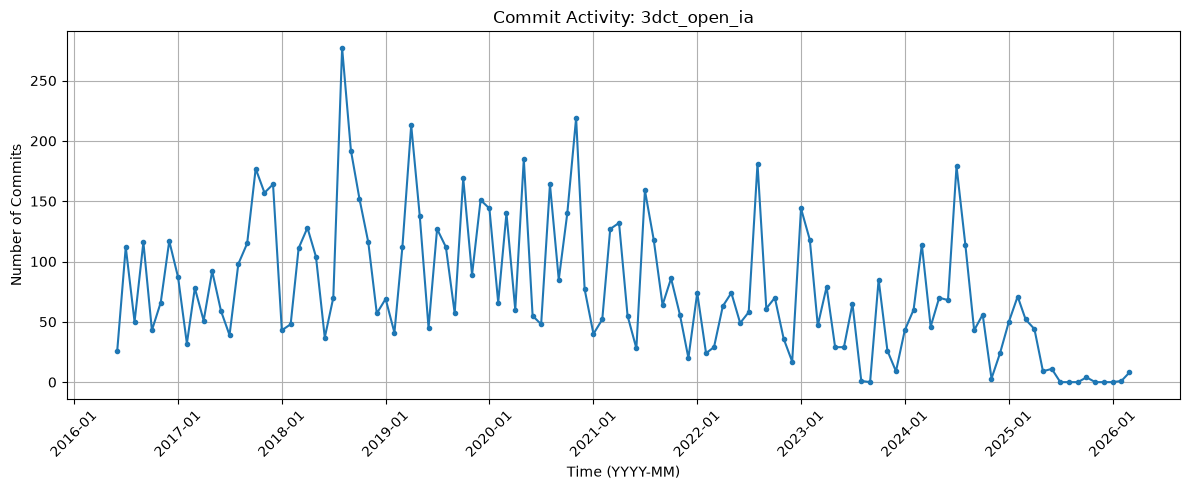

Saved: bpatel_timeseries_3dct_open_ia.png


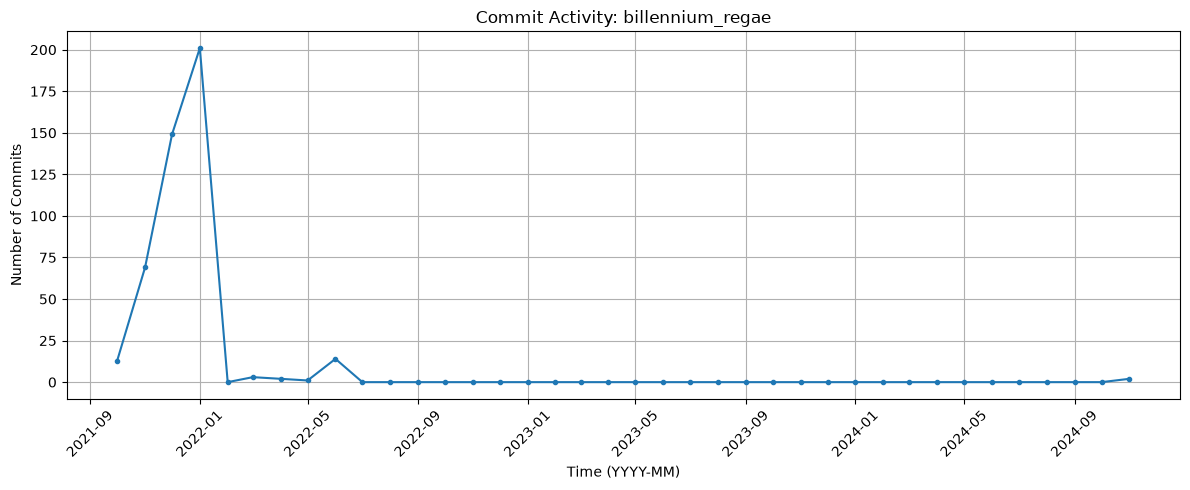

Saved: bpatel_timeseries_billennium_regae.png


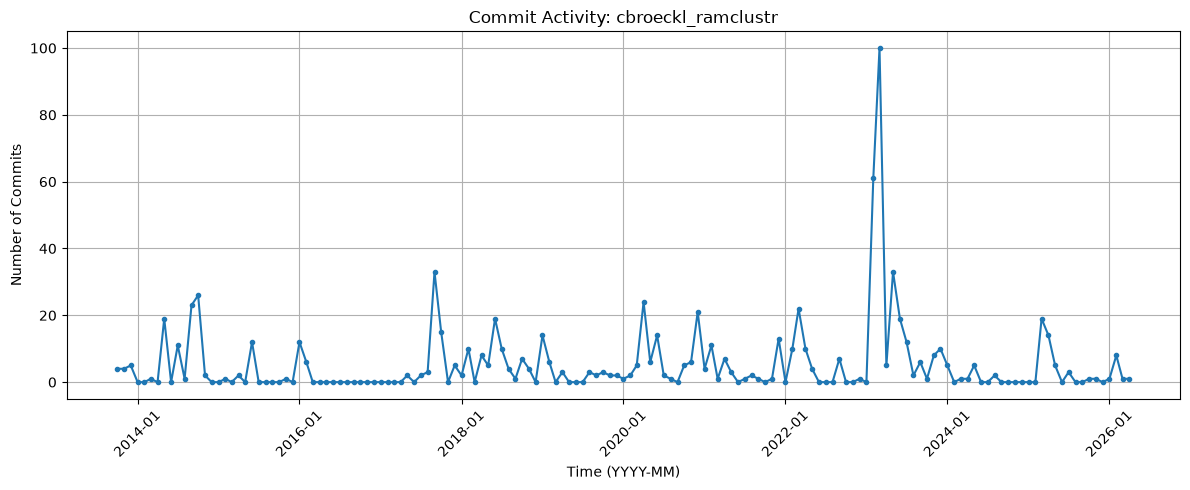

Saved: bpatel_timeseries_cbroeckl_ramclustr.png


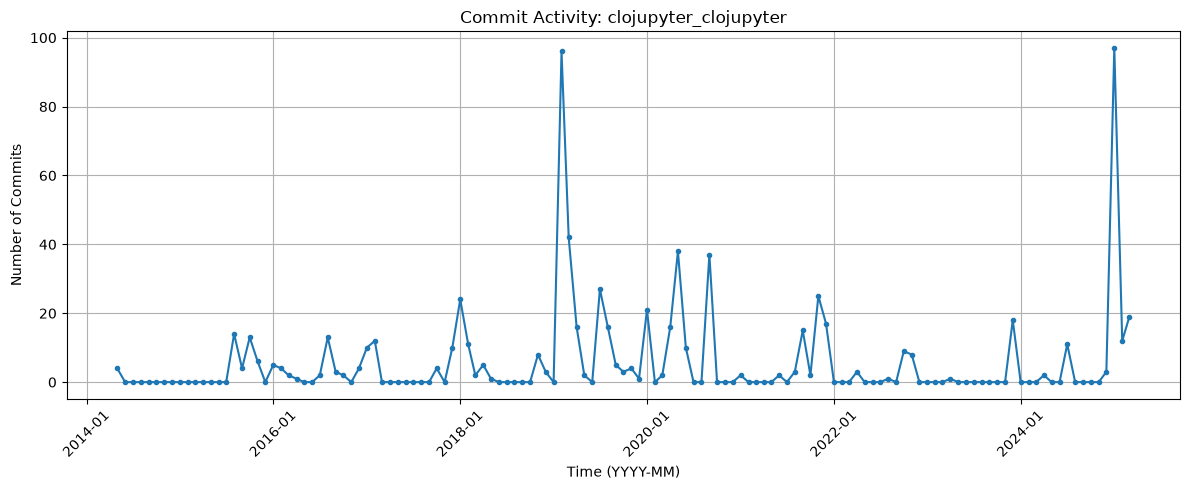

Saved: bpatel_timeseries_clojupyter_clojupyter.png


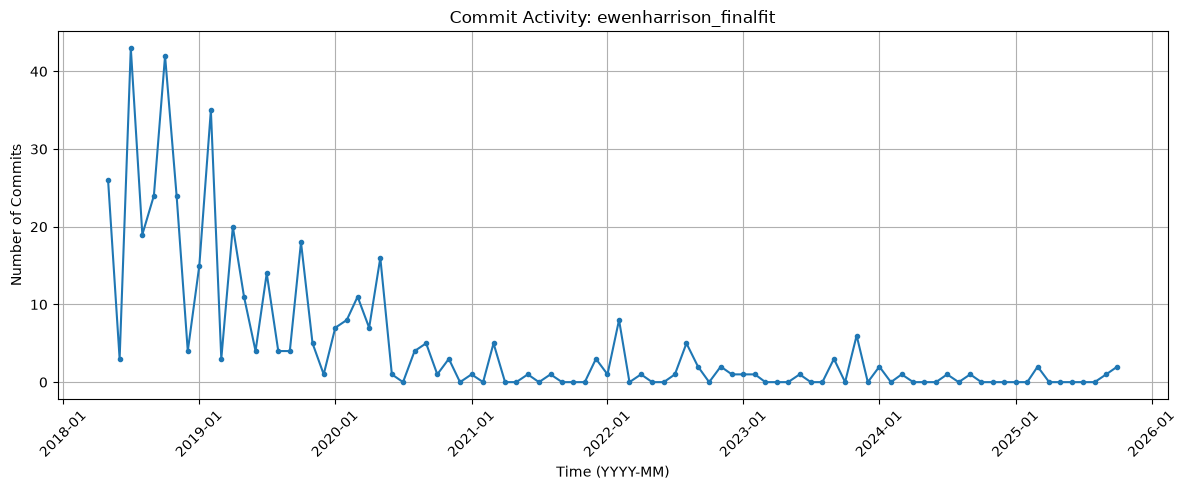

Saved: bpatel_timeseries_ewenharrison_finalfit.png


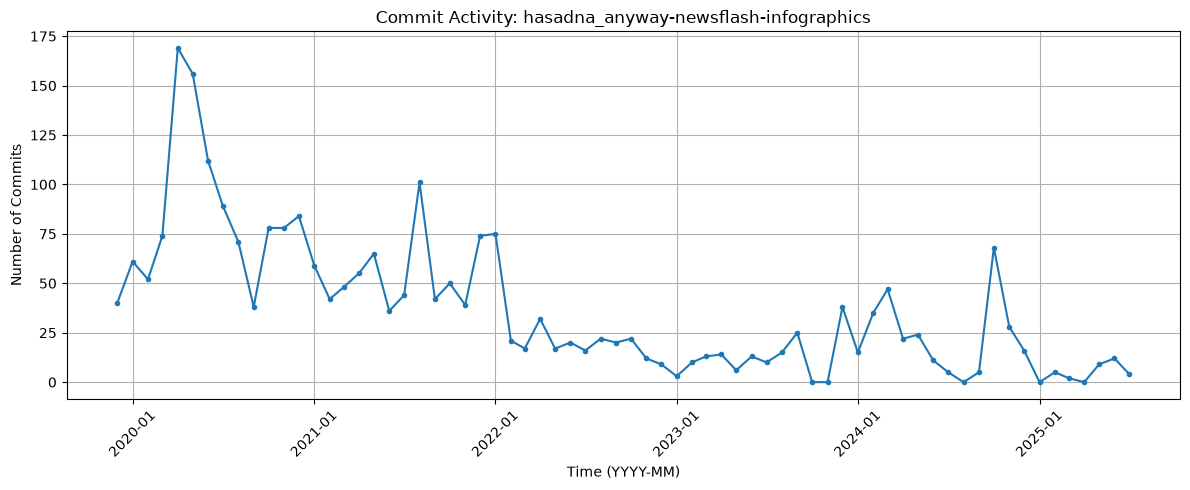

Saved: bpatel_timeseries_hasadna_anyway-newsflash-infographics.png


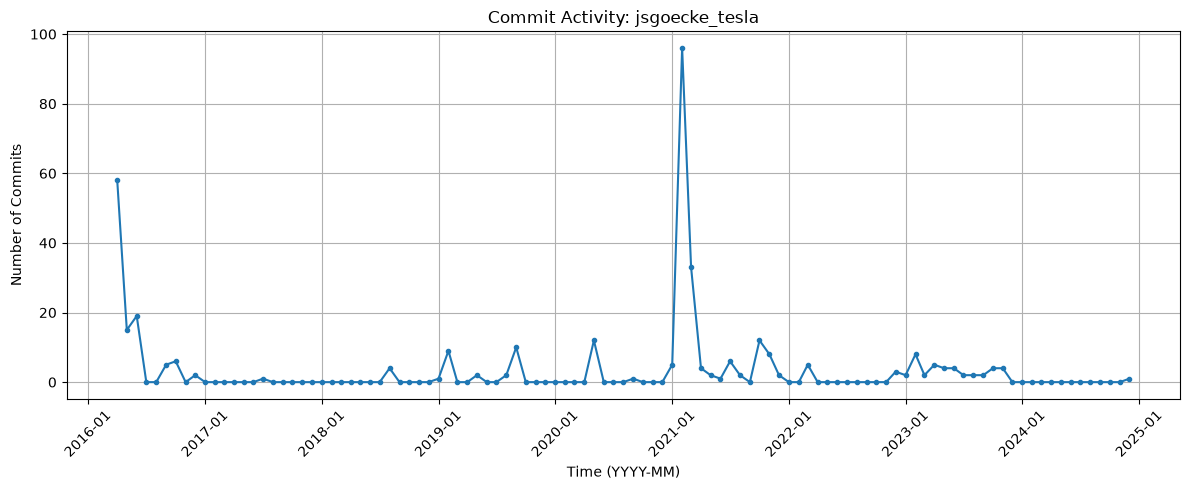

Saved: bpatel_timeseries_jsgoecke_tesla.png


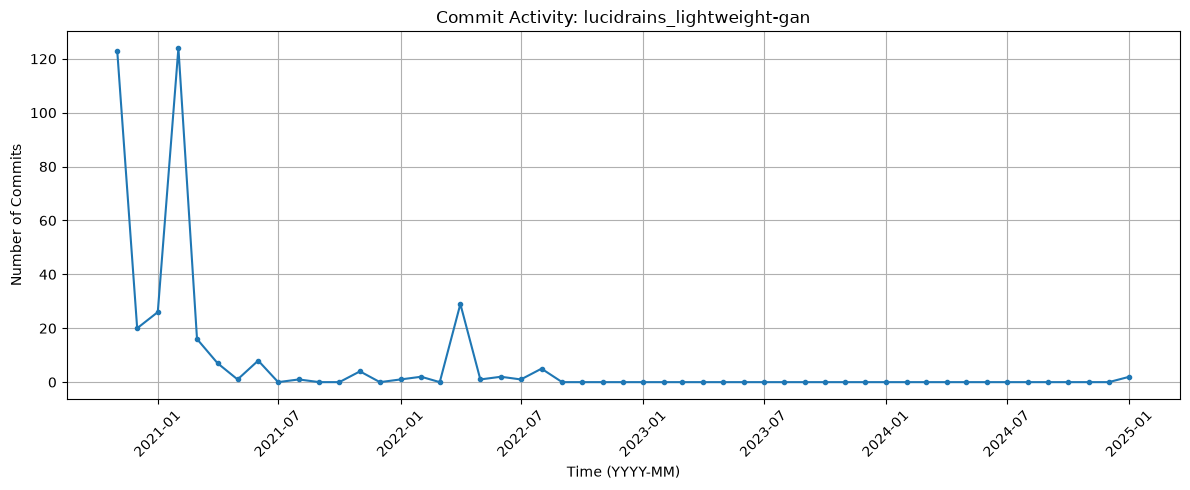

Saved: bpatel_timeseries_lucidrains_lightweight-gan.png


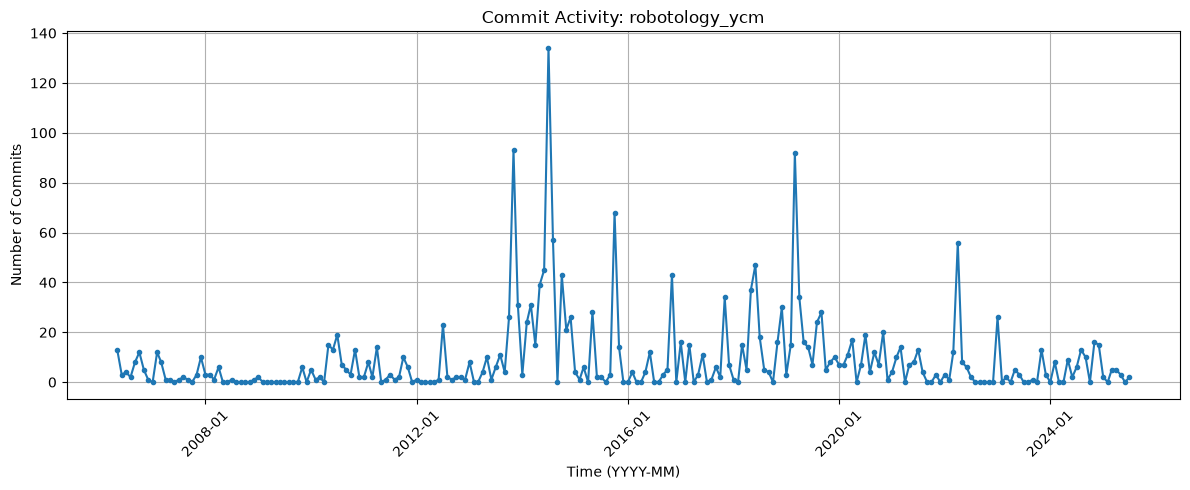

Saved: bpatel_timeseries_robotology_ycm.png


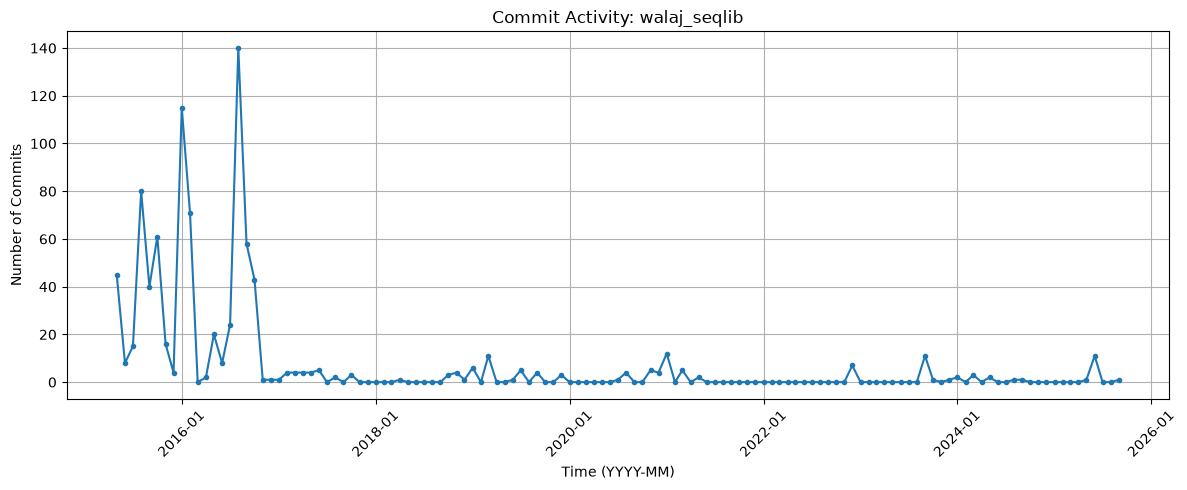

Saved: bpatel_timeseries_walaj_seqlib.png


In [59]:

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Create a line graph for each project
for project, group in monthly_df.groupby("project_wocid"):

    # Convert months to datetime for plotting
    dates = pd.to_datetime(group["Month"])

    plt.figure(figsize=(12, 5))

    plt.plot(
        dates,
        group["#Commits"],
        marker="o",
        linestyle="-",
        markersize=3
    )

    plt.xlabel("Time (YYYY-MM)")
    plt.ylabel("Number of Commits")
    plt.title(f"Commit Activity: {project}")
    plt.grid(True)

    # Format date labels
    ax = plt.gca()
    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

    plt.xticks(rotation=45)
    plt.tight_layout()

    # Save at required resolution
    filename = f"bpatel_timeseries_{project}.png"
    plt.savefig(filename, dpi=300)

    plt.show()
    plt.close()

    print("Saved:", filename)


In [60]:

# Calculate inactivity gaps for each project

gap_results = []

for project, group in monthly_df.groupby("project_wocid"):

    group = group.sort_values("Month").reset_index(drop=True)

    longest_gap = 0
    longest_start = None
    longest_end = None

    current_gap = 0
    current_start = None
    number_of_gaps = 0

    for i, row in group.iterrows():

        if row["#Commits"] == 0:

            if current_gap == 0:
                current_start = row["Month"]

            current_gap += 1

        else:
            # A zero-commit sequence has ended
            if current_gap >= 3:
                number_of_gaps += 1

            if current_gap > longest_gap:
                longest_gap = current_gap
                longest_start = current_start
                longest_end = group.loc[i - 1, "Month"]

            current_gap = 0
            current_start = None

    # Handle a gap that reaches the end of the timeline
    if current_gap > 0:
        if current_gap >= 3:
            number_of_gaps += 1

        if current_gap > longest_gap:
            longest_gap = current_gap
            longest_start = current_start
            longest_end = group.iloc[-1]["Month"]

    # Count commits after the longest gap
    if longest_end is not None:
        commits_after_gap = group.loc[
            group["Month"] > longest_end, "#Commits"
        ].sum()
    else:
        commits_after_gap = 0

    gap_results.append({
        "project": project,
        "LongestGapStart": longest_start,
        "LongestGapEnd": longest_end,
        "LongestGapLength": longest_gap,
        "NumCommitsAfterLastGap": int(commits_after_gap),
        "NumberOfGapsInTimeline": number_of_gaps
    })

gap_df = pd.DataFrame(gap_results)

gap_df


,project,LongestGapStart,LongestGapEnd,LongestGapLength,NumCommitsAfterLastGap,NumberOfGapsInTimeline
0,3dct_open_ia,2025-07,2025-09,3,13,2
1,billennium_regae,2022-07,2024-10,28,2,1
2,cbroeckl_ramclustr,2016-03,2017-04,14,675,5
3,clojupyter_clojupyter,2014-06,2015-07,14,749,11
4,ewenharrison_finalfit,2024-10,2025-02,5,5,5
5,hasadna_anyway-newsflash-infographics,2023-10,2023-11,2,346,0
6,jsgoecke_tesla,2017-08,2018-07,12,260,8
7,lucidrains_lightweight-gan,2022-09,2024-12,28,2,1
8,robotology_ycm,2009-02,2009-10,9,1945,4
9,walaj_seqlib,2021-06,2022-11,18,42,6


In [61]:

# Combine inactivity gaps with WoC statistics
# and GitHub repository statistics

print("Available DataFrames:")
for name, value in globals().copy().items():
    if isinstance(value, pd.DataFrame):
        print(name, value.columns.tolist())


Available DataFrames:
stats ['project;number_of_commits;number_of_authors;max_time;min_time;number_of_stars;number_of_forks;last_commit_date;LongestGapStart;LongestGapEnd;LongestGapLength;NumCommitsAfterLastGap;NumberOfGapsInTimeline;ActivityPattern']
assignments ['netID', 'WoC', 'GH']
_5 ['netID', 'WoC', 'GH']
_7 ['netID', 'WoC', 'GH']
my_projects ['netID', 'WoC', 'GH']
_8 ['netID', 'WoC', 'GH']
temp_df ['sha1', 'project']
df_commits ['sha1', 'project']
_10 ['sha1', 'project']
missing_df ['sha1', 'project']
_14 ['sha1', 'project']
still_missing ['sha1', 'project']
details_df ['project_wocid', 'commit_sha1', 'author', 'time', 'commit message']
_20 ['commit_sha1', 'author', 'time', 'commit message']
_21 ['project_wocid', 'commit_sha1', 'author', 'time', 'commit message']
final_df ['project_wocid', 'commit_sha1', 'author', 'time', 'commit message']
_22 ['project_wocid', 'project_wocid', 'commit_sha1', 'author', 'time', 'commit message']
_23 ['project_wocid', 'commit_sha1', 'author', 'tim

In [76]:

import pandas as pd

# Step 1: Calculate WoC statistics for each project
woc_stats = df.groupby('project_wocid').agg(
    number_of_commits=('commit_sha1', 'count'),
    number_of_authors=('author', 'nunique'),
    max_time=('time', 'max'),
    min_time=('time', 'min')
).reset_index()

# Rename the project column for merging
woc_stats = woc_stats.rename(
    columns={'project_wocid': 'project'}
)

# Step 2: Merge WoC statistics with inactivity gaps
stats_df = woc_stats.merge(
    gap_df,
    on='project',
    how='left',
    validate='one_to_one'
)

# Step 3: Check the result
print("Total projects:", len(stats_df))
print("Columns:", stats_df.columns.tolist())

stats_df.head(10)


Total projects: 10
Columns: ['project', 'number_of_commits', 'number_of_authors', 'max_time', 'min_time', 'LongestGapStart', 'LongestGapEnd', 'LongestGapLength', 'NumCommitsAfterLastGap', 'NumberOfGapsInTimeline']


,project,number_of_commits,number_of_authors,max_time,min_time,LongestGapStart,LongestGapEnd,LongestGapLength,NumCommitsAfterLastGap,NumberOfGapsInTimeline
0,3dct_open_ia,9095,40,1774994202,1464945771,2025-07,2025-09,3,13,2
1,billennium_regae,454,7,1731935108,1634055684,2022-07,2024-10,28,2,1
2,cbroeckl_ramclustr,805,18,1775245947,1382511847,2016-03,2017-04,14,675,5
3,clojupyter_clojupyter,753,48,1742327393,1399620581,2014-06,2015-07,14,749,11
4,ewenharrison_finalfit,436,11,1761574972,1526162607,2024-10,2025-02,5,5,5
5,hasadna_anyway-newsflash-infographics,2495,97,1753562244,1576090079,2023-10,2023-11,2,346,0
6,jsgoecke_tesla,366,32,1733042460,1460485310,2017-08,2018-07,12,260,8
7,lucidrains_lightweight-gan,373,17,1736647889,1605115894,2022-09,2024-12,28,2,1
8,robotology_ycm,2049,47,1752750785,1146563034,2009-02,2009-10,9,1945,4
9,walaj_seqlib,893,24,1758045612,1431016848,2021-06,2022-11,18,42,6


In [77]:

# GitHub statistics from Part 1
github_data = [
    ['ewenharrison_finalfit', 276, 27, '2025-10-27T14:22:57Z'],
    ['lucidrains_lightweight-gan', 1686, 218, '2025-01-12T02:11:34Z'],
    ['walaj_seqlib', 139, 38, '2026-04-27T17:17:42Z'],
    ['3dct_open_ia', 48, 20, '2026-08-28T05:09:51Z'],
    ['clojupyter_clojupyter', 868, 96, '2025-03-18T08:36:00Z'],
    ['billennium_regae', 3, 1, '2024-11-18T13:05:10Z'],
    ['cbroeckl_ramclustr', 13, 18, '2026-04-03T19:52:30Z'],
    ['jsgoecke_tesla', 327, 75, '2024-12-01T08:41:00Z'],
    ['robotology_ycm', 63, 24, '2026-07-24T08:34:38Z'],
    ['hasadna_anyway-newsflash-infographics', 13, 22, '2025-07-10T03:16:55Z']
]

github_df = pd.DataFrame(
    github_data,
    columns=['project', 'number_of_stars',
             'number_of_forks', 'last_commit_date']
)

# Merge GitHub statistics with WoC and gap statistics
stats_df = stats_df.merge(
    github_df,
    on='project',
    how='left',
    validate='one_to_one'
)

print("Total projects:", len(stats_df))
print("Missing GitHub statistics:",
      stats_df['number_of_stars'].isna().sum())

stats_df.head(10)


Total projects: 10
Missing GitHub statistics: 0


,project,number_of_commits,number_of_authors,max_time,min_time,LongestGapStart,LongestGapEnd,LongestGapLength,NumCommitsAfterLastGap,NumberOfGapsInTimeline,number_of_stars,number_of_forks,last_commit_date
0,3dct_open_ia,9095,40,1774994202,1464945771,2025-07,2025-09,3,13,2,48,20,2026-08-28T05:09:51Z
1,billennium_regae,454,7,1731935108,1634055684,2022-07,2024-10,28,2,1,3,1,2024-11-18T13:05:10Z
2,cbroeckl_ramclustr,805,18,1775245947,1382511847,2016-03,2017-04,14,675,5,13,18,2026-04-03T19:52:30Z
3,clojupyter_clojupyter,753,48,1742327393,1399620581,2014-06,2015-07,14,749,11,868,96,2025-03-18T08:36:00Z
4,ewenharrison_finalfit,436,11,1761574972,1526162607,2024-10,2025-02,5,5,5,276,27,2025-10-27T14:22:57Z
5,hasadna_anyway-newsflash-infographics,2495,97,1753562244,1576090079,2023-10,2023-11,2,346,0,13,22,2025-07-10T03:16:55Z
6,jsgoecke_tesla,366,32,1733042460,1460485310,2017-08,2018-07,12,260,8,327,75,2024-12-01T08:41:00Z
7,lucidrains_lightweight-gan,373,17,1736647889,1605115894,2022-09,2024-12,28,2,1,1686,218,2025-01-12T02:11:34Z
8,robotology_ycm,2049,47,1752750785,1146563034,2009-02,2009-10,9,1945,4,63,24,2026-07-24T08:34:38Z
9,walaj_seqlib,893,24,1758045612,1431016848,2021-06,2022-11,18,42,6,139,38,2026-04-27T17:17:42Z


In [78]:

# Compare activity in the first and last thirds
# of each project's timeline

activity_summary = []

for project, group in monthly_df.groupby('project_wocid'):

    # Sort commits by month
    group = group.sort_values('Month')

    # Divide the timeline into three periods
    n = len(group)
    third = max(1, n // 3)

    first_avg = group['#Commits'].iloc[:third].mean()
    middle_avg = group['#Commits'].iloc[third:2*third].mean()
    last_avg = group['#Commits'].iloc[2*third:].mean()

    activity_summary.append({
        'project': project,
        'FirstPeriodAvg': round(first_avg, 2),
        'MiddlePeriodAvg': round(middle_avg, 2),
        'LastPeriodAvg': round(last_avg, 2)
    })

activity_df = pd.DataFrame(activity_summary)

activity_df


,project,FirstPeriodAvg,MiddlePeriodAvg,LastPeriodAvg
0,3dct_open_ia,99.26,89.87,42.98
1,billennium_regae,37.67,0.00,0.14
2,cbroeckl_ramclustr,3.70,4.82,7.43
3,clojupyter_clojupyter,2.40,9.40,5.47
4,ewenharrison_finalfit,12.63,1.23,0.67
5,hasadna_anyway-newsflash-infographics,72.45,23.41,16.08
6,jsgoecke_tesla,3.43,5.66,1.37
7,lucidrains_lightweight-gan,19.59,2.24,0.12
8,robotology_ycm,3.53,14.64,8.44
9,walaj_seqlib,19.02,1.73,0.98


In [79]:

# Step 9: Add activity classifications

activity_patterns = {
    '3dct_open_ia': 'declining',
    'billennium_regae': 'declining',
    'cbroeckl_ramclustr': 'rising',
    'clojupyter_clojupyter': 'irregular',
    'ewenharrison_finalfit': 'declining',
    'hasadna_anyway-newsflash-infographics': 'declining',
    'jsgoecke_tesla': 'irregular',
    'lucidrains_lightweight-gan': 'declining',
    'robotology_ycm': 'irregular',
    'walaj_seqlib': 'declining'
}

# Add ActivityPattern column
stats_df['ActivityPattern'] = stats_df['project'].map(
    activity_patterns
)

# Check results
print("Total projects:", len(stats_df))
print("Missing classifications:",
      stats_df['ActivityPattern'].isna().sum())

stats_df[['project', 'ActivityPattern']]


Total projects: 10
Missing classifications: 0


,project,ActivityPattern
0,3dct_open_ia,declining
1,billennium_regae,declining
2,cbroeckl_ramclustr,rising
3,clojupyter_clojupyter,irregular
4,ewenharrison_finalfit,declining
5,hasadna_anyway-newsflash-infographics,declining
6,jsgoecke_tesla,irregular
7,lucidrains_lightweight-gan,declining
8,robotology_ycm,irregular
9,walaj_seqlib,declining


In [80]:

# Arrange columns according to assignment requirements
columns = [
    'project',
    'number_of_commits',
    'number_of_authors',
    'max_time',
    'min_time',
    'number_of_stars',
    'number_of_forks',
    'last_commit_date',
    'LongestGapStart',
    'LongestGapEnd',
    'LongestGapLength',
    'NumCommitsAfterLastGap',
    'NumberOfGapsInTimeline',
    'ActivityPattern'
]

# Select and arrange the columns
final_stats = stats_df[columns].copy()

# Save CSV using semicolon separator
final_stats.to_csv(
    'bpatel_project_stats.csv',
    sep=';',
    index=False
)

# Verify the file
check_stats = pd.read_csv(
    'bpatel_project_stats.csv',
    sep=';'
)

print("File saved: bpatel_project_stats.csv")
print("Shape:", check_stats.shape)
print("Missing activity patterns:",
      check_stats['ActivityPattern'].isna().sum())

check_stats.head(10)


File saved: bpatel_project_stats.csv
Shape: (10, 14)
Missing activity patterns: 0


,project,number_of_commits,number_of_authors,max_time,min_time,number_of_stars,number_of_forks,last_commit_date,LongestGapStart,LongestGapEnd,LongestGapLength,NumCommitsAfterLastGap,NumberOfGapsInTimeline,ActivityPattern
0,3dct_open_ia,9095,40,1774994202,1464945771,48,20,2026-08-28T05:09:51Z,2025-07,2025-09,3,13,2,declining
1,billennium_regae,454,7,1731935108,1634055684,3,1,2024-11-18T13:05:10Z,2022-07,2024-10,28,2,1,declining
2,cbroeckl_ramclustr,805,18,1775245947,1382511847,13,18,2026-04-03T19:52:30Z,2016-03,2017-04,14,675,5,rising
3,clojupyter_clojupyter,753,48,1742327393,1399620581,868,96,2025-03-18T08:36:00Z,2014-06,2015-07,14,749,11,irregular
4,ewenharrison_finalfit,436,11,1761574972,1526162607,276,27,2025-10-27T14:22:57Z,2024-10,2025-02,5,5,5,declining
5,hasadna_anyway-newsflash-infographics,2495,97,1753562244,1576090079,13,22,2025-07-10T03:16:55Z,2023-10,2023-11,2,346,0,declining
6,jsgoecke_tesla,366,32,1733042460,1460485310,327,75,2024-12-01T08:41:00Z,2017-08,2018-07,12,260,8,irregular
7,lucidrains_lightweight-gan,373,17,1736647889,1605115894,1686,218,2025-01-12T02:11:34Z,2022-09,2024-12,28,2,1,declining
8,robotology_ycm,2049,47,1752750785,1146563034,63,24,2026-07-24T08:34:38Z,2009-02,2009-10,9,1945,4,irregular
9,walaj_seqlib,893,24,1758045612,1431016848,139,38,2026-04-27T17:17:42Z,2021-06,2022-11,18,42,6,declining


In [81]:
import pandas as pd

stats = pd.read_csv("bpatel_project_stats.csv", sep=";")

print(stats.columns.tolist())

['project', 'number_of_commits', 'number_of_authors', 'max_time', 'min_time', 'number_of_stars', 'number_of_forks', 'last_commit_date', 'LongestGapStart', 'LongestGapEnd', 'LongestGapLength', 'NumCommitsAfterLastGap', 'NumberOfGapsInTimeline', 'ActivityPattern']


In [82]:
import pandas as pd

# Load the project statistics
stats = pd.read_csv("bpatel_project_stats.csv", sep=";")

# Load all commits
commits = pd.read_csv("bpatel_project_summary.csv", sep=";")

# Verify column names
print("Stats columns:", stats.columns.tolist())
print("Commits columns:", commits.columns.tolist())

Stats columns: ['project', 'number_of_commits', 'number_of_authors', 'max_time', 'min_time', 'number_of_stars', 'number_of_forks', 'last_commit_date', 'LongestGapStart', 'LongestGapEnd', 'LongestGapLength', 'NumCommitsAfterLastGap', 'NumberOfGapsInTimeline', 'ActivityPattern']
Commits columns: ['project_wocid', 'commit_sha1', 'author', 'time', 'commit message']


In [83]:
# Loop through each project in the statistics file
for _, project in stats.iterrows():

    # Get the project name
    project_id = project["project"]

    # Find all commits for this project
    project_data = commits[
        commits["project_wocid"] == project_id
    ].copy()

    print(project_id, len(project_data))

3dct_open_ia 9095
billennium_regae 454
cbroeckl_ramclustr 805
clojupyter_clojupyter 753
ewenharrison_finalfit 436
hasadna_anyway-newsflash-infographics 2495
jsgoecke_tesla 366
lucidrains_lightweight-gan 373
robotology_ycm 2049
walaj_seqlib 893


In [84]:
import pandas as pd

stats = pd.read_csv("bpatel_project_stats.csv", sep=";")
commits = pd.read_csv("bpatel_project_summary.csv", sep=";")

print("Stats columns:", stats.columns.tolist())
print("Commits columns:", commits.columns.tolist())

print("\nFirst project:")
print(stats.iloc[0]["project"])

Stats columns: ['project', 'number_of_commits', 'number_of_authors', 'max_time', 'min_time', 'number_of_stars', 'number_of_forks', 'last_commit_date', 'LongestGapStart', 'LongestGapEnd', 'LongestGapLength', 'NumCommitsAfterLastGap', 'NumberOfGapsInTimeline', 'ActivityPattern']
Commits columns: ['project_wocid', 'commit_sha1', 'author', 'time', 'commit message']

First project:
3dct_open_ia


In [86]:

import pandas as pd

# Load the commit data from Part 1
commits = pd.read_csv(
    "bpatel_project_summary.csv",
    sep=";"
)

# Load the project statistics from Part 2
stats = pd.read_csv("bpatel_project_stats.csv", sep=";")

# Convert Unix timestamps into dates
commits["date"] = pd.to_datetime(
    commits["time"], unit="s", utc=True
)

# Store commits before and after the gaps
gap_commits = []

for _, project in stats.iterrows():

    project_id = project["project"]

    # Find all commits for this project
    project_data = commits[
        commits["project_wocid"] == project_id
    ].copy()

    project_data = project_data.sort_values("date")

    # Get the longest gap boundaries
    gap_start = pd.to_datetime(
        project["LongestGapStart"]
    )

    gap_end = pd.to_datetime(
        project["LongestGapEnd"]
    )

    # First day of the month when inactivity begins
    gap_start = gap_start.tz_localize("UTC")

    # First day of the month after inactivity ends
    gap_end = (
        gap_end + pd.offsets.MonthBegin(1)
    ).tz_localize("UTC")

    # Last 10 commits before the gap
    before = project_data[
        project_data["date"] < gap_start
    ].tail(10).copy()

    before["pre/post"] = "pre"

    # First 10 commits after the gap
    after = project_data[
        project_data["date"] >= gap_end
    ].head(10).copy()

    after["pre/post"] = "post"

    gap_commits.extend([before, after])

# Combine all projects
gap_commits_df = pd.concat(
    gap_commits, ignore_index=True
)

# Keep the columns required by the professor
gap_commits_df = gap_commits_df[
    [
        "pre/post",
        "project_wocid",
        "commit_sha1",
        "author",
        "time",
        "commit message"
    ]
]

# Save the CSV
gap_commits_df.to_csv(
    "bpatel_project_gap_commits.csv",
    sep=";",
    index=False
)

print("File saved: bpatel_project_gap_commits.csv")
print("Total rows:", len(gap_commits_df))

display(gap_commits_df.head())


File saved: bpatel_project_gap_commits.csv
Total rows: 173


,pre/post,project_wocid,commit_sha1,author,time,commit message
0,pre,3dct_open_ia,35156dd98313070b330c7ed007c04827284f79b1,Bernhard Froehler <bernhard.froehler@fh-wels.at>,1749544318,gui: Fix toolbar names\n
1,pre,3dct_open_ia,be6ab635c05717932c78943f4d097acfa059877e,Bernhard Froehler <bernhard.froehler@fh-wels.at>,1749558856,gui: Improve reset layout tooltip\n
2,pre,3dct_open_ia,125e924959fa9bbefbec38e06a1681a3bb7a9f40,Bernhard Froehler <bernhard.froehler@fh-wels.at>,1749559121,VolumePlayer: Fix potential crashes (cell colo...
3,pre,3dct_open_ia,2f40b338b1f1dd7100972ae407aa9d7e0e6a06a6,Bernhard Froehler <bernhard.froehler@fh-wels.at>,1749562205,VolumePlayer: Refactor to use iADockWidgetWrap...
4,pre,3dct_open_ia,a9b82eee05b610f1fa8c47354258756586007bea,Bernhard Froehler <bernhard.froehler@fh-wels.at>,1749562281,FeatureScout: Remove unused include/fwd declar...


In [87]:
print(
    gap_commits_df.groupby(
        ["project_wocid", "pre/post"]
    ).size().unstack(fill_value=0)
)

pre/post                               post  pre
project_wocid                                   
3dct_open_ia                             10   10
billennium_regae                          2   10
cbroeckl_ramclustr                       10   10
clojupyter_clojupyter                    10    4
ewenharrison_finalfit                     5   10
hasadna_anyway-newsflash-infographics    10   10
jsgoecke_tesla                           10   10
lucidrains_lightweight-gan                2   10
robotology_ycm                           10   10
walaj_seqlib                             10   10


In [88]:
for project_id, group in gap_commits_df.groupby("project_wocid"):
    print("\nPROJECT:", project_id)

    for period in ["pre", "post"]:
        print("\n", period.upper(), "GAP COMMITS")

        messages = group.loc[
            group["pre/post"] == period,
            "commit message"
        ]

        for message in messages:
            print("-", str(message).strip())

    print("=" * 60)


PROJECT: 3dct_open_ia

 PRE GAP COMMITS
- gui: Fix toolbar names
- gui: Improve reset layout tooltip
- VolumePlayer: Fix potential crashes (cell coloring, comment-out not implemented blending)
- VolumePlayer: Refactor to use iADockWidgetWrapper
- FeatureScout: Remove unused include/fwd declaration
- gui: Remove slicer settings dialog (available via Views menu)
- FeatureScout: Proper name for 'FeatureScout Toolbar'
- manifest: 2025.6.rc2, add untested modules note
- ci: OpenXR -> 1.1.48 in github actions build
- Fix doxygen version number

 POST GAP COMMITS
- Minor fix discrete surface filter
- Add surface reconstruction filter
- CMake: More MSVC environment information
- Surfaces: Discrete Extraction
- Refactor: Move image I/O to io lib
- Fix includes on Windows/Debug (duplicate iAitkImageTypes.h only with different case)
- Qt nodiscard warnings -> error checks
- VTK Fix Actor2D -> ViewProp deprecation warning
- Replace std::cerr with LOG
- VTK: Fix warning Allocate(...EstimateSize) -

In [89]:
project_messages = gap_commits_df[
    (gap_commits_df["project_wocid"] == "3dct_open_ia") &
    (gap_commits_df["pre/post"] == "post")
]

for message in project_messages["commit message"]:
    print("-", message.strip())

- Minor fix discrete surface filter
- Add surface reconstruction filter
- CMake: More MSVC environment information
- Surfaces: Discrete Extraction
- Refactor: Move image I/O to io lib
- Fix includes on Windows/Debug (duplicate iAitkImageTypes.h only with different case)
- Qt nodiscard warnings -> error checks
- VTK Fix Actor2D -> ViewProp deprecation warning
- Replace std::cerr with LOG
- VTK: Fix warning Allocate(...EstimateSize) -> AllocateEstimate


In [90]:
# Update themes for Project 1
stats.loc[
    stats["project"] == "3dct_open_ia",
    "BeforeThemes"
] = "Bug fixes:Other"

stats.loc[
    stats["project"] == "3dct_open_ia",
    "AfterThemes"
] = "Bug fixes:Other"

# Verify the results
display(
    stats.loc[
        stats["project"] == "3dct_open_ia",
        ["project", "BeforeThemes", "AfterThemes"]
    ]
)

,project,BeforeThemes,AfterThemes
0,3dct_open_ia,Bug fixes:Other,Bug fixes:Other


In [91]:
project_messages = gap_commits_df[
    gap_commits_df["project_wocid"] == "billennium_regae"
]

for period in ["pre", "post"]:
    print("\n", period.upper(), "GAP COMMITS")

    messages = project_messages.loc[
        project_messages["pre/post"] == period,
        "commit message"
    ]

    for message in messages:
        print("-", str(message).strip())


 PRE GAP COMMITS
- add wrapper to autoencoder
- Update README.md
- add missed inints
- update setup.py
- add more specific comments to the RGAE wrapper
- Fix indent in RGAE comment
- Create LICENSE
- Update README.md
- Update setup.py
- Update README.md

 POST GAP COMMITS
- Add download data scripts and mutag experiment
- Add mutag to guild; update readme


In [92]:
# Update themes for Project 2
stats.loc[
    stats["project"] == "billennium_regae",
    "BeforeThemes"
] = "Documentation updates:Feature development"

stats.loc[
    stats["project"] == "billennium_regae",
    "AfterThemes"
] = "Feature development:Documentation updates"

# Verify
display(
    stats.loc[
        stats["project"] == "billennium_regae",
        ["project", "BeforeThemes", "AfterThemes"]
    ]
)

,project,BeforeThemes,AfterThemes
1,billennium_regae,Documentation updates:Feature development,Feature development:Documentation updates


In [93]:
project_messages = gap_commits_df[
    gap_commits_df["project_wocid"] == "cbroeckl_ramclustr"
]

for period in ["pre", "post"]:
    print("\n", period.upper(), "GAP COMMITS")

    messages = project_messages.loc[
        project_messages["pre/post"] == period,
        "commit message"
    ]

    for message in messages:
        print("-", str(message).strip())


 PRE GAP COMMITS
- Merge remote-tracking branch 'origin/master'

# Conflicts:
#	NAMESPACE
- Update ramclustR2.R
- Update ramclustR2.R

retention time adjustment function was failing in certain instances when the number of scans from one file to the next was different.  Filled NA values with zero values as a fix for now - this is only likely to impact the data at the very end of the chromatogram.
- Update ramclustR2.R
- Update ramclustR2.R
- Update ramclustR2.R
- Update ramclustR2.R

trying to fix 'from<' NA bug.  
Only finish fill EIC loop if 'from' is not NA
- Update ramclustR2.R
- Update ramclustR2.R
- Update ramclustR2.R

 POST GAP COMMITS
- fix module size =1 error
- fix module size = 1 bug
- Update README.md
- Update README.md
- Merge branch 'master' into master
- Merge pull request #7 from cbroeckl/master

Hi, I had to fix a few merge conflicts, and will now make sure that R CMD check 
finishes without WARNINGS. Yours, Steffen
- Get rid of R CMD check WARNINGS, two documentation

In [94]:
# Update themes for Project 3
stats.loc[
    stats["project"] == "cbroeckl_ramclustr",
    "BeforeThemes"
] = "Bug fixes:Other"

stats.loc[
    stats["project"] == "cbroeckl_ramclustr",
    "AfterThemes"
] = "Bug fixes:Documentation updates"

# Verify
display(
    stats.loc[
        stats["project"] == "cbroeckl_ramclustr",
        ["project", "BeforeThemes", "AfterThemes"]
    ]
)

,project,BeforeThemes,AfterThemes
2,cbroeckl_ramclustr,Bug fixes:Other,Bug fixes:Documentation updates


In [95]:
project_messages = gap_commits_df[
    gap_commits_df["project_wocid"] == "clojupyter_clojupyter"
]

for period in ["pre", "post"]:
    print("\n", period.upper(), "GAP COMMITS")

    messages = project_messages.loc[
        project_messages["pre/post"] == period,
        "commit message"
    ]

    for message in messages:
        print("-", str(message).strip())


 PRE GAP COMMITS
- Initial commit.
- Cleanup cruft.
- Make demo bigger.
- Cleanup of cruft.

 POST GAP COMMITS
- Address zeromq import issue.

Partial work towards #1.
- First commit for jupyter support.

Added sha256-hmac checking of messages.
- Implemented signing our messages.
- jupyter as functional as before
- Updated installer.

Installer now puts the executable and tells IPython where
to find it so the user don't have to do any configuration
other than type make.
- Add missing kernel.json.

Thanks to @thomasjm for pointing it out.
- update with name-change to clojupyter
- Update with clojupyter documentation.
- clojupyter-specific instructions
- Instructions for how to run the console/notebook


In [101]:
# Project 5: ewenharrison_finalfit

stats.loc[
    stats["project"] == "ewenharrison_finalfit",
    "BeforeThemes"
] = "Bug fixes:Release"

stats.loc[
    stats["project"] == "ewenharrison_finalfit",
    "AfterThemes"
] = "Release:Feature development"

# Display the updated themes
display(
    stats.loc[
        stats["project"] == "ewenharrison_finalfit",
        ["project", "BeforeThemes", "AfterThemes"]
    ]
)

,project,BeforeThemes,AfterThemes
4,ewenharrison_finalfit,Bug fixes:Release,Release:Feature development


In [102]:
project_id = "ewenharrison_finalfit"

for period in ["pre", "post"]:
    print(f"\n{period.upper()} GAP COMMITS")

    messages = gap_commits_df[
        (gap_commits_df["project_wocid"] == project_id) &
        (gap_commits_df["pre/post"] == period)
    ]["commit message"]

    for message in messages:
        print("-", message)


PRE GAP COMMITS
- fct_explicit_na() changed to fct_na_value_to_level()

- Fix fct_explicit_na()

- Missing compare correction

- 1.07 to CRAN

- #58

- Create boprize123
- Merge 9700137ecab8419e968374c13ce7b50b9fc6e6b3 into 2e043058091f1b63c44eb0a0ab0e917dd3e54682

- 1.0.72

- 1.0.8

- news update


POST GAP COMMITS
- 1.08

- 1.0.9

- 1.1.0 with plot updates after breaking changes

- #110

- No more travis


In [103]:
project_id = "hasadna_anyway-newsflash-infographics"

for period in ["pre", "post"]:
    print(f"\n{period.upper()} GAP COMMITS")

    messages = gap_commits_df[
        (gap_commits_df["project_wocid"] == project_id) &
        (gap_commits_df["pre/post"] == period)
    ]["commit message"]

    for message in messages:
        print("-", message)


PRE GAP COMMITS
- Delete src/assets/hasadna.png (#989)


- Merge branch 'master' into dev
- merge dev into master (#987)

* [Feat-885] Add selection for stack bar graphs (#935)

* Added stacked bar widgets a checkbox option

* Add option to choose colors when changing displayed bars

* Changed any to proper type, make number of bar generic and add function createBarWidget

* Fix bug of changed values when closing card editor

* PR review changes

* Remove redundent imports

* add conditional label, refactor utils (#938)

Co-authored-by: Daniel Shely <>

* Update .env.staging (#947)

* Add critical indication (#948)

* Added image

* Added critical icon based on field value

* Added critical option to the filter panel

* Added enum value

* Had to increase width

* Added local critical filter

* Added field to model

* add alt attrinbte on image tag (#951)

* Update .env.staging (#952)

* Make critical filter non local (#958)

* sufficient condition

* Use object for fetch args

* Send

In [104]:
project_id = "hasadna_anyway-newsflash-infographics"

post_commits = gap_commits_df[
    (gap_commits_df["project_wocid"] == project_id) &
    (gap_commits_df["pre/post"] == "post")
]

print("POST GAP COMMITS")

for message in post_commits["commit message"]:
    print("-", message)

POST GAP COMMITS
- Add check for user authentication in NewsFlash (#990)

- Added style changes to CountInjuredByYearBarWidget and CountByYearBarWidget

- first try button

- Update Node.js version to 18.x in GitHub Actions workflow

- Revert Node.js version to 16.x in CI workflow to fix OpenSSL issue

- Change design in bar widgets

- Spliting title and subtitle, making title bold

- Change node version to 18

- Spliting title and subtitle, making title bold (#995)


- Change design in bar widgets (#996)




In [105]:
# Project 6: hasadna_anyway-newsflash-infographics

stats.loc[
    stats["project"] == "hasadna_anyway-newsflash-infographics",
    "BeforeThemes"
] = "Feature development:Bug fixes"

stats.loc[
    stats["project"] == "hasadna_anyway-newsflash-infographics",
    "AfterThemes"
] = "Feature development:Dependency updates"

# Display updated themes
display(
    stats.loc[
        stats["project"] == "hasadna_anyway-newsflash-infographics",
        ["project", "BeforeThemes", "AfterThemes"]
    ]
)

,project,BeforeThemes,AfterThemes
5,hasadna_anyway-newsflash-infographics,Feature development:Bug fixes,Feature development:Dependency updates


In [106]:
project_id = "jsgoecke_tesla"

for period in ["pre", "post"]:
    print(f"\n{period.upper()} GAP COMMITS")

    messages = gap_commits_df[
        (gap_commits_df["project_wocid"] == project_id) &
        (gap_commits_df["pre/post"] == period)
    ]["commit message"]

    for message in messages:
        print("-", message)


PRE GAP COMMITS
- added simple homelink support

- More work on autopark and homelink.

- Made the web socket API use a callback interface instead of getters.

- Removed redundant and broken code.

- Fixed typo. Accepting non-bools as IsFrontDefrosterOn (it happened to be an int, once?).

- Made the set_temps command a POST.

- Merge f91743db99a1a459ad2a8ea7411546bf5ab9e7c0 into 23ed2fa3dbab896120b46602cc6faedf23e66fcd

- ClimateState is_front_defroster_on is an integer value. Adding some new fields for ClimateState as well.

- Merge 4d206e6c9f10b64b56544ef8b7b87d7a31bbb258 into 23ed2fa3dbab896120b46602cc6faedf23e66fcd

- Optional custom http client


POST GAP COMMITS
- Fixed so JSON will encode

- Merge cc2495329ec1ffe608d80493ab22b0a13c596b10 into 23ed2fa3dbab896120b46602cc6faedf23e66fcd

- allow token reuse

- Merge 558e4ed6d8beb84adac095a895d0925594094cf7 into 23ed2fa3dbab896120b46602cc6faedf23e66fcd

- Merge pull request #1 from jnoxon/master

allow token reuse
- Merge pull reque

In [108]:
stats.loc[
    stats["project"] == "jsgoecke_tesla",
    "BeforeThemes"
] = "Feature development:Bug fixes"

stats.loc[
    stats["project"] == "jsgoecke_tesla",
    "AfterThemes"
] = "Feature development:Bug fixes"

# Check the result
display(
    stats.loc[
        stats["project"] == "jsgoecke_tesla",
        ["project", "BeforeThemes", "AfterThemes"]
    ]
)

,project,BeforeThemes,AfterThemes
6,jsgoecke_tesla,Feature development:Bug fixes,Feature development:Bug fixes


In [109]:

project_id = "lucidrains_lightweight-gan"

project_commits = gap_commits_df[
    gap_commits_df["project_wocid"] == project_id
]

print("PRE GAP COMMITS")
for msg in project_commits[
    project_commits["pre/post"] == "pre"
]["commit message"]:
    print("-", msg)

print("\nPOST GAP COMMITS")
for msg in project_commits[
    project_commits["pre/post"] == "post"
]["commit message"]:
    print("-", msg)


PRE GAP COMMITS
- revert, as attention based upsampler not working well

- Add TIFF to list of file extensions

- Add TIFF to list of file extensions (#129)


- 0.23.3
- another measure against checkboard artifacts, release 1.0.0

- Update cli.py

Including args "user_aim" to "model_args"
- Update cli.py

Letting user use --generate, --generate-interpolation and --show-progress without installing Aim
- upgrade to best downsample type

- Update cli.py (#137)

Letting user use --generate, --generate-interpolation and --show-progress without installing Aim
- aim fix


POST GAP COMMITS
- add zero centered gradient penalty for real and fake images

- update dep versions



In [110]:

# Project 8: lucidrains_lightweight-gan

stats.loc[
    stats["project"] == "lucidrains_lightweight-gan",
    "BeforeThemes"
] = "Feature development:Bug fixes"

stats.loc[
    stats["project"] == "lucidrains_lightweight-gan",
    "AfterThemes"
] = "Feature development:Dependency updates"

# Check the result
display(
    stats.loc[
        stats["project"] == "lucidrains_lightweight-gan",
        ["project", "BeforeThemes", "AfterThemes"]
    ]
)


,project,BeforeThemes,AfterThemes
7,lucidrains_lightweight-gan,Feature development:Bug fixes,Feature development:Dependency updates


In [111]:

project_id = "robotology_ycm"

project_commits = gap_commits_df[
    gap_commits_df["project_wocid"] == project_id
]

print("PRE GAP COMMITS")
for msg in project_commits[
    project_commits["pre/post"] == "pre"
]["commit message"]:
    print("-", msg)

print("\nPOST GAP COMMITS")
for msg in project_commits[
    project_commits["pre/post"] == "post"
]["commit message"]:
    print("-", msg)


PRE GAP COMMITS
- prioritize ACE_ROOT


- externalmodules problem


- ffmpeg search order


- ffmpeg search order


- ffmpeg search order


- ffmpeg search order


- yet more possibilities


- 

- 

- 


POST GAP COMMITS
- remove YARP1 option from compilation


- Added FindAtlas.cmake file and slightly modified example/math/benchmark.cpp.



- add licenses to some cmake files


- another batch of author/license/copyright lines

- pass along gtk library path


- use built-in cmake pkg-config helpers when available


- link pthread explicitly on linux


- more debug information


- better control over building ace in


- report builtin locations




In [112]:

# Project 9: robotology_ycm

stats.loc[
    stats["project"] == "robotology_ycm",
    "BeforeThemes"
] = "Bug fixes:Other"

stats.loc[
    stats["project"] == "robotology_ycm",
    "AfterThemes"
] = "Feature development:Documentation updates"

# Check the result
display(
    stats.loc[
        stats["project"] == "robotology_ycm",
        ["project", "BeforeThemes", "AfterThemes"]
    ]
)


,project,BeforeThemes,AfterThemes
8,robotology_ycm,Bug fixes:Other,Feature development:Documentation updates


In [113]:

project_id = "walaj_seqlib"

project_commits = gap_commits_df[
    gap_commits_df["project_wocid"] == project_id
]

print("PRE GAP COMMITS")
for msg in project_commits[
    project_commits["pre/post"] == "pre"
]["commit message"]:
    print("-", msg)

print("\nPOST GAP COMMITS")
for msg in project_commits[
    project_commits["pre/post"] == "post"
]["commit message"]:
    print("-", msg)


PRE GAP COMMITS
- updated Doxygen file

- updated Doxygen file

- initial commit

- Add BamReader::GetRegionIdx

- Merge branch 'master' of github.com:walaj/SeqLib

- Remove a couple new htslib build references

- Merge db79b509bc97474e36d8b28486b51395bfadc635 into 35c9ec5edb53c4afdbc60c09a5f748571c294c13

- updated travis build to install htslib

- Add LastFlag() to BamRecord

Checks if 0x80 bit is set to indicate the last segment in the template

- Merge 357267e694928dc15ea5ef6c3c57c0d1973c8b98 into 35c9ec5edb53c4afdbc60c09a5f748571c294c13


POST GAP COMMITS
- Get rid of all submodules

- Add updated fermi-lite submodule

- Update BWA submodule

- Update fermi-lite submodule again

We can't use Heng Li's latest, since Jeremiah made some changes to it.

- Merge f9c934e55b54c9c3d5475b64cef411a9b89394c3 into 1616f2860395c26ad8b014f703c6e84902e78b8d

- Merge pull request #65 from harvardinformatics/lastread

Add LastFlag() to BamRecord
- Merge db79b509bc97474e36d8b28486b51395bfadc635 int

In [114]:

# Project 10: walaj_seqlib

stats.loc[
    stats["project"] == "walaj_seqlib",
    "BeforeThemes"
] = "Feature development:Documentation updates"

stats.loc[
    stats["project"] == "walaj_seqlib",
    "AfterThemes"
] = "Dependency updates:Feature development"

# Check the result
display(
    stats.loc[
        stats["project"] == "walaj_seqlib",
        ["project", "BeforeThemes", "AfterThemes"]
    ]
)


,project,BeforeThemes,AfterThemes
9,walaj_seqlib,Feature development:Documentation updates,Dependency updates:Feature development


In [115]:

# Save updated project statistics
stats.to_csv(
    "bpatel_project_stats.csv",
    sep=";",
    index=False
)

print("File saved: bpatel_project_stats.csv")
print("Total projects:", len(stats))
print("Missing BeforeThemes:", stats["BeforeThemes"].isna().sum())
print("Missing AfterThemes:", stats["AfterThemes"].isna().sum())


File saved: bpatel_project_stats.csv
Total projects: 10
Missing BeforeThemes: 0
Missing AfterThemes: 0


In [116]:

# Part 4 - Project 1: 3dct_open_ia

project_id = "3dct_open_ia"

# Display the project's gap statistics
display(
    stats.loc[
        stats["project"] == project_id,
        [
            "project",
            "LongestGapStart",
            "LongestGapEnd",
            "LongestGapLength",
            "NumCommitsAfterLastGap",
            "ActivityPattern",
            "last_commit_date"
        ]
    ]
)

# Display commit authors before and after the gap
project_commits = gap_commits_df[
    gap_commits_df["project_wocid"] == project_id
]

print("AUTHORS BEFORE GAP:")
print(
    project_commits[
        project_commits["pre/post"] == "pre"
    ]["author"].unique()
)

print("\nAUTHORS AFTER GAP:")
print(
    project_commits[
        project_commits["pre/post"] == "post"
    ]["author"].unique()
)

print("\nPOST GAP COMMIT MESSAGES:")
for msg in project_commits[
    project_commits["pre/post"] == "post"
]["commit message"]:
    print("-", msg)


,project,LongestGapStart,LongestGapEnd,LongestGapLength,NumCommitsAfterLastGap,ActivityPattern,last_commit_date
0,3dct_open_ia,2025-07,2025-09,3,13,declining,2026-08-28T05:09:51Z


AUTHORS BEFORE GAP:
<StringArray>
['Bernhard Froehler <bernhard.froehler@fh-wels.at>']
Length: 1, dtype: str

AUTHORS AFTER GAP:
<StringArray>
['Bernhard Froehler <bernhard@bfroehler.info>']
Length: 1, dtype: str

POST GAP COMMIT MESSAGES:
- Minor fix discrete surface filter

- Add surface reconstruction filter

- CMake: More MSVC environment information

- Surfaces: Discrete Extraction

- Refactor: Move image I/O to io lib

- Fix includes on Windows/Debug (duplicate iAitkImageTypes.h only with different case)

- Qt nodiscard warnings -> error checks

- VTK Fix Actor2D -> ViewProp deprecation warning

- Replace std::cerr with LOG

- VTK: Fix warning Allocate(...EstimateSize) -> AllocateEstimate



In [117]:

# Part 4 - Project 1: 3dct_open_ia

project_id = "3dct_open_ia"

stats.loc[
    stats["project"] == project_id,
    "HypothesizedGapReason"
] = (
    "Possible temporary development pause following "
    "maintenance and release preparation; exact reason unknown."
)

stats.loc[
    stats["project"] == project_id,
    "HasRecovered"
] = "Yes"

stats.loc[
    stats["project"] == project_id,
    "WhyRecovered"
] = (
    "Development resumed with surface reconstruction features, "
    "bug fixes, and compatibility improvements."
)

stats.loc[
    stats["project"] == project_id,
    "WhoRecovered"
] = (
    "Bernhard Froehler, the same contributor before and "
    "after the gap, using different email addresses."
)

# Assignment cutoff: April 1, 2025
stats.loc[
    stats["project"] == project_id,
    "Currentstatus"
] = "Active"

# Display updated information
display(
    stats.loc[
        stats["project"] == project_id,
        [
            "project",
            "HypothesizedGapReason",
            "HasRecovered",
            "WhyRecovered",
            "WhoRecovered",
            "Currentstatus"
        ]
    ]
)


,project,HypothesizedGapReason,HasRecovered,WhyRecovered,WhoRecovered,Currentstatus
0,3dct_open_ia,Possible temporary development pause following...,Yes,Development resumed with surface reconstructio...,"Bernhard Froehler, the same contributor before...",Active


In [118]:

# Get the latest 10 commits for Project 1
project_data = commits[
    commits["project_wocid"] == "3dct_open_ia"
].copy()

recent_commits = project_data.sort_values(
    "date"
).tail(10)

print("LATEST 10 COMMITS:")

for msg in recent_commits["commit message"]:
    print("-", msg)


LATEST 10 COMMITS:
- Surfaces: Discrete Extraction

- Refactor: Move image I/O to io lib

- Fix includes on Windows/Debug (duplicate iAitkImageTypes.h only with different case)

- Qt nodiscard warnings -> error checks

- VTK Fix Actor2D -> ViewProp deprecation warning

- Replace std::cerr with LOG

- VTK: Fix warning Allocate(...EstimateSize) -> AllocateEstimate

- VTK: Add OpenVR/XR action manifests for 9.6

- ImNDT: Improve error handling VR environment init

- Improve comment-out-ability of code



In [119]:

# Project 1: Update recent themes and notes

project_id = "3dct_open_ia"

stats.loc[
    stats["project"] == project_id,
    "RecentThemes"
] = "Bug fixes:Code improvements:Feature development"

stats.loc[
    stats["project"] == project_id,
    "Notes"
] = (
    "The project resumed development after a three-month "
    "inactivity gap. Recent commits focus on fixing Windows, "
    "Qt, and VTK compatibility issues, improving code quality, "
    "and adding surface extraction functionality. "
    "The same developer appears before and after the gap "
    "with different email addresses."
)

# Save the updated CSV
stats.to_csv(
    "bpatel_project_stats.csv",
    index=False
)

# Verify the updated information
display(
    stats.loc[
        stats["project"] == project_id,
        [
            "project",
            "RecentThemes",
            "Notes"
        ]
    ]
)


,project,RecentThemes,Notes
0,3dct_open_ia,Bug fixes:Code improvements:Feature development,The project resumed development after a three-...


In [120]:

reflection = """# Project Reflection: 3dct_open_ia

## Inactivity Gap
The project experienced a three-month inactivity gap
from July through September 2025.

## Possible Reason for Inactivity
The exact reason for the inactivity is unknown.
The commit history suggests that development may have
paused temporarily following maintenance and
release preparation.

## Recovery
The project recovered after the gap, with development
resuming through bug fixes, refactoring, and new features.

## Contributors
Bernhard Froehler appears before and after the gap,
although different email addresses were used.

## Recent Development Activity
The latest commits focus on Windows, Qt, and VTK
compatibility fixes, code improvements, and
surface extraction functionality.

## Conclusion
The project shows evidence of recovery after a
temporary inactivity period. Development continued,
although the recorded activity pattern is declining.
"""

with open(
    "bpatel_reflection_3dct_open_ia.md",
    "w"
) as file:
    file.write(reflection)

print("Reflection file created successfully!")


Reflection file created successfully!


In [121]:

stats.loc[
    stats["project"] == "3dct_open_ia",
    "RecentThemes"
] = "Bug fixes:Feature development"

stats.to_csv(
    "bpatel_project_stats.csv",
    index=False
)

print("RecentThemes corrected and saved!")


RecentThemes corrected and saved!


In [122]:

project_id = "billennium_regae"

# Show the project's gap statistics
display(
    stats.loc[
        stats["project"] == project_id,
        [
            "project",
            "LongestGapStart",
            "LongestGapEnd",
            "LongestGapLength",
            "last_commit_date"
        ]
    ]
)

# Compare contributors before and after the gap
project_commits = gap_commits_df[
    gap_commits_df["project_wocid"] == project_id
]

print("AUTHORS BEFORE GAP:")
print(
    project_commits.loc[
        project_commits["pre/post"] == "pre",
        "author"
    ].unique()
)

print("\nAUTHORS AFTER GAP:")
print(
    project_commits.loc[
        project_commits["pre/post"] == "post",
        "author"
    ].unique()
)


,project,LongestGapStart,LongestGapEnd,LongestGapLength,last_commit_date
1,billennium_regae,2022-07,2024-10,28,2024-11-18T13:05:10Z


AUTHORS BEFORE GAP:
<StringArray>
[                'Adam Małkowski <adam.malkowski@billennium.com>',
       'Jakub Grzechociński <jakub.grzechocinski.stud@pw.edu.pl>',
    'AdamM-Bille <97169925+AdamM-Bille@users.noreply.github.com>',
 'Adam Małkowski <97169925+AdamM-Bille@users.noreply.github.com>']
Length: 4, dtype: str

AUTHORS AFTER GAP:
<StringArray>
['Adam Małkowski <adamalkowski@gmail.com>']
Length: 1, dtype: str


In [123]:

# Part 4 - Project 2: billennium_regae

project_id = "billennium_regae"

stats.loc[
    stats["project"] == project_id,
    "HypothesizedGapReason"
] = (
    "The reason for the 28-month inactivity gap is unknown. "
    "Development may have paused after initial implementation "
    "and documentation work."
)

stats.loc[
    stats["project"] == project_id,
    "HasRecovered"
] = "Yes, limited recovery"

stats.loc[
    stats["project"] == project_id,
    "WhyRecovered"
] = (
    "The original contributor returned and added "
    "experimental functionality and documentation updates."
)

stats.loc[
    stats["project"] == project_id,
    "WhoRecovered"
] = "Adam Małkowski, an existing contributor."

stats.loc[
    stats["project"] == project_id,
    "Currentstatus"
] = "Inactive"

display(
    stats.loc[
        stats["project"] == project_id,
        [
            "project",
            "HypothesizedGapReason",
            "HasRecovered",
            "WhyRecovered",
            "WhoRecovered",
            "Currentstatus"
        ]
    ]
)


,project,HypothesizedGapReason,HasRecovered,WhyRecovered,WhoRecovered,Currentstatus
1,billennium_regae,The reason for the 28-month inactivity gap is ...,"Yes, limited recovery",The original contributor returned and added ex...,"Adam Małkowski, an existing contributor.",Inactive


In [124]:

# Get latest 10 commits for Project 2
project_data = commits[
    commits["project_wocid"] == "billennium_regae"
].copy()

recent_commits = project_data.sort_values(
    "date"
).tail(10)

print("LATEST 10 COMMITS:")

for msg in recent_commits["commit message"]:
    print("-", msg)


LATEST 10 COMMITS:
- add missed inints

- update setup.py

- add more specific comments to the RGAE wrapper
- Fix indent in RGAE comment
- Create LICENSE
- Update README.md
- Update setup.py
- Update README.md
- Add download data scripts and mutag experiment

- Add mutag to guild; update readme



In [126]:

# Project 2: Update RecentThemes and Notes

project_id = "billennium_regae"

stats.loc[
    stats["project"] == project_id,
    "RecentThemes"
] = "Documentation updates:Feature development"

stats.loc[
    stats["project"] == project_id,
    "Notes"
] = (
    "The project experienced a 28-month inactivity gap from "
    "July 2022 to October 2024, and the exact reason is unclear. "
    "Development briefly resumed when Adam Małkowski returned "
    "to add MUTAG experiments, data download scripts, and README updates. "
    "The recovery appears limited because only two commits followed "
    "the gap, and the latest GitHub commit was in November 2024."
)

# Save the updated statistics
stats.to_csv(
    "bpatel_project_stats.csv",
    sep=";",
    index=False
)

# Verify the update
display(
    stats.loc[
        stats["project"] == project_id,
        ["project", "RecentThemes", "Notes"]
    ]
)

print("statistics saved successfully!")


,project,RecentThemes,Notes
1,billennium_regae,Documentation updates:Feature development,The project experienced a 28-month inactivity ...


statistics saved successfully!


In [127]:

# Part 4 - Project 3: cb roeckl_ramclustr

project_id = "cbroeckl_ramclustr"

# Display the longest gap information
display(
    stats.loc[
        stats["project"] == project_id,
        [
            "project",
            "LongestGapStart",
            "LongestGapEnd",
            "LongestGapLength",
            "NumCommitsAfterLastGap",
            "ActivityPattern",
            "last_commit_date"
        ]
    ]
)

# Get commits before and after the gap
project_commits = gap_commits_df[
    gap_commits_df["project_wocid"] == project_id
]

print("AUTHORS BEFORE GAP:")
print(
    project_commits.loc[
        project_commits["pre/post"] == "pre",
        "author"
    ].unique()
)

print("\nAUTHORS AFTER GAP:")
print(
    project_commits.loc[
        project_commits["pre/post"] == "post",
        "author"
    ].unique()
)

print("\nPOST-GAP COMMIT MESSAGES:")
for msg in project_commits.loc[
    project_commits["pre/post"] == "post",
    "commit message"
]:
    print("-", msg)


,project,LongestGapStart,LongestGapEnd,LongestGapLength,NumCommitsAfterLastGap,ActivityPattern,last_commit_date
2,cbroeckl_ramclustr,2016-03,2017-04,14,675,rising,2026-04-03T19:52:30Z


AUTHORS BEFORE GAP:
<StringArray>
['cbroeckl <corey.broeckling@colostate.edu>', 'Corey Broeckling <cbroeckl@users.noreply.github.com>']
Length: 2, dtype: str

AUTHORS AFTER GAP:
<StringArray>
['Corey Broeckling <cbroeckl@users.noreply.github.com>',
                     'sneumann <sneumann@ipb-halle.de>',
              'Steffen Neumann <sneumann@ipb-halle.de>',
            'Corey Broeckling <cbroeckl@colostate.edu>']
Length: 4, dtype: str

POST-GAP COMMIT MESSAGES:
- fix module size =1 error
- fix module size = 1 bug
- Update README.md
- Update README.md
- Merge branch 'master' into master
- Merge pull request #7 from cbroeckl/master

Hi, I had to fix a few merge conflicts, and will now make sure that R CMD check 
finishes without WARNINGS. Yours, Steffen
- Get rid of R CMD check WARNINGS, two documentation related warnings are left

- Merge pull request #2 from sneumann/master

Some cleanup patches
- updated documentation

- added do.findmain function

for annotating ramclustR spectra


In [128]:

# Part 4 - Project 3: cbroeckl_ramclustr

project_id = "cbroeckl_ramclustr"

stats.loc[
    stats["project"] == project_id,
    "HypothesizedGapReason"
] = (
    "The reason for the 14-month inactivity gap is unclear. "
    "The commit history suggests a temporary pause in development."
)

stats.loc[
    stats["project"] == project_id,
    "HasRecovered"
] = "Yes"

stats.loc[
    stats["project"] == project_id,
    "WhyRecovered"
] = (
    "Development resumed with module-size bug fixes, "
    "documentation updates, cleanup patches, and merged "
    "pull requests. Subsequent activity includes 675 commits."
)

stats.loc[
    stats["project"] == project_id,
    "WhoRecovered"
] = (
    "Corey Broeckling returned, and Steffen Neumann "
    "contributed after the gap."
)

# Verify the latest commit date at the assignment's cutoff
# before setting Currentstatus.

display(
    stats.loc[
        stats["project"] == project_id,
        [
            "project",
            "HypothesizedGapReason",
            "HasRecovered",
            "WhyRecovered",
            "WhoRecovered"
        ]
    ]
)


,project,HypothesizedGapReason,HasRecovered,WhyRecovered,WhoRecovered
2,cbroeckl_ramclustr,The reason for the 14-month inactivity gap is ...,Yes,Development resumed with module-size bug fixes...,"Corey Broeckling returned, and Steffen Neumann..."


In [129]:

project_id = "cbroeckl_ramclustr"

project_data = commits[
    commits["project_wocid"] == project_id
].copy()

project_data["date"] = pd.to_datetime(
    project_data["time"],
    unit="s",
    utc=True
)

# Historical cutoff: September 30, 2025
cutoff = pd.Timestamp("2025-09-30 23:59:59", tz="UTC")
active_since = pd.Timestamp("2025-04-01", tz="UTC")

historical_commits = project_data[
    project_data["date"] <= cutoff
].sort_values("date")

if historical_commits.empty:
    print("No commits found before the cutoff.")
else:
    latest_date = historical_commits["date"].max()

    print("LATEST COMMIT AS OF 2025-09-30:")
    print(latest_date)

    print("\nSUGGESTED CURRENT STATUS:")
    print(
        "Active" if latest_date >= active_since
        else "Inactive"
    )

    print("\nLATEST 10 COMMIT MESSAGES:")
    for msg in historical_commits.tail(10)["commit message"]:
        print("-", msg)


LATEST COMMIT AS OF 2025-09-30:
2025-07-28 17:41:46+00:00

SUGGESTED CURRENT STATUS:
Active

LATEST 10 COMMIT MESSAGES:
- Update write.methods.R

add citation

- Merge pull request #55 from acquayefrank/main

Improved fix for build failure on CRAN
- Merge branch 'master' into release_1.3.x

- Merge pull request #56 from cbroeckl/release_1.3.x

Release 1.3.x
- push from 1.3.x commit

- testthat fixes

edited several failing and error testthat scripts so that they would pass.  all were fairly trivial - mostly in stored params and/or trivial typographical changes to 'history'

- devtools::check() fixes

made corrections to eliminate warnings and notes.  One note remains on the LICENSE.

- Update CRAN-SUBMISSION

- Create rc.feature.replace.na.mai.R

rather than imputing with a fraction of the column mimimum, plus random noise, use the MAI method.

- add MAI interpolation option for NA vals



In [130]:

# Part 4 - Project 3: Complete remaining columns

project_id = "cbroeckl_ramclustr"

stats.loc[
    stats["project"] == project_id,
    "Currentstatus"
] = "Active"

stats.loc[
    stats["project"] == project_id,
    "RecentThemes"
] = "Bug fixes:Release"

stats.loc[
    stats["project"] == project_id,
    "Notes"
] = (
    "The project experienced a 14-month inactivity gap "
    "from March 2016 to April 2017, although the exact "
    "reason for the interruption is unclear. "
    "Development resumed with bug fixes, documentation "
    "updates, and contributions from Corey Broeckling "
    "and Steffen Neumann. "
    "The project shows sustained recovery with 675 "
    "subsequent commits and a rising activity pattern. "
    "Recent commits focus on bug fixes and release "
    "preparation, and the project was active as of "
    "September 30, 2025."
)

# Save using semicolon separator
stats.to_csv(
    "bpatel_project_stats.csv",
    sep=";",
    index=False
)

display(
    stats.loc[
        stats["project"] == project_id,
        ["project", "Currentstatus", "RecentThemes", "Notes"]
    ]
)

print("Project 3 statistics saved successfully!")


,project,Currentstatus,RecentThemes,Notes
2,cbroeckl_ramclustr,Active,Bug fixes:Release,The project experienced a 14-month inactivity ...


Project 3 statistics saved successfully!


In [131]:

# Create reflection for Project 3

reflection = """# Project Reflection: cbroeckl_ramclustr

## Inactivity Pattern
The project experienced a 14-month inactivity gap
from March 2016 to April 2017. Its overall activity
pattern is rising, with 675 commits after the gap.

## Interpreting the Gap
The longest gap was difficult to interpret because
the commit messages did not explicitly explain
why development stopped. A temporary development
pause is possible, but the exact reason is unknown.

## Recovery
The project recovered after the gap. Development
resumed with module-size bug fixes, documentation
updates, cleanup patches, and merged pull requests.

## Contributors
Corey Broeckling contributed before and after
the gap. Steffen Neumann also contributed after
the gap, showing that recovery involved both an
existing maintainer and an additional contributor.

## Recent Development Themes
The latest commits as of September 30, 2025,
primarily focused on bug fixes and release
preparation. Examples include fixing CRAN build
failures, correcting testthat scripts, and
preparing release 1.3.x.

## Conclusion
The project demonstrates sustained recovery
following a long inactivity period. The large
number of subsequent commits and recent release
activity suggest continued maintenance and
development.
"""

filename = "bpatel_reflection_cbroeckl_ramclustr.md"

with open(filename, "w", encoding="utf-8") as file:
    file.write(reflection)

print("Reflection file created successfully!")
print("Filename:", filename)


Reflection file created successfully!
Filename: bpatel_reflection_cbroeckl_ramclustr.md


In [132]:

# Part 4 - Project 4: clojupyter_clojupyter

project_id = "clojupyter_clojupyter"

# Display longest gap information
display(
    stats.loc[
        stats["project"] == project_id,
        [
            "project",
            "LongestGapStart",
            "LongestGapEnd",
            "LongestGapLength",
            "NumCommitsAfterLastGap",
            "ActivityPattern",
            "last_commit_date"
        ]
    ]
)

# Get commits before and after the gap
project_commits = gap_commits_df[
    gap_commits_df["project_wocid"] == project_id
]

print("AUTHORS BEFORE GAP:")
print(
    project_commits.loc[
        project_commits["pre/post"] == "pre",
        "author"
    ].unique()
)

print("\nAUTHORS AFTER GAP:")
print(
    project_commits.loc[
        project_commits["pre/post"] == "post",
        "author"
    ].unique()
)

print("\nPOST-GAP COMMIT MESSAGES:")
for msg in project_commits.loc[
    project_commits["pre/post"] == "post",
    "commit message"
]:
    print("-", msg)


,project,LongestGapStart,LongestGapEnd,LongestGapLength,NumCommitsAfterLastGap,ActivityPattern,last_commit_date
3,clojupyter_clojupyter,2014-06,2015-07,14,749,irregular,2025-03-18T08:36:00Z


AUTHORS BEFORE GAP:
<StringArray>
['roryk <rory.kirchner@gmail.com>']
Length: 1, dtype: str

AUTHORS AFTER GAP:
<StringArray>
['roryk <rory.kirchner@gmail.com>', 'Rory Kirchner <rory.kirchner@gmail.com>']
Length: 2, dtype: str

POST-GAP COMMIT MESSAGES:
- Address zeromq import issue.

Partial work towards #1.

- First commit for jupyter support.

Added sha256-hmac checking of messages.

- Implemented signing our messages.

- jupyter as functional as before

- Updated installer.

Installer now puts the executable and tells IPython where
to find it so the user don't have to do any configuration
other than type make.

- Add missing kernel.json.

Thanks to @thomasjm for pointing it out.

- update with name-change to clojupyter
- Update with clojupyter documentation.

- clojupyter-specific instructions

- Instructions for how to run the console/notebook


In [133]:

project_id = "clojupyter_clojupyter"

project_data = commits[
    commits["project_wocid"] == project_id
].copy()

project_data["date"] = pd.to_datetime(
    project_data["time"],
    unit="s",
    utc=True
)

cutoff = pd.Timestamp("2025-09-30 23:59:59", tz="UTC")
active_since = pd.Timestamp("2025-04-01", tz="UTC")

historical_commits = project_data[
    project_data["date"] <= cutoff
].sort_values("date")

if historical_commits.empty:
    print("No commits found before the cutoff.")
else:
    latest_date = historical_commits["date"].max()

    print("LATEST COMMIT AS OF 2025-09-30:")
    print(latest_date)

    print("\nCURRENT STATUS:")
    print(
        "Active" if latest_date >= active_since
        else "Inactive"
    )

    print("\nLATEST 10 COMMIT MESSAGES:")
    for msg in historical_commits.tail(10)["commit message"]:
        print("-", msg)


LATEST COMMIT AS OF 2025-09-30:
2025-03-18 19:49:53+00:00

CURRENT STATUS:
Inactive

LATEST 10 COMMIT MESSAGES:
- use all code from kindly-render

- Merge pull request #227 from behrica/moreKindleyRenderReuse

more kindly-render re-use
- added portal

- readded the tests

- use main of kindly-render

- fully delegate to single render method in kindly-render

removed most tests, as they are now in kindly-render

- Merge pull request #228 from behrica/useKindlyRender

Delegate kind rendering fully to kindly-render
- use KindlyRender0.1.5-alpha

cleaned other kind dependencies

- Merge pull request #229 from behrica/useKindlyRender0.1.5-alpha

use KindlyRender0.1.5-alpha
- Merge b722aef7108e8a0c9bbbb74dc4c2991b17b44ab5 into 797261501b6c0f11a600f6030d720fa9157005d8



In [134]:

# Part 4 - Project 4: clojupyter_clojupyter

project_id = "clojupyter_clojupyter"

stats.loc[
    stats["project"] == project_id,
    "HypothesizedGapReason"
] = (
    "The exact reason for the 14-month inactivity gap "
    "is unknown. The commit history suggests a temporary "
    "development pause before work on Jupyter support resumed."
)

stats.loc[
    stats["project"] == project_id,
    "HasRecovered"
] = "Yes"

stats.loc[
    stats["project"] == project_id,
    "WhyRecovered"
] = (
    "Development resumed with Jupyter support, "
    "message signing, installer improvements, and "
    "kernel configuration updates. There were 749 "
    "subsequent commits."
)

stats.loc[
    stats["project"] == project_id,
    "WhoRecovered"
] = (
    "Rory Kirchner, the existing contributor, "
    "resumed development after the gap."
)

stats.loc[
    stats["project"] == project_id,
    "Currentstatus"
] = "Inactive"

stats.loc[
    stats["project"] == project_id,
    "RecentThemes"
] = "Dependency updates:Other"

stats.loc[
    stats["project"] == project_id,
    "Notes"
] = (
    "The project experienced a 14-month inactivity gap "
    "from June 2014 to July 2015, with no clear explanation "
    "in the commit messages. Rory Kirchner resumed development "
    "with Jupyter support and related improvements, followed "
    "by substantial activity despite an irregular pattern. "
    "Recent commits focused on kindly-render dependency "
    "integration and code restructuring. The project was "
    "inactive as of September 30, 2025 because its latest "
    "commit was on March 18, 2025."
)

# Save using semicolon separator
stats.to_csv(
    "bpatel_project_stats.csv",
    sep=";",
    index=False
)

display(
    stats.loc[
        stats["project"] == project_id,
        [
            "project",
            "Currentstatus",
            "RecentThemes",
            "Notes"
        ]
    ]
)

print("Project 4 statistics saved successfully!")


,project,Currentstatus,RecentThemes,Notes
3,clojupyter_clojupyter,Inactive,Dependency updates:Other,The project experienced a 14-month inactivity ...


Project 4 statistics saved successfully!


In [135]:

# Create reflection for Project 4

reflection = """# Project Reflection: clojupyter_clojupyter

## Inactivity Pattern
The project experienced a 14-month inactivity gap
from June 2014 to July 2015. Its activity pattern
is irregular, although 749 commits occurred after
the longest gap.

## Interpreting the Gap
The longest gap was difficult to interpret because
the commit messages did not explicitly explain
why development stopped. A temporary development
pause is possible, but this remains a hypothesis.

## Recovery
The project recovered after the gap, with commits
adding Jupyter support, message signing, installer
improvements, and kernel configuration updates.

## Contributors
Rory Kirchner contributed before and after the gap.
The author records show the same contributor using
slightly different name formats.

## Recent Development Themes
The latest commits focused on integrating the
kindly-render dependency and restructuring rendering
code and tests. The two primary themes were
Dependency updates and Other.

## Current Status
The latest commit as of September 30, 2025 was
March 18, 2025. Therefore, the project is classified
as Inactive using the assignment's six-month rule.

## Conclusion
The project demonstrated substantial recovery after
its original inactivity gap, but its development
remained irregular. The later lack of commits suggests
another period of inactivity, although the underlying
reason is not established by the commit messages.
"""

filename = "bpatel_reflection_clojupyter_clojupyter.md"

with open(filename, "w", encoding="utf-8") as file:
    file.write(reflection)

print("Reflection file created successfully!")
print("Filename:", filename)


Reflection file created successfully!
Filename: bpatel_reflection_clojupyter_clojupyter.md


In [136]:

# Part 4 - Project 5: ewenharrison_finalfit

project_id = "ewenharrison_finalfit"

# Display gap information
display(
    stats.loc[
        stats["project"] == project_id,
        [
            "project",
            "LongestGapStart",
            "LongestGapEnd",
            "LongestGapLength",
            "NumCommitsAfterLastGap",
            "ActivityPattern",
            "last_commit_date"
        ]
    ]
)

# Get commits before and after the gap
project_commits = gap_commits_df[
    gap_commits_df["project_wocid"] == project_id
]

print("AUTHORS BEFORE GAP:")
print(
    project_commits.loc[
        project_commits["pre/post"] == "pre",
        "author"
    ].unique()
)

print("\nAUTHORS AFTER GAP:")
print(
    project_commits.loc[
        project_commits["pre/post"] == "post",
        "author"
    ].unique()
)

print("\nPOST-GAP COMMIT MESSAGES:")
for msg in project_commits.loc[
    project_commits["pre/post"] == "post",
    "commit message"
]:
    print("-", msg)


,project,LongestGapStart,LongestGapEnd,LongestGapLength,NumCommitsAfterLastGap,ActivityPattern,last_commit_date
4,ewenharrison_finalfit,2024-10,2025-02,5,5,declining,2025-10-27T14:22:57Z


AUTHORS BEFORE GAP:
<StringArray>
[                            'riinuots <riinu.pius@ed.ac.uk>',
                       'ewenharrison <mail@ewenharrison.com>',
 'boprize123 <155342705+boprize123@users.noreply.github.com>']
Length: 3, dtype: str

AUTHORS AFTER GAP:
<StringArray>
['ewenharrison <mail@ewenharrison.com>']
Length: 1, dtype: str

POST-GAP COMMIT MESSAGES:
- 1.08

- 1.0.9

- 1.1.0 with plot updates after breaking changes

- #110

- No more travis


In [137]:

project_id = "ewenharrison_finalfit"

project_data = commits[
    commits["project_wocid"] == project_id
].copy()

project_data["date"] = pd.to_datetime(
    project_data["time"],
    unit="s",
    utc=True
)

cutoff = pd.Timestamp("2025-09-30 23:59:59", tz="UTC")
active_since = pd.Timestamp("2025-04-01", tz="UTC")

historical_commits = project_data[
    project_data["date"] <= cutoff
].sort_values("date")

if historical_commits.empty:
    print("No commits found before the cutoff.")
else:
    latest_date = historical_commits["date"].max()

    print("LATEST COMMIT AS OF 2025-09-30:")
    print(latest_date)

    print("\nCURRENT STATUS:")
    print(
        "Active" if latest_date >= active_since
        else "Inactive"
    )

    print("\nLATEST 10 COMMIT MESSAGES:")
    for msg in historical_commits.tail(10)["commit message"]:
        print("-", msg)


LATEST COMMIT AS OF 2025-09-30:
2025-09-03 17:22:43+00:00

CURRENT STATUS:
Active

LATEST 10 COMMIT MESSAGES:
- 1.07 to CRAN

- #58

- Create boprize123
- Merge 9700137ecab8419e968374c13ce7b50b9fc6e6b3 into 2e043058091f1b63c44eb0a0ab0e917dd3e54682

- 1.0.72

- 1.0.8

- news update

- 1.08

- 1.0.9

- 1.1.0 with plot updates after breaking changes



In [138]:

# Part 4 - Project 5: ewenharrison_finalfit

project_id = "ewenharrison_finalfit"

stats.loc[
    stats["project"] == project_id,
    "HypothesizedGapReason"
] = (
    "The reason for the five-month inactivity gap is unclear. "
    "Development may have paused between package releases, "
    "but the commit messages do not confirm this."
)

stats.loc[
    stats["project"] == project_id,
    "HasRecovered"
] = "Yes, limited recovery"

stats.loc[
    stats["project"] == project_id,
    "WhyRecovered"
] = (
    "The maintainer resumed development with version "
    "releases 1.0.8, 1.0.9, and 1.1.0, including plot "
    "updates following breaking changes."
)

stats.loc[
    stats["project"] == project_id,
    "WhoRecovered"
] = (
    "Ewen Harrison, an existing contributor, "
    "made all five sampled post-gap commits."
)

stats.loc[
    stats["project"] == project_id,
    "Currentstatus"
] = "Active"

stats.loc[
    stats["project"] == project_id,
    "RecentThemes"
] = "Release:Other"

stats.loc[
    stats["project"] == project_id,
    "Notes"
] = (
    "The project experienced a five-month inactivity gap "
    "from October 2024 to February 2025, possibly between "
    "release cycles, although the exact reason is unknown. "
    "Ewen Harrison resumed development with version releases "
    "and plot updates, but only five commits followed the gap. "
    "The activity pattern is declining, suggesting limited "
    "recovery despite resumed work. "
    "The project was active as of September 30, 2025, "
    "with a recent commit on September 3, 2025."
)

# Save semicolon-separated CSV
stats.to_csv(
    "bpatel_project_stats.csv",
    sep=";",
    index=False
)

display(
    stats.loc[
        stats["project"] == project_id,
        [
            "project",
            "Currentstatus",
            "RecentThemes",
            "Notes"
        ]
    ]
)

print("Project 5 statistics saved successfully!")


,project,Currentstatus,RecentThemes,Notes
4,ewenharrison_finalfit,Active,Release:Other,The project experienced a five-month inactivit...


Project 5 statistics saved successfully!


In [139]:

# Create reflection for Project 5

reflection = """# Project Reflection: ewenharrison_finalfit

## Inactivity Pattern
The project experienced a five-month inactivity gap
from October 2024 to February 2025. Its activity
pattern is declining, with only five commits after
the longest gap.

## Interpreting the Gap
The longest gap was difficult to interpret because
the commit messages did not explain why development
stopped. A pause between package releases is a
possible explanation, but this is not confirmed.

## Recovery
The project showed limited recovery after the gap.
Development resumed with releases 1.0.8, 1.0.9,
and 1.1.0, including plot updates after breaking
changes. Only five commits followed the gap.

## Contributors
Ewen Harrison contributed before and after the gap.
All five sampled post-gap commits were attributed
to this existing contributor.

## Recent Development Themes
The latest commits as of September 30, 2025
primarily involved releases and miscellaneous
updates. The two themes were Release and Other.

## Current Status
The latest commit as of September 30, 2025 was
September 3, 2025. Therefore, the project is
classified as Active under the assignment's rule.

## Conclusion
The project resumed development after its longest
gap, but the limited number of subsequent commits
and declining activity pattern suggest that the
recovery was modest. The reason for inactivity
remains uncertain.
"""

filename = "bpatel_reflection_ewenharrison_finalfit.md"

with open(filename, "w", encoding="utf-8") as file:
    file.write(reflection)

print("Reflection file created successfully!")
print("Filename:", filename)


Reflection file created successfully!
Filename: bpatel_reflection_ewenharrison_finalfit.md


In [140]:

# Part 4 - Project 6

project_id = "hasadna_anyway-newsflash-infographics"

# Display gap statistics
display(
    stats.loc[
        stats["project"] == project_id,
        [
            "project",
            "LongestGapStart",
            "LongestGapEnd",
            "LongestGapLength",
            "NumCommitsAfterLastGap",
            "ActivityPattern",
            "last_commit_date"
        ]
    ]
)

# Get commits before and after the gap
project_commits = gap_commits_df[
    gap_commits_df["project_wocid"] == project_id
]

print("AUTHORS BEFORE GAP:")
print(
    project_commits.loc[
        project_commits["pre/post"] == "pre",
        "author"
    ].unique()
)

print("\nAUTHORS AFTER GAP:")
print(
    project_commits.loc[
        project_commits["pre/post"] == "post",
        "author"
    ].unique()
)

print("\nPOST-GAP COMMIT MESSAGES:")
for msg in project_commits.loc[
    project_commits["pre/post"] == "post",
    "commit message"
]:
    print("-", msg)


,project,LongestGapStart,LongestGapEnd,LongestGapLength,NumCommitsAfterLastGap,ActivityPattern,last_commit_date
5,hasadna_anyway-newsflash-infographics,2023-10,2023-11,2,346,declining,2025-07-10T03:16:55Z


AUTHORS BEFORE GAP:
<StringArray>
[         'Atalya Alon <20992625+atalyaalon@users.noreply.github.com>',
               'EyalIlan <55767736+EyalIlan@users.noreply.github.com>',
 'dependabot[bot] <49699333+dependabot[bot]@users.noreply.github.com>',
 'BarVolunteering <58947331+BarVolunteering@users.noreply.github.com>',
                                    'Barak Yakter <byakter@gmail,com>']
Length: 5, dtype: str

AUTHORS AFTER GAP:
<StringArray>
[                  'Shaked Hayek <shaked.hayek@mail.huji.ac.il>',
                          'MatyTsoraro <maty.tsoraro@gmail.com>',
 'shaked-hayek <85109951+shaked-hayek@users.noreply.github.com>']
Length: 3, dtype: str

POST-GAP COMMIT MESSAGES:
- Add check for user authentication in NewsFlash (#990)

- Added style changes to CountInjuredByYearBarWidget and CountByYearBarWidget

- first try button

- Update Node.js version to 18.x in GitHub Actions workflow

- Revert Node.js version to 16.x in CI workflow to fix OpenSSL issue

- Change design 

In [141]:

project_id = "hasadna_anyway-newsflash-infographics"

project_data = commits[
    commits["project_wocid"] == project_id
].copy()

project_data["date"] = pd.to_datetime(
    project_data["time"],
    unit="s",
    utc=True
)

cutoff = pd.Timestamp("2025-09-30 23:59:59", tz="UTC")
active_since = pd.Timestamp("2025-04-01", tz="UTC")

historical_commits = project_data[
    project_data["date"] <= cutoff
].sort_values("date")

if historical_commits.empty:
    print("No commits found before the cutoff.")
else:
    latest_date = historical_commits["date"].max()

    print("LATEST COMMIT AS OF 2025-09-30:")
    print(latest_date)

    print("\nCURRENT STATUS:")
    print(
        "Active" if latest_date >= active_since
        else "Inactive"
    )

    print("\nLATEST 10 COMMIT MESSAGES:")
    for msg in historical_commits.tail(10)["commit message"]:
        print("-", msg)


LATEST COMMIT AS OF 2025-09-30:
2025-07-26 20:37:24+00:00

CURRENT STATUS:
Active

LATEST 10 COMMIT MESSAGES:
- add async to handleApproveButton
- Merge pull request #1200 from data-for-change/1195-add-async-functionality

add async to handleApproveButton
- Merge pull request #1201 from data-for-change/dev

merge dev into master
- modify to query params
- Merge pull request #1202 from data-for-change/1195-refactor-query-params

modify to query params
- Merge pull request #1203 from data-for-change/dev

merge dev into master
- alternate labels perpendicular to labels regression line

- Merge pull request #1205 from data-for-change/feature-1204-alternate-map-labels

alternate labels perpendicular to labels regression line
- Merge pull request #1206 from data-for-change/dev

merge dev into master
- Merge 60eb2ccfcc6834f91fde270f25cbc7bb07e2489d into f004866e70e5baa08271dc3f1c812a6afe5a414f



In [142]:

# Part 4 - Project 6

project_id = "hasadna_anyway-newsflash-infographics"

stats.loc[
    stats["project"] == project_id,
    "HypothesizedGapReason"
] = (
    "The reason for the two-month inactivity gap is unclear. "
    "It may have been a temporary development pause, "
    "but the commit messages do not confirm the cause."
)

stats.loc[
    stats["project"] == project_id,
    "HasRecovered"
] = "Yes"

stats.loc[
    stats["project"] == project_id,
    "WhyRecovered"
] = (
    "Development resumed with authentication checks, "
    "widget design improvements, and Node.js workflow updates. "
    "There were 346 subsequent commits."
)

stats.loc[
    stats["project"] == project_id,
    "WhoRecovered"
] = (
    "Shaked Hayek and Maty Tsoraro contributed immediately "
    "after the gap. Neither appears among the sampled "
    "pre-gap contributors."
)

stats.loc[
    stats["project"] == project_id,
    "Currentstatus"
] = "Active"

stats.loc[
    stats["project"] == project_id,
    "RecentThemes"
] = "Feature development:Other"

stats.loc[
    stats["project"] == project_id,
    "Notes"
] = (
    "The project experienced a two-month inactivity gap "
    "from October to November 2023, although the exact "
    "reason is unknown. Development resumed with "
    "contributions from Shaked Hayek and Maty Tsoraro, "
    "including authentication, widget, and CI improvements. "
    "The project recorded 346 subsequent commits, "
    "demonstrating recovery despite a declining activity pattern. "
    "Recent work focused on asynchronous functionality, "
    "query parameter refactoring, and map label improvements; "
    "the project was active as of September 30, 2025."
)

# Save statistics
stats.to_csv(
    "bpatel_project_stats.csv",
    sep=";",
    index=False
)

display(
    stats.loc[
        stats["project"] == project_id,
        [
            "project",
            "Currentstatus",
            "RecentThemes",
            "Notes"
        ]
    ]
)

print("Project 6 statistics saved successfully!")


,project,Currentstatus,RecentThemes,Notes
5,hasadna_anyway-newsflash-infographics,Active,Feature development:Other,The project experienced a two-month inactivity...


Project 6 statistics saved successfully!


In [143]:

# Create reflection for Project 6

reflection = """# Project Reflection: hasadna_anyway-newsflash-infographics

## Inactivity Pattern
The project experienced a two-month inactivity gap
from October to November 2023. Its overall activity
pattern is declining, although 346 commits followed
the longest gap.

## Interpreting the Gap
The longest gap was difficult to interpret because
the commit messages did not explicitly explain why
development paused. A temporary interruption is
possible, but the exact cause is unknown.

## Recovery
The project recovered after the gap. Development
resumed with authentication checks, widget design
changes, and Node.js workflow improvements.

## Contributors
Shaked Hayek and Maty Tsoraro contributed immediately
after the gap. Neither appeared among the sampled
pre-gap contributors, suggesting that additional
developers helped restart development.

## Recent Development Themes
The latest commits focused on asynchronous button
functionality, query parameter refactoring, and
map label improvements. The two main themes were
Feature development and Other.

## Current Status
The latest commit as of September 30, 2025 was
July 26, 2025. Therefore, the project is classified
as Active under the assignment's six-month rule.

## Conclusion
The project demonstrates recovery after a short
inactivity period, supported by numerous subsequent
commits and contributions from additional developers.
However, its declining activity pattern suggests
that development has slowed over time.
"""

filename = (
    "bpatel_reflection_"
    "hasadna_anyway-newsflash-infographics.md"
)

with open(filename, "w", encoding="utf-8") as file:
    file.write(reflection)

print("Reflection file created successfully!")
print("Filename:", filename)


Reflection file created successfully!
Filename: bpatel_reflection_hasadna_anyway-newsflash-infographics.md


In [144]:

# Part 4 - Project 7: jsgoecke_tesla

project_id = "jsgoecke_tesla"

# Display gap information
display(
    stats.loc[
        stats["project"] == project_id,
        [
            "project",
            "LongestGapStart",
            "LongestGapEnd",
            "LongestGapLength",
            "NumCommitsAfterLastGap",
            "ActivityPattern",
            "last_commit_date"
        ]
    ]
)

# Get commits before and after the gap
project_commits = gap_commits_df[
    gap_commits_df["project_wocid"] == project_id
]

print("AUTHORS BEFORE GAP:")
print(
    project_commits.loc[
        project_commits["pre/post"] == "pre",
        "author"
    ].unique()
)

print("\nAUTHORS AFTER GAP:")
print(
    project_commits.loc[
        project_commits["pre/post"] == "post",
        "author"
    ].unique()
)

print("\nPOST-GAP COMMIT MESSAGES:")
for msg in project_commits.loc[
    project_commits["pre/post"] == "post",
    "commit message"
]:
    print("-", msg)


,project,LongestGapStart,LongestGapEnd,LongestGapLength,NumCommitsAfterLastGap,ActivityPattern,last_commit_date
6,jsgoecke_tesla,2017-08,2018-07,12,260,irregular,2024-12-01T08:41:00Z


AUTHORS BEFORE GAP:
<StringArray>
[  'Martin Bruse <zondolfin@gmail.com>',
       'Martin Bruse <zond@google.com>',
       'zond <github.com@troja.ath.cx>',
 'Mine GO BOOM <github@minegoboom.com>',
     'Neale Pickett <neale@woozle.org>']
Length: 5, dtype: str

AUTHORS AFTER GAP:
<StringArray>
['Neale Pickett <dartcatcher@gmail.com>',
      'Neale Pickett <neale@woozle.org>',
            'Jeff Noxon <jeff@noxon.cc>',
  'Mine GO BOOM <github@minegoboom.com>',
       'Jason Goecke <jason@goecke.net>']
Length: 5, dtype: str

POST-GAP COMMIT MESSAGES:
- Fixed so JSON will encode

- Merge cc2495329ec1ffe608d80493ab22b0a13c596b10 into 23ed2fa3dbab896120b46602cc6faedf23e66fcd

- allow token reuse

- Merge 558e4ed6d8beb84adac095a895d0925594094cf7 into 23ed2fa3dbab896120b46602cc6faedf23e66fcd

- Merge pull request #1 from jnoxon/master

allow token reuse
- Merge pull request #22 from jnoxon/master

Allow API token re-use when initializing the client
- Update client_test.go

Added test coverage 

In [145]:

project_id = "jsgoecke_tesla"

project_data = commits[
    commits["project_wocid"] == project_id
].copy()

project_data["date"] = pd.to_datetime(
    project_data["time"],
    unit="s",
    utc=True
)

cutoff = pd.Timestamp("2025-09-30 23:59:59", tz="UTC")
active_since = pd.Timestamp("2025-04-01", tz="UTC")

historical_commits = project_data[
    project_data["date"] <= cutoff
].sort_values("date")

if historical_commits.empty:
    print("No commits found before the cutoff.")
else:
    latest_date = historical_commits["date"].max()

    print("LATEST COMMIT AS OF 2025-09-30:")
    print(latest_date)

    print("\nCURRENT STATUS:")
    print(
        "Active" if latest_date >= active_since
        else "Inactive"
    )

    print("\nLATEST 10 COMMIT MESSAGES:")
    for msg in historical_commits.tail(10)["commit message"]:
        print("-", msg)


LATEST COMMIT AS OF 2025-09-30:
2024-12-01 08:41:00+00:00

CURRENT STATUS:
Inactive

LATEST 10 COMMIT MESSAGES:
- Merge pull request #105 from bogosj/dependabot/go_modules/golang.org/x/oauth2-0.12.0

Bump golang.org/x/oauth2 from 0.11.0 to 0.12.0
- Bump golang.org/x/net from 0.15.0 to 0.17.0

Bumps [golang.org/x/net](https://github.com/golang/net) from 0.15.0 to 0.17.0.
- [Commits](https://github.com/golang/net/compare/v0.15.0...v0.17.0)

---
updated-dependencies:
- dependency-name: golang.org/x/net
  dependency-type: indirect
...

Signed-off-by: dependabot[bot] <support@github.com>
- Merge pull request #108 from bogosj/dependabot/go_modules/golang.org/x/net-0.17.0

Bump golang.org/x/net from 0.15.0 to 0.17.0
- Bump golang.org/x/oauth2 from 0.12.0 to 0.13.0

Bumps [golang.org/x/oauth2](https://github.com/golang/oauth2) from 0.12.0 to 0.13.0.
- [Commits](https://github.com/golang/oauth2/compare/v0.12.0...v0.13.0)

---
updated-dependencies:
- dependency-name: golang.org/x/oauth2
  depend

In [146]:

# Part 4 - Project 7: jsgoecke_tesla

project_id = "jsgoecke_tesla"

stats.loc[
    stats["project"] == project_id,
    "HypothesizedGapReason"
] = (
    "The exact reason for the 12-month inactivity gap "
    "is unknown. Development may have paused due to "
    "limited maintenance activity, but the commit "
    "messages do not confirm the cause."
)

stats.loc[
    stats["project"] == project_id,
    "HasRecovered"
] = "Yes"

stats.loc[
    stats["project"] == project_id,
    "WhyRecovered"
] = (
    "Development resumed with JSON encoding fixes, "
    "API token reuse improvements, additional tests, "
    "and documentation updates. There were 260 "
    "subsequent commits."
)

stats.loc[
    stats["project"] == project_id,
    "WhoRecovered"
] = (
    "Neale Pickett and Mine GO BOOM contributed before "
    "and after the gap. Jeff Noxon and Jason Goecke "
    "also contributed after the gap."
)

stats.loc[
    stats["project"] == project_id,
    "Currentstatus"
] = "Inactive"

stats.loc[
    stats["project"] == project_id,
    "RecentThemes"
] = "Dependency updates:Automated bot contributions"

stats.loc[
    stats["project"] == project_id,
    "Notes"
] = (
    "The project experienced a 12-month inactivity gap "
    "from August 2017 to July 2018, with no confirmed "
    "explanation for the pause. Development resumed "
    "through bug fixes, API improvements, and contributions "
    "from existing and additional developers. "
    "Although 260 commits followed the gap, the activity "
    "pattern remained irregular. Recent commits mainly "
    "involved automated dependency updates, and the "
    "project was inactive as of September 30, 2025."
)

# Save semicolon-separated CSV
stats.to_csv(
    "bpatel_project_stats.csv",
    sep=";",
    index=False
)

display(
    stats.loc[
        stats["project"] == project_id,
        [
            "project",
            "Currentstatus",
            "RecentThemes",
            "Notes"
        ]
    ]
)

print("Project 7 statistics saved successfully!")


,project,Currentstatus,RecentThemes,Notes
6,jsgoecke_tesla,Inactive,Dependency updates:Automated bot contributions,The project experienced a 12-month inactivity ...


Project 7 statistics saved successfully!


In [147]:

# Create reflection for Project 7

reflection = """# Project Reflection: jsgoecke_tesla

## Inactivity Pattern
The project experienced a 12-month inactivity gap
from August 2017 to July 2018. Its overall activity
pattern is irregular, with 260 commits after the gap.

## Interpreting the Gap
The longest gap was difficult to interpret because
the commit messages did not clearly explain why
development stopped. Limited maintenance activity
is a possible explanation, but this is not confirmed.

## Recovery
The project recovered after the gap. Development
resumed with JSON encoding fixes, API token reuse
improvements, additional test coverage, and
documentation updates.

## Contributors
Neale Pickett and Mine GO BOOM contributed both
before and after the gap. Jeff Noxon and Jason
Goecke also appeared among the post-gap contributors,
suggesting that both existing and additional
developers supported recovery.

## Recent Development Themes
The latest commits mainly involved Dependabot
dependency upgrades, including golang.org/x/oauth2
and golang.org/x/net. The two main themes were
Dependency updates and Automated bot contributions.

## Current Status
The latest commit as of September 30, 2025 was
December 1, 2024. Therefore, the project is
classified as Inactive under the assignment's rule.

## Conclusion
The project demonstrated recovery after a long
inactivity gap, but development remained irregular.
Recent activity was dominated by dependency updates,
and the project had become inactive again by the
assignment's reference date.
"""

filename = "bpatel_reflection_jsgoecke_tesla.md"

with open(filename, "w", encoding="utf-8") as file:
    file.write(reflection)

print("Reflection file created successfully!")
print("Filename:", filename)


Reflection file created successfully!
Filename: bpatel_reflection_jsgoecke_tesla.md


In [148]:

# Part 4 - Project 8: lucidrains_lightweight-gan

project_id = "lucidrains_lightweight-gan"

# Display longest gap information
display(
    stats.loc[
        stats["project"] == project_id,
        [
            "project",
            "LongestGapStart",
            "LongestGapEnd",
            "LongestGapLength",
            "NumCommitsAfterLastGap",
            "ActivityPattern",
            "last_commit_date"
        ]
    ]
)

# Compare authors before and after the gap
project_commits = gap_commits_df[
    gap_commits_df["project_wocid"] == project_id
]

print("AUTHORS BEFORE GAP:")
print(
    project_commits.loc[
        project_commits["pre/post"] == "pre",
        "author"
    ].unique()
)

print("\nAUTHORS AFTER GAP:")
print(
    project_commits.loc[
        project_commits["pre/post"] == "post",
        "author"
    ].unique()
)

print("\nPOST-GAP COMMIT MESSAGES:")
for msg in project_commits.loc[
    project_commits["pre/post"] == "post",
    "commit message"
]:
    print("-", msg)


,project,LongestGapStart,LongestGapEnd,LongestGapLength,NumCommitsAfterLastGap,ActivityPattern,last_commit_date
7,lucidrains_lightweight-gan,2022-09,2024-12,28,2,declining,2025-01-12T02:11:34Z


AUTHORS BEFORE GAP:
<StringArray>
[                            'Phil Wang <lucidrains@gmail.com>',
                'Raniere Silva <raniere.silva@my.cityu.edu.hk>',
                          'Raniere Silva <raniere@rgaiacs.com>',
 'Sandy Khosasi <45941585+ilos-vigil@users.noreply.github.com>']
Length: 4, dtype: str

AUTHORS AFTER GAP:
<StringArray>
['lucidrains <lucidrains@gmail.com>']
Length: 1, dtype: str

POST-GAP COMMIT MESSAGES:
- add zero centered gradient penalty for real and fake images

- update dep versions



In [149]:

project_id = "lucidrains_lightweight-gan"

project_data = commits[
    commits["project_wocid"] == project_id
].copy()

project_data["date"] = pd.to_datetime(
    project_data["time"],
    unit="s",
    utc=True
)

cutoff = pd.Timestamp("2025-09-30 23:59:59", tz="UTC")
active_since = pd.Timestamp("2025-04-01", tz="UTC")

historical_commits = project_data[
    project_data["date"] <= cutoff
].sort_values("date")

if historical_commits.empty:
    print("No commits found before the cutoff.")
else:
    latest_date = historical_commits["date"].max()

    print("LATEST COMMIT AS OF 2025-09-30:")
    print(latest_date)

    print("\nCURRENT STATUS:")
    print(
        "Active" if latest_date >= active_since
        else "Inactive"
    )

    print("\nLATEST 10 COMMIT MESSAGES:")
    for msg in historical_commits.tail(10)["commit message"]:
        print("-", msg)


LATEST COMMIT AS OF 2025-09-30:
2025-01-12 02:11:29+00:00

CURRENT STATUS:
Inactive

LATEST 10 COMMIT MESSAGES:
- Add TIFF to list of file extensions (#129)


- 0.23.3
- another measure against checkboard artifacts, release 1.0.0

- Update cli.py

Including args "user_aim" to "model_args"
- Update cli.py

Letting user use --generate, --generate-interpolation and --show-progress without installing Aim
- upgrade to best downsample type

- Update cli.py (#137)

Letting user use --generate, --generate-interpolation and --show-progress without installing Aim
- aim fix

- add zero centered gradient penalty for real and fake images

- update dep versions



In [150]:

# Part 4 - Project 8: lucidrains_lightweight-gan

project_id = "lucidrains_lightweight-gan"

stats.loc[
    stats["project"] == project_id,
    "HypothesizedGapReason"
] = (
    "The project experienced a 28-month inactivity gap "
    "from September 2022 to December 2024. The exact "
    "reason is unknown, but declining development "
    "activity may indicate reduced maintenance."
)

stats.loc[
    stats["project"] == project_id,
    "HasRecovered"
] = "Yes, limited recovery"

stats.loc[
    stats["project"] == project_id,
    "WhyRecovered"
] = (
    "Development briefly resumed with two commits: "
    "one adding a zero-centered gradient penalty for "
    "real and fake images, and another updating "
    "dependency versions."
)

stats.loc[
    stats["project"] == project_id,
    "WhoRecovered"
] = (
    "Phil Wang (lucidrains), an existing contributor, "
    "returned after the gap. No new contributors "
    "appeared in the sampled post-gap commits."
)

stats.loc[
    stats["project"] == project_id,
    "Currentstatus"
] = "Inactive"

stats.loc[
    stats["project"] == project_id,
    "RecentThemes"
] = "Feature development:Bug fixes"

stats.loc[
    stats["project"] == project_id,
    "Notes"
] = (
    "The project experienced a 28-month inactivity gap "
    "from September 2022 to December 2024, with no "
    "confirmed explanation for the pause. The original "
    "maintainer briefly resumed development by adding "
    "a gradient penalty feature and updating dependencies. "
    "Only two commits followed the gap, suggesting "
    "limited recovery rather than sustained activity. "
    "The project remained inactive as of September 30, "
    "2025, with its latest commit on January 12, 2025."
)

# Save statistics
stats.to_csv(
    "bpatel_project_stats.csv",
    sep=";",
    index=False
)

display(
    stats.loc[
        stats["project"] == project_id,
        [
            "project",
            "Currentstatus",
            "RecentThemes",
            "Notes"
        ]
    ]
)

print("Project 8 statistics saved successfully!")


,project,Currentstatus,RecentThemes,Notes
7,lucidrains_lightweight-gan,Inactive,Feature development:Bug fixes,The project experienced a 28-month inactivity ...


Project 8 statistics saved successfully!


In [151]:

# Create reflection for Project 8

reflection = """# Project Reflection: lucidrains_lightweight-gan

## Inactivity Pattern
The project experienced a 28-month inactivity gap
from September 2022 to December 2024. Its overall
activity pattern was declining, with only two
commits following the longest gap.

## Interpreting the Gap
The gap was difficult to interpret because the
commit messages did not explicitly explain why
development stopped. Reduced maintenance activity
is a possible explanation, but it is not confirmed.

## Recovery
The project showed limited recovery. Development
resumed with a zero-centered gradient penalty
feature for real and fake images, followed by
dependency version updates. However, only two
commits occurred after the gap.

## Contributors
Phil Wang (lucidrains), an existing contributor,
was responsible for the sampled post-gap commits.
There was no evidence of new contributors driving
the recovery in this sample.

## Recent Development Themes
The latest commits included feature development,
bug fixes, release-related changes, and dependency
updates. The two selected themes were Feature
development and Bug fixes.

## Current Status
The latest commit as of September 30, 2025 was
January 12, 2025. Therefore, the project is
classified as Inactive under the assignment's rule.

## Conclusion
The project demonstrated only a brief return to
development after a long inactivity period.
The limited number of subsequent commits and
declining activity suggest that sustained
maintenance had not resumed by September 2025.
"""

filename = "bpatel_reflection_lucidrains_lightweight-gan.md"

with open(filename, "w", encoding="utf-8") as file:
    file.write(reflection)

print("Reflection file created successfully!")
print("Filename:", filename)


Reflection file created successfully!
Filename: bpatel_reflection_lucidrains_lightweight-gan.md


In [152]:

# Part 4 - Project 9: robotology_ycm

project_id = "robotology_ycm"

# Display gap statistics
display(
    stats.loc[
        stats["project"] == project_id,
        [
            "project",
            "LongestGapStart",
            "LongestGapEnd",
            "LongestGapLength",
            "NumCommitsAfterLastGap",
            "ActivityPattern",
            "last_commit_date"
        ]
    ]
)

# Get commits before and after the gap
project_commits = gap_commits_df[
    gap_commits_df["project_wocid"] == project_id
]

print("AUTHORS BEFORE GAP:")
print(
    project_commits.loc[
        project_commits["pre/post"] == "pre",
        "author"
    ].unique()
)

print("\nAUTHORS AFTER GAP:")
print(
    project_commits.loc[
        project_commits["pre/post"] == "post",
        "author"
    ].unique()
)

print("\nPOST-GAP COMMIT MESSAGES:")
for msg in project_commits.loc[
    project_commits["pre/post"] == "post",
    "commit message"
]:
    print("-", msg)


,project,LongestGapStart,LongestGapEnd,LongestGapLength,NumCommitsAfterLastGap,ActivityPattern,last_commit_date
8,robotology_ycm,2009-02,2009-10,9,1945,irregular,2026-07-24T08:34:38Z


AUTHORS BEFORE GAP:
<StringArray>
[           'Paul Fitzpatrick <paulfitz@alum.mit.edu>',
              'Lorenzo Natale <lorenzo.natale@iit.it>',
 'YARP Developers <yarp0-devel@lists.sourceforge.net>']
Length: 3, dtype: str

AUTHORS AFTER GAP:
<StringArray>
['Paul Fitzpatrick <paulfitz@alum.mit.edu>', 'Arjan Gijsberts <arjan.gijsberts@idiap.ch>']
Length: 2, dtype: str

POST-GAP COMMIT MESSAGES:
- remove YARP1 option from compilation


- Added FindAtlas.cmake file and slightly modified example/math/benchmark.cpp.



- add licenses to some cmake files


- another batch of author/license/copyright lines

- pass along gtk library path


- use built-in cmake pkg-config helpers when available


- link pthread explicitly on linux


- more debug information


- better control over building ace in


- report builtin locations




In [153]:

project_id = "robotology_ycm"

project_data = commits[
    commits["project_wocid"] == project_id
].copy()

project_data["date"] = pd.to_datetime(
    project_data["time"],
    unit="s",
    utc=True
)

cutoff = pd.Timestamp("2025-09-30 23:59:59", tz="UTC")
active_since = pd.Timestamp("2025-04-01", tz="UTC")

historical_commits = project_data[
    project_data["date"] <= cutoff
].sort_values("date")

if historical_commits.empty:
    print("No commits found before the cutoff.")
else:
    latest_date = historical_commits["date"].max()

    print("LATEST COMMIT AS OF 2025-09-30:")
    print(latest_date)

    print("\nCURRENT STATUS:")
    print(
        "Active" if latest_date >= active_since
        else "Inactive"
    )

    print("\nLATEST 10 COMMIT MESSAGES:")
    for msg in historical_commits.tail(10)["commit message"]:
        print("-", msg)


LATEST COMMIT AS OF 2025-09-30:
2025-07-17 11:13:05+00:00

CURRENT STATUS:
Active

LATEST 10 COMMIT MESSAGES:
- Pass along the CMAKE_LINKER_TYPE option if defined at superbuild level

- Bump version to 0.18.3
- Merge pull request #477 from robotology/passalongcmakelinkertype

YCMEPHelper: Pass along the CMAKE_LINKER_TYPE option if defined at superbuild level
- Update release.yml workflow to use ubuntu-24.04
- Merge pull request #478 from robotology/traversaro-patch-2

Update release.yml workflow to use ubuntu-24.04
- Migrate windows-2019 GitHub Actions jobs to windows-latest
- Also use Ninja for the robotology-superbuild integration configure check
- Merge pull request #479 from robotology/fixwin2019

Migrate windows-2019 GitHub Actions jobs to windows-latest
- Add PROJECT_FOLDER_NAME parameter to ycm_ep_helper function

- Merge pull request #480 from robotology/overrideprojectfoldername

Add PROJECT_FOLDER_NAME argument to ycm_ep_helper function and bump version to 0.18.4


In [154]:

# Project 9: robotology_ycm

project_id = "robotology_ycm"

stats.loc[
    stats["project"] == project_id,
    "Currentstatus"
] = "Active"

stats.loc[
    stats["project"] == project_id,
    "RecentThemes"
] = "Other:Feature development"

stats.to_csv(
    "bpatel_project_stats.csv",
    sep=";",
    index=False
)

display(
    stats.loc[
        stats["project"] == project_id,
        ["project", "Currentstatus", "RecentThemes"]
    ]
)

print("Project 9 current status saved successfully!")


,project,Currentstatus,RecentThemes
8,robotology_ycm,Active,Other:Feature development


Project 9 current status saved successfully!


In [155]:

project_id = "robotology_ycm"

display(
    stats.loc[
        stats["project"] == project_id,
        [
            "project",
            "LongestGapStart",
            "LongestGapEnd",
            "LongestGapLength",
            "NumCommitsAfterLastGap",
            "ActivityPattern"
        ]
    ]
)

project_commits = gap_commits_df[
    gap_commits_df["project_wocid"] == project_id
]

print("AUTHORS BEFORE GAP:")
print(
    project_commits.loc[
        project_commits["pre/post"] == "pre",
        "author"
    ].unique()
)

print("\nAUTHORS AFTER GAP:")
print(
    project_commits.loc[
        project_commits["pre/post"] == "post",
        "author"
    ].unique()
)

print("\nPOST-GAP COMMIT MESSAGES:")
for msg in project_commits.loc[
    project_commits["pre/post"] == "post",
    "commit message"
]:
    print("-", msg)


,project,LongestGapStart,LongestGapEnd,LongestGapLength,NumCommitsAfterLastGap,ActivityPattern
8,robotology_ycm,2009-02,2009-10,9,1945,irregular


AUTHORS BEFORE GAP:
<StringArray>
[           'Paul Fitzpatrick <paulfitz@alum.mit.edu>',
              'Lorenzo Natale <lorenzo.natale@iit.it>',
 'YARP Developers <yarp0-devel@lists.sourceforge.net>']
Length: 3, dtype: str

AUTHORS AFTER GAP:
<StringArray>
['Paul Fitzpatrick <paulfitz@alum.mit.edu>', 'Arjan Gijsberts <arjan.gijsberts@idiap.ch>']
Length: 2, dtype: str

POST-GAP COMMIT MESSAGES:
- remove YARP1 option from compilation


- Added FindAtlas.cmake file and slightly modified example/math/benchmark.cpp.



- add licenses to some cmake files


- another batch of author/license/copyright lines

- pass along gtk library path


- use built-in cmake pkg-config helpers when available


- link pthread explicitly on linux


- more debug information


- better control over building ace in


- report builtin locations




In [156]:

project_id = "robotology_ycm"

display(
    stats.loc[
        stats["project"] == project_id,
        [
            "project",
            "LongestGapStart",
            "LongestGapEnd",
            "LongestGapLength",
            "NumCommitsAfterLastGap",
            "ActivityPattern"
        ]
    ]
)

project_commits = gap_commits_df[
    gap_commits_df["project_wocid"] == project_id
]

print("AUTHORS BEFORE GAP:")
print(
    project_commits.loc[
        project_commits["pre/post"] == "pre",
        "author"
    ].unique()
)

print("\nAUTHORS AFTER GAP:")
print(
    project_commits.loc[
        project_commits["pre/post"] == "post",
        "author"
    ].unique()
)

print("\nPOST-GAP COMMIT MESSAGES:")
for msg in project_commits.loc[
    project_commits["pre/post"] == "post",
    "commit message"
]:
    print("-", msg)


,project,LongestGapStart,LongestGapEnd,LongestGapLength,NumCommitsAfterLastGap,ActivityPattern
8,robotology_ycm,2009-02,2009-10,9,1945,irregular


AUTHORS BEFORE GAP:
<StringArray>
[           'Paul Fitzpatrick <paulfitz@alum.mit.edu>',
              'Lorenzo Natale <lorenzo.natale@iit.it>',
 'YARP Developers <yarp0-devel@lists.sourceforge.net>']
Length: 3, dtype: str

AUTHORS AFTER GAP:
<StringArray>
['Paul Fitzpatrick <paulfitz@alum.mit.edu>', 'Arjan Gijsberts <arjan.gijsberts@idiap.ch>']
Length: 2, dtype: str

POST-GAP COMMIT MESSAGES:
- remove YARP1 option from compilation


- Added FindAtlas.cmake file and slightly modified example/math/benchmark.cpp.



- add licenses to some cmake files


- another batch of author/license/copyright lines

- pass along gtk library path


- use built-in cmake pkg-config helpers when available


- link pthread explicitly on linux


- more debug information


- better control over building ace in


- report builtin locations




In [157]:

# Part 4 - Project 9: robotology_ycm

project_id = "robotology_ycm"

stats.loc[
    stats["project"] == project_id,
    "HypothesizedGapReason"
] = (
    "The project experienced a nine-month inactivity gap "
    "from February to October 2009. The exact reason "
    "is unknown, but the later compilation and build "
    "configuration changes suggest maintenance needs "
    "may have contributed to the pause."
)

stats.loc[
    stats["project"] == project_id,
    "HasRecovered"
] = "Yes"

stats.loc[
    stats["project"] == project_id,
    "WhyRecovered"
] = (
    "Development resumed with compilation updates, "
    "CMake improvements, licensing changes, and GTK "
    "library path handling. A total of 1945 commits "
    "followed the longest gap."
)

stats.loc[
    stats["project"] == project_id,
    "WhoRecovered"
] = (
    "Paul Fitzpatrick, an existing contributor, "
    "returned after the gap. Arjan Gijsberts "
    "also appeared among the post-gap contributors."
)

stats.loc[
    stats["project"] == project_id,
    "Currentstatus"
] = "Active"

stats.loc[
    stats["project"] == project_id,
    "RecentThemes"
] = "Other:Feature development"

stats.loc[
    stats["project"] == project_id,
    "Notes"
] = (
    "The project experienced a nine-month inactivity "
    "gap in 2009, although its exact cause is unknown. "
    "Development resumed with compilation, CMake, "
    "and licensing updates by an existing contributor "
    "and an additional developer. The 1945 subsequent "
    "commits indicate substantial recovery despite "
    "an irregular activity pattern. The project was "
    "active as of September 30, 2025."
)

# Save statistics
stats.to_csv(
    "bpatel_project_stats.csv",
    sep=";",
    index=False
)

display(
    stats.loc[
        stats["project"] == project_id,
        [
            "project",
            "Currentstatus",
            "RecentThemes",
            "Notes"
        ]
    ]
)

print("Project 9 statistics saved successfully!")


,project,Currentstatus,RecentThemes,Notes
8,robotology_ycm,Active,Other:Feature development,The project experienced a nine-month inactivit...


Project 9 statistics saved successfully!


In [158]:

# Create reflection for Project 9

reflection = """# Project Reflection: robotology_ycm

## Inactivity Pattern
The project experienced a nine-month inactivity
gap from February to October 2009. Its overall
activity pattern was irregular, but 1945 commits
followed the longest gap.

## Interpreting the Gap
The longest gap was difficult to interpret because
the commit messages did not clearly explain why
development paused. The later compilation and
build configuration changes suggest maintenance
needs, but this explanation is not confirmed.

## Recovery
The project recovered after the gap. Development
resumed with removal of the old YARP1 compilation
option, CMake improvements, licensing updates,
and GTK library path handling.

## Contributors
Paul Fitzpatrick contributed both before and
after the gap. Arjan Gijsberts also appeared
among the post-gap contributors, indicating
participation by an additional developer.

## Recent Development Themes
Recent commits focused on CMake configuration,
GitHub Actions workflow updates, build-system
improvements, and additional functionality.
The two selected themes were Other and
Feature development.

## Current Status
The latest commit as of September 30, 2025 was
July 17, 2025. Therefore, the project is
classified as Active under the assignment's rule.

## Conclusion
Although the project experienced a nine-month
inactivity gap, it demonstrated substantial
recovery with 1945 subsequent commits. Its
continued development and recent maintenance
activity indicate that it remained active
as of September 2025.
"""

filename = "bpatel_reflection_robotology_ycm.md"

with open(filename, "w", encoding="utf-8") as file:
    file.write(reflection)

print("Reflection file created successfully!")
print("Filename:", filename)


Reflection file created successfully!
Filename: bpatel_reflection_robotology_ycm.md


In [159]:

# Part 4 - Project 10: walaj_seqlib

project_id = "walaj_seqlib"

# Display longest gap information
display(
    stats.loc[
        stats["project"] == project_id,
        [
            "project",
            "LongestGapStart",
            "LongestGapEnd",
            "LongestGapLength",
            "NumCommitsAfterLastGap",
            "ActivityPattern",
            "last_commit_date"
        ]
    ]
)

# Get commits before and after the gap
project_commits = gap_commits_df[
    gap_commits_df["project_wocid"] == project_id
]

print("AUTHORS BEFORE GAP:")
print(
    project_commits.loc[
        project_commits["pre/post"] == "pre",
        "author"
    ].unique()
)

print("\nAUTHORS AFTER GAP:")
print(
    project_commits.loc[
        project_commits["pre/post"] == "post",
        "author"
    ].unique()
)

print("\nPOST-GAP COMMIT MESSAGES:")
for msg in project_commits.loc[
    project_commits["pre/post"] == "post",
    "commit message"
]:
    print("-", msg)


,project,LongestGapStart,LongestGapEnd,LongestGapLength,NumCommitsAfterLastGap,ActivityPattern,last_commit_date
9,walaj_seqlib,2021-06,2022-11,18,42,declining,2026-04-27T17:17:42Z


AUTHORS BEFORE GAP:
<StringArray>
[                             'walaj <jeremiah.wala@gmail.com>',
                       'Julian Hess <jhess@broadinstitute.org>',
             'julianhess <julianhess@users.noreply.github.com>',
 'Jeremiah Wala <jeremiahwala@jeremiah-nference-macbook.local>',
  'Nathan Weeks <1800812+nathanweeks@users.noreply.github.com>']
Length: 5, dtype: str

AUTHORS AFTER GAP:
<StringArray>
[                'Julian Hess <jhess@broadinstitute.org>',
       'julianhess <julianhess@users.noreply.github.com>',
 'Jeremiah Wala <6922120+walaj@users.noreply.github.com>',
           'jwala <jwala@vanallenlab.broadinstitute.org>',
    'Wala <jaw34@compute-e-16-231.o2.rc.hms.harvard.edu>']
Length: 5, dtype: str

POST-GAP COMMIT MESSAGES:
- Get rid of all submodules

- Add updated fermi-lite submodule

- Update BWA submodule

- Update fermi-lite submodule again

We can't use Heng Li's latest, since Jeremiah made some changes to it.

- Merge f9c934e55b54c9c3d5475b64cef411a9b89

In [160]:

project_id = "walaj_seqlib"

project_data = commits[
    commits["project_wocid"] == project_id
].copy()

project_data["date"] = pd.to_datetime(
    project_data["time"],
    unit="s",
    utc=True
)

cutoff = pd.Timestamp("2025-09-30 23:59:59", tz="UTC")
active_since = pd.Timestamp("2025-04-01", tz="UTC")

historical_commits = project_data[
    project_data["date"] <= cutoff
].sort_values("date")

if historical_commits.empty:
    print("No commits found before the cutoff.")
else:
    latest_date = historical_commits["date"].max()

    print("LATEST COMMIT AS OF 2025-09-30:")
    print(latest_date)

    print("\nCURRENT STATUS:")
    print(
        "Active" if latest_date >= active_since
        else "Inactive"
    )

    print("\nLATEST 10 COMMIT MESSAGES:")
    for msg in historical_commits.tail(10)["commit message"]:
        print("-", msg)


LATEST COMMIT AS OF 2025-09-30:
2025-09-16 18:00:12+00:00

CURRENT STATUS:
Active

LATEST 10 COMMIT MESSAGES:
- updated test suite

- modernized BamRecord

- fixes to work with svaba

- minor fixes to BamRecord

- overhaul BFC. Fix memory leak in BWAAligner

- bug fixes for svaba

- Update bwa submodule to remove rand() for deterministic behavior

- bug fixes for svaba compatibility

- secondary alignment bug in BWAAligner

- minor bug fixes



In [161]:

# Part 4 - Project 10: walaj_seqlib

project_id = "walaj_seqlib"

stats.loc[
    stats["project"] == project_id,
    "HypothesizedGapReason"
] = (
    "The project experienced an 18-month inactivity gap "
    "from June 2021 to November 2022. The exact cause "
    "is unknown. The subsequent submodule updates "
    "suggest that dependency maintenance may have "
    "been a factor in resuming development, but "
    "they do not establish why activity stopped."
)

stats.loc[
    stats["project"] == project_id,
    "HasRecovered"
] = "Yes"

stats.loc[
    stats["project"] == project_id,
    "WhyRecovered"
] = (
    "Development resumed with removal and updates "
    "of Git submodules, including BWA and fermi-lite, "
    "and improvements to BamRecord functionality. "
    "There were 42 subsequent commits."
)

stats.loc[
    stats["project"] == project_id,
    "WhoRecovered"
] = (
    "Julian Hess and Jeremiah Wala contributed "
    "before and after the gap, indicating recovery "
    "involving existing contributors."
)

stats.loc[
    stats["project"] == project_id,
    "Currentstatus"
] = "Active"

stats.loc[
    stats["project"] == project_id,
    "RecentThemes"
] = "Bug fixes:Other"

stats.loc[
    stats["project"] == project_id,
    "Notes"
] = (
    "The project experienced an 18-month inactivity "
    "gap from June 2021 to November 2022, with no "
    "confirmed explanation for the pause. Existing "
    "contributors resumed development through "
    "dependency and submodule maintenance, followed "
    "by bug fixes and compatibility improvements. "
    "Although the overall activity pattern was "
    "declining, 42 commits followed the gap. "
    "The project was active as of September 30, 2025."
)

# Save the semicolon-separated statistics file
stats.to_csv(
    "bpatel_project_stats.csv",
    sep=";",
    index=False
)

display(
    stats.loc[
        stats["project"] == project_id,
        [
            "project",
            "Currentstatus",
            "RecentThemes",
            "Notes"
        ]
    ]
)

print("Project 10 statistics saved successfully!")


,project,Currentstatus,RecentThemes,Notes
9,walaj_seqlib,Active,Bug fixes:Other,The project experienced an 18-month inactivity...


Project 10 statistics saved successfully!


In [162]:

# Create reflection for Project 10

reflection = """# Project Reflection: walaj_seqlib

## Inactivity Pattern
The project experienced an 18-month inactivity
gap from June 2021 to November 2022. Its overall
activity pattern was declining, but 42 commits
followed the longest gap.

## Interpreting the Gap
The longest gap was difficult to interpret because
the commit messages did not explain why development
stopped. The later dependency and submodule updates
suggest a maintenance effort, but they do not
confirm the reason for the inactivity.

## Recovery
The project recovered after the gap. Development
resumed with removal of old submodules, updates
to BWA and fermi-lite, and improvements to
BamRecord functionality.

## Contributors
Julian Hess and Jeremiah Wala appeared among
the contributors before and after the gap.
This indicates that existing developers
participated in the recovery.

## Recent Development Themes
The latest commits focused on bug fixes,
compatibility improvements, test updates,
and code maintenance. Examples include
fixes for svaba compatibility, a memory
leak in BWAAligner, and alignment bugs.

The selected themes were Bug fixes and Other.

## Current Status
The latest commit as of September 30, 2025
was September 16, 2025. Therefore, the
project is classified as Active under
the assignment's rule.

## Conclusion
The project recovered from an 18-month
inactivity gap and continued development
through bug fixes and dependency updates.
Although its overall activity pattern was
declining, recent commits indicate that
the project remained actively maintained
as of September 2025.
"""

filename = "bpatel_reflection_walaj_seqlib.md"

with open(filename, "w", encoding="utf-8") as file:
    file.write(reflection)

print("Reflection file created successfully!")
print("Filename:", filename)


Reflection file created successfully!
Filename: bpatel_reflection_walaj_seqlib.md


In [163]:

import os
import pandas as pd

# Reload saved statistics
final_stats = pd.read_csv(
    "bpatel_project_stats.csv",
    sep=";"
)

required_columns = [
    "BeforeThemes",
    "AfterThemes",
    "HypothesizedGapReason",
    "HasRecovered",
    "WhyRecovered",
    "WhoRecovered",
    "Currentstatus",
    "RecentThemes",
    "Notes"
]

print("Total projects:", len(final_stats))

print("\nMissing values by column:")
print(final_stats[required_columns].isna().sum())

print("\nReflection files:")
for project in final_stats["project"]:
    filename = f"bpatel_reflection_{project}.md"
    print(
        "OK" if os.path.exists(filename) else "MISSING",
        filename
    )

print("\nRequired CSV files:")
for filename in [
    "bpatel_project_summary.csv",
    "bpatel_project_gap_commits.csv",
    "bpatel_project_stats.csv"
]:
    print(
        "OK" if os.path.exists(filename) else "MISSING",
        filename
    )


Total projects: 10

Missing values by column:
BeforeThemes             0
AfterThemes              0
HypothesizedGapReason    0
HasRecovered             0
WhyRecovered             0
WhoRecovered             0
Currentstatus            0
RecentThemes             0
Notes                    0
dtype: int64

Reflection files:
OK bpatel_reflection_3dct_open_ia.md
MISSING bpatel_reflection_billennium_regae.md
OK bpatel_reflection_cbroeckl_ramclustr.md
OK bpatel_reflection_clojupyter_clojupyter.md
OK bpatel_reflection_ewenharrison_finalfit.md
OK bpatel_reflection_hasadna_anyway-newsflash-infographics.md
OK bpatel_reflection_jsgoecke_tesla.md
OK bpatel_reflection_lucidrains_lightweight-gan.md
OK bpatel_reflection_robotology_ycm.md
OK bpatel_reflection_walaj_seqlib.md

Required CSV files:
OK bpatel_project_summary.csv
OK bpatel_project_gap_commits.csv
OK bpatel_project_stats.csv


In [164]:

project_id = "billennium_regae"

row = stats.loc[stats["project"] == project_id].iloc[0]

reflection = f"""# Project Reflection: {project_id}

## Inactivity Pattern
The project experienced a {row['LongestGapLength']}-month
inactivity gap from {row['LongestGapStart']}
to {row['LongestGapEnd']}.

## Possible Reason for Inactivity
{row['HypothesizedGapReason']}

The exact reason cannot be confirmed from
commit messages alone.

## Recovery
Recovery status: {row['HasRecovered']}

{row['WhyRecovered']}

## Contributors
{row['WhoRecovered']}

## Recent Development
The main recent themes were:
{row['RecentThemes']}

## Current Status
The project was classified as {row['Currentstatus']}
under the assignment's September 2025 cutoff.

## Conclusion
{row['Notes']}
"""

filename = f"bpatel_reflection_{project_id}.md"

with open(filename, "w", encoding="utf-8") as file:
    file.write(reflection)

print("Reflection file created successfully!")
print("Filename:", filename)


Reflection file created successfully!
Filename: bpatel_reflection_billennium_regae.md


In [165]:

import os

missing = []

for project in stats["project"]:
    filename = f"bpatel_reflection_{project}.md"

    if not os.path.exists(filename):
        missing.append(filename)

print("Total projects:", len(stats))
print("Missing reflections:", len(missing))

if not missing:
    print("SUCCESS: All 10 reflection files exist!")
else:
    print("Missing files:", missing)


Total projects: 10
Missing reflections: 0
SUCCESS: All 10 reflection files exist!


In [166]:

import glob

print("Jupyter notebooks:")
for filename in glob.glob("*.ipynb"):
    print("-", filename)

print("\nTimeseries PNG files:")
png_files = glob.glob("*.png")

for filename in png_files:
    print("-", filename)

print("\nTotal PNG files:", len(png_files))


Jupyter notebooks:
- getinfo.ipynb
- bxy539.ipynb

Timeseries PNG files:
- bpatel_timeseries_3dct_open_ia.png
- bpatel_timeseries_billennium_regae.png
- bpatel_timeseries_cbroeckl_ramclustr.png
- bpatel_timeseries_clojupyter_clojupyter.png
- bpatel_timeseries_ewenharrison_finalfit.png
- bpatel_timeseries_hasadna_anyway-newsflash-infographics.png
- bpatel_timeseries_jsgoecke_tesla.png
- bpatel_timeseries_lucidrains_lightweight-gan.png
- bpatel_timeseries_robotology_ycm.png
- bpatel_timeseries_walaj_seqlib.png

Total PNG files: 10


## Interpretation

The monthly commit activity of the 10 GitHub projects was analyzed to identify overall development trends and periods of inactivity. The projects were classified as rising, declining, or irregular based on changes in their monthly commit activity.

1. **3dct_open_ia — Declining:** The project shows a general decrease in commit activity over time, with average monthly commits declining from 99.26 to 42.98. It has 2 inactivity gaps lasting at least three months, with the longest lasting 3 months.

2. **billennium_regae — Declining:** The project experienced significant activity early in its timeline, followed by a substantial reduction in commits. It has 1 inactivity gap lasting at least three months, with the longest lasting 28 months.

3. **cbroeckl_ramclustr — Rising:** Commit activity generally increased over time, with average monthly commits rising from 3.70 to 7.43. The project has 5 inactivity gaps lasting at least three months, with the longest lasting 14 months.

4. **clojupyter_clojupyter — Irregular:** Commit activity increased during the middle period and decreased afterward, indicating fluctuations rather than a consistent trend. It has 11 inactivity gaps lasting at least three months, with the longest lasting 14 months.

5. **ewenharrison_finalfit — Declining:** The project experienced relatively high activity initially, followed by a substantial decline. It has 5 inactivity gaps lasting at least three months, with the longest lasting 5 months.

6. **hasadna_anyway-newsflash-infographics — Declining:** The project shows decreasing commit activity, with average monthly commits falling from 72.45 to 16.08. It has 0 inactivity gaps lasting at least three months. Its longest inactivity period was 2 months.

7. **jsgoecke_tesla — Irregular:** Commit activity increased during the middle period before decreasing in the final period. It has 8 inactivity gaps lasting at least three months, with the longest lasting 12 months.

8. **lucidrains_lightweight-gan — Declining:** The project experienced a significant decrease in commit activity, with average monthly commits falling from 19.59 to 0.12. It has 1 inactivity gap lasting at least three months, with the longest lasting 28 months.

9. **robotology_ycm — Irregular:** Commit activity increased during the middle period before decreasing later, indicating changing levels of development activity. It has 4 inactivity gaps lasting at least three months, with the longest lasting 9 months.

10. **walaj_seqlib — Declining:** Commit activity declined considerably, with average monthly commits decreasing from 19.02 to 0.98. It has 6 inactivity gaps lasting at least three months, with the longest lasting 18 months.

### Overall Observations

Most projects demonstrated declining commit activity, while one showed an overall rising trend and three exhibited irregular activity patterns. Several projects experienced extended periods without commits, suggesting interruptions in development activity. The longest inactivity periods were 28 months, observed in billennium_regae and lucidrains_lightweight-gan.

The results demonstrate that open-source software development activity varies considerably across projects. Some projects maintain relatively frequent contributions, while others experience substantial periods of inactivity or unpredictable fluctuations.

In [1]:
import pandas as pd

files = [
    "bpatel_project_summary.csv",
    "bpatel_project_gap_commits.csv",
    "bpatel_project_stats.csv"
]

for filename in files:
    df = pd.read_csv(filename, sep=";")
    print("\nFILE:", filename)
    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())


FILE: bpatel_project_summary.csv
Rows: 17719
Columns: ['project_wocid', 'commit_sha1', 'author', 'time', 'commit message']

FILE: bpatel_project_gap_commits.csv
Rows: 173
Columns: ['pre/post', 'project_wocid', 'commit_sha1', 'author', 'time', 'commit message']

FILE: bpatel_project_stats.csv
Rows: 10
Columns: ['project', 'number_of_commits', 'number_of_authors', 'max_time', 'min_time', 'number_of_stars', 'number_of_forks', 'last_commit_date', 'LongestGapStart', 'LongestGapEnd', 'LongestGapLength', 'NumCommitsAfterLastGap', 'NumberOfGapsInTimeline', 'ActivityPattern', 'BeforeThemes', 'AfterThemes', 'HypothesizedGapReason', 'HasRecovered', 'WhyRecovered', 'WhoRecovered', 'Currentstatus', 'RecentThemes', 'Notes']


In [2]:

import pandas as pd

filename = "bpatel_project_stats.csv"

stats = pd.read_csv(filename, sep=";")

# Rename columns to match the final submission checklist
stats = stats.rename(columns={
    "project": "Project",
    "number_of_commits": "ncommits",
    "number_of_authors": "nauthors",
    "min_time": "from",
    "max_time": "to",
    "number_of_stars": "nstars",
    "number_of_forks": "nforks",
    "last_commit_date": "lastGHCommitDate"
})

# Save the corrected file
stats.to_csv(filename, sep=";", index=False)

print("Statistics CSV updated successfully!")
print("Total projects:", len(stats))
print("Columns:", stats.columns.tolist())


Statistics CSV updated successfully!
Total projects: 10
Columns: ['Project', 'ncommits', 'nauthors', 'to', 'from', 'nstars', 'nforks', 'lastGHCommitDate', 'LongestGapStart', 'LongestGapEnd', 'LongestGapLength', 'NumCommitsAfterLastGap', 'NumberOfGapsInTimeline', 'ActivityPattern', 'BeforeThemes', 'AfterThemes', 'HypothesizedGapReason', 'HasRecovered', 'WhyRecovered', 'WhoRecovered', 'Currentstatus', 'RecentThemes', 'Notes']


In [1]:

import pandas as pd

url = (
    "https://raw.githubusercontent.com/"
    "annieefinkk/MiniProject2/master/"
    "afink12_project_stats.csv"
)

# Read teammate's statistics
teammate = pd.read_csv(url, sep=";")

print("Projects found:", len(teammate))
print("Columns:", teammate.columns.tolist())

# Five fields required by MiniProject3
fields = [
    "HasRecovered",
    "WhyRecovered",
    "ActivityPattern",
    "Currentstatus",
    "RecentThemes"
]

# Teammate uses 'pattern' instead of 'ActivityPattern'
column_map = {
    "ActivityPattern": "pattern"
}

rows = []

for field in fields:
    source_column = column_map.get(field, field)

    for _, project in teammate.iterrows():
        rows.append({
            "WOCProjectID": project["project"],
            "ProjectOwnerNetID": "afink12",
            "ValidatorNetID": "bpatel",
            "Field": field,
            "AuthorValue": project[source_column],
            "ValidatorValue": "",
            "PreDiscussAgreementstatus(Yes/No)": "",
            "AdjudicatedValue": "",
            "KeyEvidence": "",
            "Comments": ""
        })

validation = pd.DataFrame(rows)

validation.to_csv(
    "bpatel_validation_log.csv",
    sep=";",
    index=False
)

print("Validation log created!")
print("Total rows:", len(validation))
display(validation.head(10))


Projects found: 10
Columns: ['project', '#commits', '#authors', 'Max Time', 'Min Time', '#stars', '#forks', 'LastGHCommitDate', 'LongestGapStart (YYYY-MM)', 'LongestGapEnd (YYYY-MM)', 'LongestGapLength', 'NumCommitsAfterLastGap', 'NumberOfGapsInTimeline', 'pattern', 'BeforeThemes', 'AfterThemes', 'HypothesizedGapReason', 'HasRecovered', 'WhyRecovered', 'WhoRecovered', 'Currentstatus', 'RecentThemes', 'Notes']
Validation log created!
Total rows: 50


,WOCProjectID,ProjectOwnerNetID,ValidatorNetID,Field,AuthorValue,ValidatorValue,PreDiscussAgreementstatus(Yes/No),AdjudicatedValue,KeyEvidence,Comments
0,pachterlab_sleuth,afink12,bpatel,HasRecovered,Yes,,,,,
1,geostat-framework_gstools,afink12,bpatel,HasRecovered,Yes,,,,,
2,juliaearth_geostats.jl,afink12,bpatel,HasRecovered,Yes,,,,,
3,jaredhuling_oem,afink12,bpatel,HasRecovered,Yes,,,,,
4,avehtari_ros-examples,afink12,bpatel,HasRecovered,Yes,,,,,
5,scikit-hep_uproot4,afink12,bpatel,HasRecovered,Yes,,,,,
6,juliaphysics_measurements.jl,afink12,bpatel,HasRecovered,Yes,,,,,
7,asfhyp3_hyp3,afink12,bpatel,HasRecovered,Yes,,,,,
8,daehwankimlab_hisat2,afink12,bpatel,HasRecovered,Yes,,,,,
9,hjkgrp_molsimplify,afink12,bpatel,HasRecovered,Yes,,,,,


In [3]:
print("Available columns:")
for column in teammate.columns:
    print(column)

Available columns:
project
#commits
#authors
Max Time
Min Time
#stars
#forks
LastGHCommitDate
LongestGapStart (YYYY-MM)
LongestGapEnd (YYYY-MM)
LongestGapLength
NumCommitsAfterLastGap
NumberOfGapsInTimeline
pattern
BeforeThemes
AfterThemes
HypothesizedGapReason
HasRecovered
WhyRecovered
WhoRecovered
Currentstatus
RecentThemes
Notes


In [4]:
# Select recovery-related columns
columns = [
    "project",
    "HasRecovered",
    "LongestGapStart (YYYY-MM)",
    "LongestGapEnd (YYYY-MM)",
    "LongestGapLength",
    "NumCommitsAfterLastGap",
    "WhyRecovered"
]

# Display all 10 projects
display(teammate[columns])

,project,HasRecovered,LongestGapStart (YYYY-MM),LongestGapEnd (YYYY-MM),LongestGapLength,NumCommitsAfterLastGap,WhyRecovered
0,pachterlab_sleuth,Yes,2020-04,2022-10,20,21,"After the gap, it is mentioned that a dependen..."
1,geostat-framework_gstools,Yes,2023-01,2023-05,5,517,There is a v1.5 milestone that was due on 2023...
2,juliaearth_geostats.jl,Yes,2016-03,2016-09,7,3213,"After the gaps, there appear to be feature upd..."
3,jaredhuling_oem,Yes,2019-03,2020-05,15,34,"There was a new author after the gap, so it is..."
4,avehtari_ros-examples,Yes,2023-02,2023-09,8,16,"From the commit messages, it appears that the ..."
5,scikit-hep_uproot4,Yes,2022-01,2022-03,3,3744,"After the gap, some commit messages talk about..."
6,juliaphysics_measurements.jl,Yes,2024-06,2024-10,5,128,The first commit after the 5 month gap was cre...
7,asfhyp3_hyp3,Yes,2020-11,2021-01,3,7620,"The database needed to be expanded, likely due..."
8,daehwankimlab_hisat2,Yes,2023-12,2024-06,7,33,"A dependency was needed to be updated, evident..."
9,hjkgrp_molsimplify,Yes,2020-10,2021-03,6,2505,"After the gap, the commit messages evidently s..."


In [5]:
columns = [
    "project",
    "HasRecovered",
    "NumCommitsAfterLastGap",
    "pattern",
    "Currentstatus"
]

pd.set_option("display.max_colwidth", None)

display(teammate[columns])

,project,HasRecovered,NumCommitsAfterLastGap,pattern,Currentstatus
0,pachterlab_sleuth,Yes,21,declining,Active
1,geostat-framework_gstools,Yes,517,irregular,Active
2,juliaearth_geostats.jl,Yes,3213,declining,Active
3,jaredhuling_oem,Yes,34,declining,Inactive
4,avehtari_ros-examples,Yes,16,declining,Active
5,scikit-hep_uproot4,Yes,3744,cyclical,Active
6,juliaphysics_measurements.jl,Yes,128,cyclical,Active
7,asfhyp3_hyp3,Yes,7620,U-shaped,Active
8,daehwankimlab_hisat2,Yes,33,declining,Active
9,hjkgrp_molsimplify,Yes,2505,rising,Active


In [6]:
projects_to_review = [
    "pachterlab_sleuth",
    "jaredhuling_oem",
    "avehtari_ros-examples",
    "daehwankimlab_hisat2"
]

for _, row in teammate[
    teammate["project"].isin(projects_to_review)
].iterrows():
    print("=" * 65)
    print("Project:", row["project"])
    print("Recovered:", row["HasRecovered"])
    print("Commits after gap:", row["NumCommitsAfterLastGap"])
    print("Activity pattern:", row["pattern"])
    print("Current status:", row["Currentstatus"])
    print("Why recovered:", row["WhyRecovered"])
    print("Notes:", row["Notes"])
    print()

Project: pachterlab_sleuth
Recovered: Yes
Commits after gap: 21
Activity pattern: declining
Current status: Active
Why recovered: After the gap, it is mentioned that a dependency, rhdf5, has stopped working, so the reactivity is because of the need to fix this issue.
Notes: This project started off with almost no inactivity for a few years, but then rapidly falls to almost no commits for the rest of the timeline. This is likely due to the project being finshed and released, evident by branch merges right  before the decline. Within the inactivity gaps, there are few commits, likely due to fixing compatability with outside resources that have updates or new version releases.

Project: jaredhuling_oem
Recovered: Yes
Commits after gap: 34
Activity pattern: declining
Current status: Inactive
Why recovered: There was a new author after the gap, so it is likely that this new author provided the assistance and support the previous author needed to finalize the project.
Notes: There is large a

In [7]:
# Load your teammate's gap commits file
gap_url = (
    "https://raw.githubusercontent.com/"
    "annieefinkk/MiniProject2/master/"
    "afink12_project_gap_commits.csv"
)

gap_commits = pd.read_csv(gap_url, sep=";")

# Check available columns
print("Columns:")
print(gap_commits.columns.tolist())

print("\nTotal rows:", len(gap_commits))
display(gap_commits.head())

Columns:
['pre/post', ' prj', ' commit', ' author', ' time', ' message']

Total rows: 200


,pre/post,prj,commit,author,time,message
0,pre,pachterlab_sleuth,23a6dda85dff3edf428be0789f7bea5a9eac8e93,Harold Pimentel <pimentel@users.noreply.github.com>,2019-12,Merge pull request #192 from warrenmcg/patch_g2g. Emergency patch to fix #190 part 2
1,pre,pachterlab_sleuth,2898a5d81d391c742727a162fd67d470d0a6663b,Harold Pimentel <pimentel@users.noreply.github.com>,2019-12,Merge pull request #214 from warrenmcg/patch_misc. Miscellaneous bug fixes
2,pre,pachterlab_sleuth,4e221a16117ff4a3bdc56feeca4f69b30d17fec8,Harold Pimentel <pimentel@users.noreply.github.com>,2019-12,Merge pull request #227 from sathomas/master Update for Bioconductor version 3.9
3,pre,pachterlab_sleuth,7fc0bf4a3870ef500f71b1c63606b283030abd58,Harold Pimentel <haroldpimentel@gmail.com>,2019-12,merge conflict in documentation #talon
4,pre,pachterlab_sleuth,efd2a2f13e4b568c0a0de4894cd67b4fee4dafa7,Harold Pimentel <haroldpimentel@gmail.com>,2019-12,Merge branch 'andrewrech-master' into devel


In [9]:
print(gap_commits.columns.tolist())

['pre/post', ' prj', ' commit', ' author', ' time', ' message']


In [10]:
import pandas as pd

gap_url = (
    "https://raw.githubusercontent.com/"
    "annieefinkk/MiniProject2/master/"
    "afink12_project_gap_commits.csv"
)

gap_commits = pd.read_csv(gap_url, sep=";")

# Remove extra spaces from column names
gap_commits.columns = gap_commits.columns.str.strip()

print("Columns:", gap_commits.columns.tolist())

Columns: ['pre/post', 'prj', 'commit', 'author', 'time', 'message']


In [11]:
project_name = "pachterlab_sleuth"

post_commits = gap_commits[
    (gap_commits["prj"] == project_name) &
    (gap_commits["pre/post"] == "post")
]

print("Post-gap commits found:", len(post_commits))

for _, row in post_commits.iterrows():
    print("Date:", row["time"])
    print("Message:", row["message"])
    print("-" * 50)

Post-gap commits found: 10
Date: 2022-11
Message: update version
--------------------------------------------------
Date: 2022-12
Message: Merge 7a51b41bdf443dcd68cc5805543986e686c2bea4 into 20e493fb98cb1b65a508e6634db430d5d3848567
--------------------------------------------------
Date: 2022-12
Message: Update measurement_error.R
--------------------------------------------------
Date: 2022-12
Message: Merge 12e3db3d20cf12da51249c41301ad45e61289ee3 into 20e493fb98cb1b65a508e6634db430d5d3848567
--------------------------------------------------
Date: 2023-06
Message: Fix external links in README.md Broken Google Groups url fixed
--------------------------------------------------
Date: 2023-06
Message: Merge f8a70b5a467a01382c56216d79923c75456d2bfa into 20e493fb98cb1b65a508e6634db430d5d3848567
--------------------------------------------------
Date: 2023-07
Message: Merge pull request #1 from pachterlab/master update to latest upstream
--------------------------------------------------


In [12]:
# Load your validation log
validation = pd.read_csv(
    "bpatel_validation_log.csv",
    sep=";",
    keep_default_na=False
)

# Find the first project's HasRecovered row
mask = (
    (validation["WOCProjectID"] == "pachterlab_sleuth") &
    (validation["Field"] == "HasRecovered")
)

# Record your independent judgment
validation.loc[mask, "ValidatorValue"] = "Yes"

# Record agreement with your teammate
validation.loc[
    mask, "PreDiscussAgreementstatus(Yes/No)"
] = "Yes"

# Record supporting evidence
validation.loc[mask, "KeyEvidence"] = (
    "21 commits after the longest gap. "
    "Post-gap commits from 2022-2024 include version updates, "
    "merges, README fixes, and documentation changes. "
    "Activity remains declining, suggesting limited maintenance recovery."
)

# Save the updated CSV
validation.to_csv(
    "bpatel_validation_log.csv",
    sep=";",
    index=False
)

print("First project validation saved!")
display(validation.loc[mask])

First project validation saved!


,WOCProjectID,ProjectOwnerNetID,ValidatorNetID,Field,AuthorValue,ValidatorValue,PreDiscussAgreementstatus(Yes/No),AdjudicatedValue,KeyEvidence,Comments
0,pachterlab_sleuth,afink12,bpatel,HasRecovered,Yes,Yes,Yes,,"21 commits after the longest gap. Post-gap commits from 2022-2024 include version updates, merges, README fixes, and documentation changes. Activity remains declining, suggesting limited maintenance recovery.",


In [13]:
project_name = "geostat-framework_gstools"

post_commits = gap_commits[
    (gap_commits["prj"] == project_name) &
    (gap_commits["pre/post"] == "post")
]

print("Post-gap commits found:", len(post_commits))
print("=" * 60)

for _, row in post_commits.iterrows():
    print("Date:", row["time"])
    print("Message:", row["message"])
    print("-" * 50)

Post-gap commits found: 10
Date: 2023-06
Message: Covmodel: all kwargs after dim are now keyword only
--------------------------------------------------
Date: 2023-06
Message: Covmodel: all kwargs after dim are now keyword only
--------------------------------------------------
Date: 2023-06
Message: tests: minimal black fixes
--------------------------------------------------
Date: 2023-06
Message: tests: minimal black fixes
--------------------------------------------------
Date: 2023-06
Message: covmodel: add time attribute
--------------------------------------------------
Date: 2023-06
Message: covmodel: add time attribute
--------------------------------------------------
Date: 2023-06
Message: time: add time axis to plotter
--------------------------------------------------
Date: 2023-06
Message: time: add time axis to plotter
--------------------------------------------------
Date: 2023-06
Message: Examples: update examples with new time attribute
------------------------------

In [14]:
# Select Project 2
mask = (
    (validation["WOCProjectID"] == "geostat-framework_gstools") &
    (validation["Field"] == "HasRecovered")
)

# Add independent validation
validation.loc[mask, "ValidatorValue"] = "Yes"

# Record agreement
validation.loc[
    mask, "PreDiscussAgreementstatus(Yes/No)"
] = "Yes"

# Add supporting evidence
validation.loc[mask, "KeyEvidence"] = (
    "517 commits after the longest inactivity gap. "
    "Post-gap commits in June 2023 include adding time attributes "
    "to covariance models, adding a time axis to the plotter, "
    "updating examples, and fixing tests. "
    "These changes support meaningful resumed development."
)

# Save updated CSV
validation.to_csv(
    "bpatel_validation_log.csv",
    sep=";",
    index=False
)

print("Project 2 validation saved!")
print("Completed records:",
      (validation["ValidatorValue"].fillna("") != "").sum(),
      "out of 50")

display(validation.loc[mask])

Project 2 validation saved!
Completed records: 2 out of 50


,WOCProjectID,ProjectOwnerNetID,ValidatorNetID,Field,AuthorValue,ValidatorValue,PreDiscussAgreementstatus(Yes/No),AdjudicatedValue,KeyEvidence,Comments
1,geostat-framework_gstools,afink12,bpatel,HasRecovered,Yes,Yes,Yes,,"517 commits after the longest inactivity gap. Post-gap commits in June 2023 include adding time attributes to covariance models, adding a time axis to the plotter, updating examples, and fixing tests. These changes support meaningful resumed development.",


In [15]:
# Project 3
project_name = "juliaearth_geostats.jl"

# Select commits after the longest inactivity gap
post_commits = gap_commits[
    (gap_commits["prj"] == project_name) &
    (gap_commits["pre/post"] == "post")
]

print("Project:", project_name)
print("Post-gap sample commits:", len(post_commits))
print("=" * 60)

# Display commit messages
for _, row in post_commits.iterrows():
    print("Date:", row["time"])
    print("Message:", row["message"])
    print("-" * 50)

Project: juliaearth_geostats.jl
Post-gap sample commits: 10
Date: 2016-10
Message: Fix mean value on test for Simple Kriging
--------------------------------------------------
Date: 2016-11
Message: Update README.md and Travis build to Julia v0.5
--------------------------------------------------
Date: 2016-11
Message: Add type annotations to Kriging variants
--------------------------------------------------
Date: 2016-11
Message: also test 0.4 on travis still supported according to REQUIRE
--------------------------------------------------
Date: 2016-11
Message: Merge pull request #1 from tkelman/patch-1 also test 0.4 on travis
--------------------------------------------------
Date: 2016-12
Message: Replace AbstractArray by AbstractMatrix in Kriging variants
--------------------------------------------------
Date: 2016-12
Message: Use test sets in test suite
--------------------------------------------------
Date: 2016-12
Message: Require Julia v0.5 or newer
------------------------

In [16]:
# Select Project 3
mask = (
    (validation["WOCProjectID"] == "juliaearth_geostats.jl") &
    (validation["Field"] == "HasRecovered")
)

# Add your independent judgment
validation.loc[mask, "ValidatorValue"] = "Yes"

# Record agreement with teammate
validation.loc[
    mask, "PreDiscussAgreementstatus(Yes/No)"
] = "Yes"

# Add supporting evidence
validation.loc[mask, "KeyEvidence"] = (
    "3213 commits after the longest inactivity gap. "
    "Post-gap commits from October 2016 to January 2017 include "
    "Kriging improvements, Julia version compatibility updates, "
    "test suite changes, and CI configuration updates. "
    "These changes indicate meaningful resumed development."
)

# Save updated CSV
validation.to_csv(
    "bpatel_validation_log.csv",
    sep=";",
    index=False
)

print("Project 3 validation saved!")
print(
    "Completed records:",
    (validation["ValidatorValue"].fillna("") != "").sum(),
    "out of 50"
)

display(validation.loc[mask])

Project 3 validation saved!
Completed records: 3 out of 50


,WOCProjectID,ProjectOwnerNetID,ValidatorNetID,Field,AuthorValue,ValidatorValue,PreDiscussAgreementstatus(Yes/No),AdjudicatedValue,KeyEvidence,Comments
2,juliaearth_geostats.jl,afink12,bpatel,HasRecovered,Yes,Yes,Yes,,"3213 commits after the longest inactivity gap. Post-gap commits from October 2016 to January 2017 include Kriging improvements, Julia version compatibility updates, test suite changes, and CI configuration updates. These changes indicate meaningful resumed development.",


In [17]:
# Project 4
project_name = "jaredhuling_oem"

# Select commits after the longest inactivity gap
post_commits = gap_commits[
    (gap_commits["prj"] == project_name) &
    (gap_commits["pre/post"] == "post")
]

print("Project:", project_name)
print("Post-gap sample commits:", len(post_commits))
print("=" * 60)

for _, row in post_commits.iterrows():
    print("Date:", row["time"])
    print("Author:", row["author"])
    print("Message:", row["message"])
    print("-" * 50)

Project: jaredhuling_oem
Post-gap sample commits: 10
Date: 2020-06
Author: jaredhuling <huling@wisc.edu>
Message: std:: deprecated function fix
--------------------------------------------------
Date: 2020-06
Author: jaredhuling <huling@wisc.edu>
Message: cran comments
--------------------------------------------------
Date: 2020-06
Author: jaredhuling <huling@wisc.edu>
Message: cran comments
--------------------------------------------------
Date: 2020-06
Author: jaredhuling <huling@wisc.edu>
Message: package site update
--------------------------------------------------
Date: 2021-07
Author: pedro-ribeirosantiago <45943434+pedro-ribeirosantiago@users.noreply.github.com>
Message: Update cv_oem.R
--------------------------------------------------
Date: 2021-07
Author: pedro-ribeirosantiago <45943434+pedro-ribeirosantiago@users.noreply.github.com>
Message: Update cv_oem.R
--------------------------------------------------
Date: 2021-07
Author: pedro-ribeirosantiago <45943434+pedro-ribei

In [18]:
# Select Project 4
mask = (
    (validation["WOCProjectID"] == "jaredhuling_oem") &
    (validation["Field"] == "HasRecovered")
)

# Add independent judgment
validation.loc[mask, "ValidatorValue"] = "Yes"

# Record agreement
validation.loc[
    mask, "PreDiscussAgreementstatus(Yes/No)"
] = "Yes"

# Add supporting evidence
validation.loc[mask, "KeyEvidence"] = (
    "34 commits after the longest inactivity gap. "
    "June 2020 commits include a deprecated-function fix and "
    "package updates. In July 2021, another contributor updated "
    "cv_oem.R and DESCRIPTION. Development resumed temporarily, "
    "although the project later became inactive."
)

# Save updated CSV
validation.to_csv(
    "bpatel_validation_log.csv",
    sep=";",
    index=False
)

print("Project 4 validation saved!")
print(
    "Completed records:",
    (validation["ValidatorValue"].fillna("") != "").sum(),
    "out of 50"
)

display(
    validation.loc[
        mask,
        [
            "WOCProjectID",
            "Field",
            "AuthorValue",
            "ValidatorValue",
            "PreDiscussAgreementstatus(Yes/No)"
        ]
    ]
)

Project 4 validation saved!
Completed records: 4 out of 50


,WOCProjectID,Field,AuthorValue,ValidatorValue,PreDiscussAgreementstatus(Yes/No)
3,jaredhuling_oem,HasRecovered,Yes,Yes,Yes


In [19]:
# Project 5
project_name = "avehtari_ros-examples"

# Select commits after the longest inactivity gap
post_commits = gap_commits[
    (gap_commits["prj"] == project_name) &
    (gap_commits["pre/post"] == "post")
]

print("Project:", project_name)
print("Post-gap sample commits:", len(post_commits))
print("=" * 60)

for _, row in post_commits.iterrows():
    print("Date:", row["time"])
    print("Author:", row["author"])
    print("Message:", row["message"])
    print("-" * 50)

Project: avehtari_ros-examples
Post-gap sample commits: 10
Date: 2023-10
Author: Aki Vehtari <Aki.Vehtari@aalto.fi>
Message: mention codebooks
--------------------------------------------------
Date: 2023-12
Author: Karl Weinmeister <11586922+kweinmeister@users.noreply.github.com>
Message: Update examples.html
--------------------------------------------------
Date: 2023-12
Author: Karl Weinmeister <11586922+kweinmeister@users.noreply.github.com>
Message: Update examples.Rmd
--------------------------------------------------
Date: 2023-12
Author: Karl Weinmeister <11586922+kweinmeister@users.noreply.github.com>
Message: Merge b25117ed6abeeb27715b8124a4db16018f520eca into a049a1044aef17bb90664d3b4735fc7ad6ff5575
--------------------------------------------------
Date: 2024-01
Author: Aki Vehtari <Aki.Vehtari@aalto.fi>
Message: typo fix
--------------------------------------------------
Date: 2024-07
Author: Aki Vehtari <Aki.Vehtari@aalto.fi>
Message: add link to Active Statistics
------

In [2]:
import pandas as pd

validation = pd.read_csv(
    "bpatel_validation_log.csv",
    sep=";",
    keep_default_na=False
)

print("Validation file loaded successfully!")
print("Completed records:",
      (validation["ValidatorValue"] != "").sum(),
      "out of 50")

Validation file loaded successfully!
Completed records: 4 out of 50


In [3]:
mask = (
    (validation["WOCProjectID"] == "avehtari_ros-examples") &
    (validation["Field"] == "HasRecovered")
)

validation.loc[mask, "ValidatorValue"] = "Yes"

validation.loc[
    mask, "PreDiscussAgreementstatus(Yes/No)"
] = "Yes"

validation.loc[mask, "KeyEvidence"] = (
    "16 commits after the longest inactivity gap. "
    "Post-gap commits include example updates in 2023, "
    "documentation and link fixes in 2024, "
    "and dataset changes in March 2025. "
    "These indicate limited but continued maintenance activity."
)

validation.to_csv(
    "bpatel_validation_log.csv",
    sep=";",
    index=False
)

print("Project 5 validation saved!")
print("Completed records:",
      (validation["ValidatorValue"] != "").sum(),
      "out of 50")

Project 5 validation saved!
Completed records: 5 out of 50


In [4]:
gap_url = (
    "https://raw.githubusercontent.com/"
    "annieefinkk/MiniProject2/master/"
    "afink12_project_gap_commits.csv"
)

gap_commits = pd.read_csv(gap_url, sep=";")
gap_commits.columns = gap_commits.columns.str.strip()

print("Gap commits loaded successfully!")

Gap commits loaded successfully!


In [5]:
project_name = "scikit-hep_uproot4"

post_commits = gap_commits[
    (gap_commits["prj"] == project_name) &
    (gap_commits["pre/post"] == "post")
]

print("Project:", project_name)
print("Post-gap sample commits:", len(post_commits))
print("=" * 60)

for _, row in post_commits.iterrows():
    print("Date:", row["time"])
    print("Author:", row["author"])
    print("Message:", row["message"])
    print("-" * 50)

Project: scikit-hep_uproot4
Post-gap sample commits: 10
Date: 2022-04
Author: Andrzej <novak5andrzej@gmail.com>
Message: fix: missing hist flow bins handling
--------------------------------------------------
Date: 2022-04
Author: pre-commit-ci[bot] <66853113+pre-commit-ci[bot]@users.noreply.github.com>
Message: [pre-commit.ci] auto fixes from pre-commit.com hooks for more information  see https://pre-commit.ci
--------------------------------------------------
Date: 2022-04
Author: Andrzej <novak5andrzej@gmail.com>
Message: fix (flow bins): only mask at edges
--------------------------------------------------
Date: 2022-04
Author: pre-commit-ci[bot] <66853113+pre-commit-ci[bot]@users.noreply.github.com>
Message: [pre-commit.ci] auto fixes from pre-commit.com hooks for more information  see https://pre-commit.ci
--------------------------------------------------
Date: 2022-04
Author: Kush Kothari <kushkothari2001@gmail.com>
Message: Added test for uproot.dask function for numpy arrays


In [6]:
# Select Project 6
mask = (
    (validation["WOCProjectID"] == "scikit-hep_uproot4") &
    (validation["Field"] == "HasRecovered")
)

# Record independent judgment
validation.loc[mask, "ValidatorValue"] = "Yes"

# Record agreement
validation.loc[
    mask, "PreDiscussAgreementstatus(Yes/No)"
] = "Yes"

# Add supporting evidence
validation.loc[mask, "KeyEvidence"] = (
    "3744 commits after the longest inactivity gap. "
    "April 2022 commits include histogram flow-bin bug fixes, "
    "new uproot.dask tests for NumPy arrays, Dask testing dependency "
    "updates, and automated maintenance. Human-authored fixes and "
    "tests support resumed development."
)

# Save the CSV
validation.to_csv(
    "bpatel_validation_log.csv",
    sep=";",
    index=False
)

print("Project 6 validation saved!")
print(
    "Completed records:",
    (validation["ValidatorValue"].fillna("") != "").sum(),
    "out of 50"
)

display(
    validation.loc[
        mask,
        [
            "WOCProjectID",
            "Field",
            "AuthorValue",
            "ValidatorValue",
            "PreDiscussAgreementstatus(Yes/No)"
        ]
    ]
)

Project 6 validation saved!
Completed records: 6 out of 50


,WOCProjectID,Field,AuthorValue,ValidatorValue,PreDiscussAgreementstatus(Yes/No)
5,scikit-hep_uproot4,HasRecovered,Yes,Yes,Yes


In [7]:
# Select Project 7
project_name = "juliaphysics_measurements.jl"

# Get post-gap commits
project_commits = gap_commits[
    (gap_commits["prj"] == project_name) &
    (gap_commits["pre/post"] == "post")
]

print("Project:", project_name)
print("Post-gap sample commits:", len(project_commits))
print("=" * 60)

# Display commit details
for _, row in project_commits.iterrows():
    print("Date:", row["time"])
    print("Author:", row["author"])
    print("Message:", row["message"])
    print("-" * 60)

Project: juliaphysics_measurements.jl
Post-gap sample commits: 10
Date: 2024-11
Author: dependabot[bot] <49699333+dependabot[bot]@users.noreply.github.com>
Message: Bump codecov/codecov-action from 4 to 5 Bumps [codecov/codecov-action](https://github.com/codecov/codecov-action) from 4 to 5. - [Release notes](https://github.com/codecov/codecov-action/releases) - [Changelog](https://github.com/codecov/codecov-action/blob/main/CHANGELOG.md) - [Commits](https://github.com/codecov/codecov-action/compare/v4...v5) ---updated-dependencies: - dependency-name: codecov/codecov-action dependency-type: direct:production  update-type: version-update:semver-major ...Signed-off-by: dependabot[bot] <support@github.com>
------------------------------------------------------------
Date: 2024-12
Author: Mosè Giordano <765740+giordano@users.noreply.github.com>
Message: Update .github/workflows/ci.yml
------------------------------------------------------------
Date: 2024-12
Author: giordano <giordano@users

In [8]:
# Select Project 7
mask = (
    (validation["WOCProjectID"] == "juliaphysics_measurements.jl") &
    (validation["Field"] == "HasRecovered")
)

# Enter independent validation
validation.loc[mask, "ValidatorValue"] = "Yes"
validation.loc[mask, "PreDiscussAgreementstatus(Yes/No)"] = "Yes"

# Record supporting evidence
validation.loc[mask, "KeyEvidence"] = (
    "128 commits were recorded after the longest inactivity gap. "
    "Post-gap commits from November 2024 through January 2025 "
    "include dependency updates, CI workflow changes, benchmark "
    "results, and contributions from multiple developers. "
    "This supports resumed project activity."
)

# Leave adjudication for Part 2 discussion
validation.loc[mask, "AdjudicatedValue"] = ""

# Save CSV
validation.to_csv(
    "bpatel_validation_log.csv",
    sep=";",
    index=False
)

print("Project 7 validation saved!")

completed = validation["ValidatorValue"].notna().sum()
print("Completed records:", completed, "out of 50")

display(validation.loc[
    mask,
    [
        "WOCProjectID",
        "Field",
        "AuthorValue",
        "ValidatorValue",
        "PreDiscussAgreementstatus(Yes/No)"
    ]
])

Project 7 validation saved!
Completed records: 50 out of 50


,WOCProjectID,Field,AuthorValue,ValidatorValue,PreDiscussAgreementstatus(Yes/No)
6,juliaphysics_measurements.jl,HasRecovered,Yes,Yes,Yes


In [9]:
import pandas as pd

validation = pd.read_csv(
    "bpatel_validation_log.csv",
    sep=";"
)

# Count completed validations by field
print("Validation progress:")
print(
    validation.groupby("Field")["ValidatorValue"]
    .apply(lambda x: x.notna().sum())
)

print("\nAgreement status:")
print(
    validation["PreDiscussAgreementstatus(Yes/No)"]
    .value_counts(dropna=False)
)

print("\nNext three projects:")
display(
    validation[
        (validation["Field"] == "HasRecovered") &
        (validation["WOCProjectID"].isin([
            "asfhyp3_hyp3",
            "daehwankimlab_hisat2",
            "hjkgrp_molsimplify"
        ]))
    ][[
        "WOCProjectID",
        "AuthorValue",
        "ValidatorValue",
        "KeyEvidence"
    ]]
)

Validation progress:
Field
ActivityPattern    0
Currentstatus      0
HasRecovered       7
RecentThemes       0
WhyRecovered       0
Name: ValidatorValue, dtype: int64

Agreement status:
PreDiscussAgreementstatus(Yes/No)
NaN    43
Yes     7
Name: count, dtype: int64

Next three projects:


,WOCProjectID,AuthorValue,ValidatorValue,KeyEvidence
7,asfhyp3_hyp3,Yes,NaN,NaN
8,daehwankimlab_hisat2,Yes,NaN,NaN
9,hjkgrp_molsimplify,Yes,NaN,NaN


In [10]:
# Select Project 8
project_name = "asfhyp3_hyp3"

# Get post-gap commits
project_commits = gap_commits[
    (gap_commits["prj"] == project_name) &
    (gap_commits["pre/post"] == "post")
]

print("Project:", project_name)
print("Post-gap sample commits:", len(project_commits))
print("=" * 60)

# Display commit details
for _, row in project_commits.iterrows():
    print("Date:", row["time"])
    print("Author:", row["author"])
    print("Message:", row["message"])
    print("-" * 60)

Project: asfhyp3_hyp3
Post-gap sample commits: 10
Date: 2021-02
Author: Andrew Johnston <asjohnston@alaska.edu>
Message: avoid full job table scan for project names when submitting new jobs
------------------------------------------------------------
Date: 2021-02
Author: Andrew Johnston <asjohnston@alaska.edu>
Message: update changelog
------------------------------------------------------------
Date: 2021-02
Author: Andrew Johnston <asjohnston@alaska.edu>
Message: Merge pull request #343 from ASFHyP3/submit-performance avoid job table query for project names when submitting new jobs
------------------------------------------------------------
Date: 2021-02
Author: Andrew Johnston <asjohnston@alaska.edu>
Message: Merge pull request #344 from ASFHyP3/develop Release POST /jobs latency improvement
------------------------------------------------------------
Date: 2021-02
Author: Andrew Johnston <asjohnston@alaska.edu>
Message: Update deploy.yml
------------------------------------------

In [12]:
# Convert AdjudicatedValue column to text
validation["AdjudicatedValue"] = (
    validation["AdjudicatedValue"].astype("object")
)

In [13]:
# Select Project 8
mask = (
    (validation["WOCProjectID"] == "asfhyp3_hyp3") &
    (validation["Field"] == "HasRecovered")
)

validation.loc[mask, "ValidatorValue"] = "Yes"
validation.loc[mask, "PreDiscussAgreementstatus(Yes/No)"] = "Yes"

validation.loc[mask, "KeyEvidence"] = (
    "7,620 commits after the longest inactivity gap. "
    "Post-gap commits include performance improvements, "
    "job quota increases, EC2 fleet expansion, "
    "and deployment updates."
)

# Leave adjudication blank until Part 2
validation.loc[mask, "AdjudicatedValue"] = None

# Save CSV
validation.to_csv(
    "bpatel_validation_log.csv",
    sep=";",
    index=False
)

print("Project 8 validation saved!")

completed = validation["ValidatorValue"].notna().sum()
print("Completed records:", completed, "out of 50")

Project 8 validation saved!
Completed records: 8 out of 50


In [14]:
# Select Project 9
project_name = "daehwankimlab_hisat2"

# Get commits after the longest inactivity gap
project_commits = gap_commits[
    (gap_commits["prj"] == project_name) &
    (gap_commits["pre/post"] == "post")
]

print("Project:", project_name)
print("Post-gap sample commits:", len(project_commits))
print("=" * 60)

# Display commit details
for _, row in project_commits.iterrows():
    print("Date:", row["time"])
    print("Author:", row["author"])
    print("Message:", row["message"])
    print("-" * 60)
    

Project: daehwankimlab_hisat2
Post-gap sample commits: 10
Date: 2024-07
Author: Michael R. Crusoe <crusoe@debian.org>
Message: Add Python3.12 support by removing use of the "imp" module Workaround is from https://docs.python.org/3.12/whatsnew/3.12.html#imp
------------------------------------------------------------
Date: 2024-08
Author: Yttria Aniseia <yttria.aniseia@czbiohub.org>
Message: fix hisat2 performance: remove unused SpliceSiteDB from AlnSink improve perf scaling on large inputs (>1M reads) by not updating an unused sorted db for every align output
------------------------------------------------------------
Date: 2024-10
Author: mourisl <mourisl@hotmail.com>
Message: Properly handle the option temp-directory through the wrapper
------------------------------------------------------------
Date: 2024-10
Author: Michael R. Crusoe <1330696+mr-c@users.noreply.github.com>
Message: Merge branch 'master' into reproducible_build
------------------------------------------------------

In [15]:
# Select Project 9
mask = (
    (validation["WOCProjectID"] == "daehwankimlab_hisat2") &
    (validation["Field"] == "HasRecovered")
)

validation.loc[mask, "ValidatorValue"] = "Yes"
validation.loc[mask, "PreDiscussAgreementstatus(Yes/No)"] = "Yes"

validation.loc[mask, "KeyEvidence"] = (
    "33 commits occurred after the longest inactivity gap. "
    "Post-gap commits from July to October 2024 include "
    "Python 3.12 compatibility, HISAT2 performance improvements, "
    "temporary-directory fixes, and reproducible-build updates. "
    "These changes support meaningful resumed development."
)

# Leave adjudication blank until Part 2
validation.loc[mask, "AdjudicatedValue"] = None

# Save the validation file
validation.to_csv(
    "bpatel_validation_log.csv",
    sep=";",
    index=False
)

print("Project 9 validation saved!")

completed = validation["ValidatorValue"].notna().sum()
print("Completed records:", completed, "out of 50")

Project 9 validation saved!
Completed records: 9 out of 50


In [16]:
# Select Project 10
project_name = "hjkgrp_molsimplify"

# Get post-gap commits
project_commits = gap_commits[
    (gap_commits["prj"] == project_name) &
    (gap_commits["pre/post"] == "post")
]

print("Project:", project_name)
print("Post-gap sample commits:", len(project_commits))
print("=" * 60)

# Display commit details
for _, row in project_commits.iterrows():
    print("Date:", row["time"])
    print("Author:", row["author"])
    print("Message:", row["message"])
    print("-" * 60)
    

Project: hjkgrp_molsimplify
Post-gap sample commits: 10
Date: 2021-04
Author: mgt16 <mgt16@mit.edu>
Message: Merge branch 'master' of https://github.com/hjkgrp/molSimplify
------------------------------------------------------------
Date: 2021-04
Author: Aditya Nandy <aditya.nandy@gmail.com>
Message: Fix metalloids that were missing from list
------------------------------------------------------------
Date: 2021-04
Author: Aditya Nandy <aditya.nandy@gmail.com>
Message: Fix typing and also clean up featurization example comment out extraneous prints
------------------------------------------------------------
Date: 2021-04
Author: Aditya Nandy <aditya.nandy@gmail.com>
Message: Merge branch 'master' of https://github.com/hjkgrp/molSimplify
------------------------------------------------------------
Date: 2021-04
Author: mgt16 <mgt16@mit.edu>
Message: Add %volume ligand calculation
------------------------------------------------------------
Date: 2021-04
Author: mgt16 <mgt16@mit.edu>
M

In [17]:
# Select Project 10
mask = (
    (validation["WOCProjectID"] == "hjkgrp_molsimplify") &
    (validation["Field"] == "HasRecovered")
)

# Save validation
validation.loc[mask, "ValidatorValue"] = "Yes"
validation.loc[mask, "PreDiscussAgreementstatus(Yes/No)"] = "Yes"
validation.loc[mask, "AdjudicatedValue"] = "Yes"

validation.loc[mask, "KeyEvidence"] = (
    "Post-gap commits from April 2021 show bug fixes, "
    "new ligand volume calculations, performance improvements, "
    "and contributions from multiple developers."
)

# Save CSV
validation.to_csv("bpatel_validation_log.csv", sep=";", index=False)

# Check progress
completed = validation["ValidatorValue"].notna().sum()

print("Project 10 validation saved!")
print("Completed records:", completed, "out of 50")

Project 10 validation saved!
Completed records: 10 out of 50


In [18]:
# Select the first project
project_name = "pachterlab_sleuth"

mask = (
    (validation["WOCProjectID"] == project_name) &
    (validation["Field"] == "WhyRecovered")
)

# Display the author's explanation
display(validation.loc[
    mask,
    ["WOCProjectID", "Field", "AuthorValue", "ValidatorValue"]
])

,WOCProjectID,Field,AuthorValue,ValidatorValue
10,pachterlab_sleuth,WhyRecovered,"After the gap, it is mentioned that a dependen...",NaN


In [19]:
# Show the complete author's explanation
print(validation.loc[mask, "AuthorValue"].iloc[0])

After the gap, it is mentioned that a dependency, rhdf5, has stopped working, so the reactivity is because of the need to fix this issue.


In [20]:
project_name = "pachterlab_sleuth"

# Find commits mentioning rhdf5
rhdf5_commits = gap_commits[
    (gap_commits["prj"] == project_name) &
    (gap_commits["message"].str.contains(
        "rhdf5", case=False, na=False
    ))
]

print("Commits mentioning rhdf5:", len(rhdf5_commits))

display(rhdf5_commits[
    ["pre/post", "time", "message"]
])

Commits mentioning rhdf5: 0


,pre/post,time,message


In [22]:
import pandas as pd

project_summary = pd.read_csv(
    "bpatel_project_summary.csv",
    sep=";"
)

In [23]:
# Search all available commits for rhdf5
project_name = "pachterlab_sleuth"

matches = project_summary[
    (project_summary["project_wocid"] == project_name) &
    (project_summary["commit message"].str.contains(
        "rhdf5", case=False, na=False
    ))
]

print("Matching commits:", len(matches))
display(matches[["time", "commit message"]].head(20))

Matching commits: 0


,time,commit message


In [25]:
# Convert validation columns to text-compatible types
columns_to_fix = [
    "ValidatorValue",
    "PreDiscussAgreementstatus(Yes/No)",
    "AdjudicatedValue",
    "KeyEvidence",
    "Comments"
]

for col in columns_to_fix:
    validation[col] = validation[col].astype("object")

print("Column types fixed successfully!")

Column types fixed successfully!


In [26]:
# Select Project 1 - WhyRecovered
mask = (
    (validation["WOCProjectID"] == "pachterlab_sleuth") &
    (validation["Field"] == "WhyRecovered")
)

# Record validation findings
validation.loc[mask, "ValidatorValue"] = (
    "Reason not confirmed by available commit messages"
)

validation.loc[
    mask, "PreDiscussAgreementstatus(Yes/No)"
] = "No"

validation.loc[mask, "AdjudicatedValue"] = (
    "Unverified"
)

validation.loc[mask, "KeyEvidence"] = (
    "No commits mentioning rhdf5 were found in the "
    "available project summary or sampled gap commits."
)

validation.loc[mask, "Comments"] = (
    "The dependency issue may be documented elsewhere, "
    "but the available commit messages do not verify it."
)

# Save CSV
validation.to_csv(
    "bpatel_validation_log.csv",
    sep=";",
    index=False
)

print("Project 1 WhyRecovered validation saved!")

Project 1 WhyRecovered validation saved!


In [28]:
# Show all projects for the WhyRecovered field
projects = validation[
    validation["Field"] == "WhyRecovered"
]

display(projects[
    ["WOCProjectID", "AuthorValue"]
].head(10))

,WOCProjectID,AuthorValue
10,pachterlab_sleuth,"After the gap, it is mentioned that a dependen..."
11,geostat-framework_gstools,There is a v1.5 milestone that was due on 2023...
12,juliaearth_geostats.jl,"After the gaps, there appear to be feature upd..."
13,jaredhuling_oem,"There was a new author after the gap, so it is..."
14,avehtari_ros-examples,"From the commit messages, it appears that the ..."
15,scikit-hep_uproot4,"After the gap, some commit messages talk about..."
16,juliaphysics_measurements.jl,The first commit after the 5 month gap was cre...
17,asfhyp3_hyp3,"The database needed to be expanded, likely due..."
18,daehwankimlab_hisat2,"A dependency was needed to be updated, evident..."
19,hjkgrp_molsimplify,"After the gap, the commit messages evidently s..."


In [30]:
# Select Project 2 - WhyRecovered
project_name = "geostat-framework_gstools"

mask = (
    (validation["WOCProjectID"] == project_name) &
    (validation["Field"] == "WhyRecovered")
)

print("Project:", project_name)
print("\nAuthor's explanation:")
print(validation.loc[mask, "AuthorValue"].iloc[0])

Project: geostat-framework_gstools

Author's explanation:
There is a v1.5 milestone that was due on 2023-06. There is also a big spike in commits surrounding this date, likely due to the team working to meet the deadline for this new version.


In [31]:
# Select Project 2
project_name = "geostat-framework_gstools"

# Find commits mentioning the release or milestone
project_commits = project_summary[
    project_summary["project_wocid"] == project_name
].copy()

release_commits = project_commits[
    project_commits["commit message"].str.contains(
        r"v1\.5|1\.5|release|milestone|version",
        case=False,
        na=False
    )
]

print("Total project commits:", len(project_commits))
print("Release-related commits:", len(release_commits))

display(
    release_commits[["time", "commit message"]].head(20)
)

Total project commits: 0
Release-related commits: 0


,time,commit message


In [32]:
# Check which projects are available in each dataset

print("Projects in project_summary:")
print(project_summary["project_wocid"].unique())

print("\nProjects in gap_commits:")
print(gap_commits["prj"].unique())

Projects in project_summary:
<StringArray>
[                'ewenharrison_finalfit',
            'lucidrains_lightweight-gan',
                          'walaj_seqlib',
                          '3dct_open_ia',
                 'clojupyter_clojupyter',
                      'billennium_regae',
                    'cbroeckl_ramclustr',
                        'jsgoecke_tesla',
                        'robotology_ycm',
 'hasadna_anyway-newsflash-infographics']
Length: 10, dtype: str

Projects in gap_commits:
<StringArray>
[           'pachterlab_sleuth',    'geostat-framework_gstools',
       'juliaearth_geostats.jl',              'jaredhuling_oem',
        'avehtari_ros-examples',           'scikit-hep_uproot4',
 'juliaphysics_measurements.jl',                 'asfhyp3_hyp3',
         'daehwankimlab_hisat2',           'hjkgrp_molsimplify']
Length: 10, dtype: str


In [33]:
# Select Project 2
project_name = "geostat-framework_gstools"

# Get commits after the longest inactivity gap
post_gap = gap_commits[
    (gap_commits["prj"] == project_name) &
    (gap_commits["pre/post"] == "post")
]

print("Project:", project_name)
print("Post-gap commits:", len(post_gap))

# Display commit dates and messages
for _, row in post_gap.iterrows():
    print("Date:", str(row["time"])[:7])
    print("Message:", row["message"])
    print("-" * 50)

Project: geostat-framework_gstools
Post-gap commits: 10
Date: 2023-06
Message: Covmodel: all kwargs after dim are now keyword only
--------------------------------------------------
Date: 2023-06
Message: Covmodel: all kwargs after dim are now keyword only
--------------------------------------------------
Date: 2023-06
Message: tests: minimal black fixes
--------------------------------------------------
Date: 2023-06
Message: tests: minimal black fixes
--------------------------------------------------
Date: 2023-06
Message: covmodel: add time attribute
--------------------------------------------------
Date: 2023-06
Message: covmodel: add time attribute
--------------------------------------------------
Date: 2023-06
Message: time: add time axis to plotter
--------------------------------------------------
Date: 2023-06
Message: time: add time axis to plotter
--------------------------------------------------
Date: 2023-06
Message: Examples: update examples with new time attribute
-

In [35]:
import os

for file in os.listdir("."):
    if file.endswith(".csv"):
        print(file)

example_project_stats.csv
example_project_summary.csv
net2prj.csv
bxy539_project_summary.csv
bpatel_project_summary.csv
bpatel_commits_timeseries_3dct_open_ia.csv
bpatel_commits_timeseries_billennium_regae.csv
bpatel_commits_timeseries_cbroeckl_ramclustr.csv
bpatel_commits_timeseries_clojupyter_clojupyter.csv
bpatel_commits_timeseries_ewenharrison_finalfit.csv
bpatel_commits_timeseries_hasadna_anyway-newsflash-infographics.csv
bpatel_commits_timeseries_jsgoecke_tesla.csv
bpatel_commits_timeseries_lucidrains_lightweight-gan.csv
bpatel_commits_timeseries_robotology_ycm.csv
bpatel_commits_timeseries_walaj_seqlib.csv
bpatel_project_stats.csv
bpatel_project_gap_commits.csv
bpatel_validation_log.csv


In [36]:
# Replace the filename below with your actual validation CSV filename
validation_file = "YOUR_VALIDATION_FILENAME.csv"

validation.to_csv(validation_file, index=False)

print("Project 2 WhyRecovered validation saved!")

Project 2 WhyRecovered validation saved!


In [37]:
# Use the correct validation file
validation_file = "bpatel_validation_log.csv"

# Save your updated validation data
validation.to_csv(validation_file, index=False)

print("Project 2 WhyRecovered validation saved successfully!")

Project 2 WhyRecovered validation saved successfully!


In [38]:
import pandas as pd

check = pd.read_csv("bpatel_validation_log.csv")

mask = (
    (check["WOCProjectID"] == "geostat-framework_gstools") &
    (check["Field"] == "WhyRecovered")
)

display(check.loc[mask, [
    "WOCProjectID",
    "Field",
    "ValidatorValue",
    "PreDiscussAgreementstatus(Yes/No)"
]])

,WOCProjectID,Field,ValidatorValue,PreDiscussAgreementstatus(Yes/No)
11,geostat-framework_gstools,WhyRecovered,Partially supported,No


In [39]:
# Select Project 3 WhyRecovered
mask = (
    (validation["WOCProjectID"] == "juliaearth_geostats.jl") &
    (validation["Field"] == "WhyRecovered")
)

# Display the author's explanation
print("Project: juliaearth_geostats.jl")
print("\nAuthor's explanation:")

if mask.any():
    print(validation.loc[mask, "AuthorValue"].iloc[0])
else:
    print("No matching record found.")

Project: juliaearth_geostats.jl

Author's explanation:
After the gaps, there appear to be feature updates as well as more updates to the read me. The recovery may be due to the addition of new features.


In [40]:
# Select Project 3 WhyRecovered
mask = (
    (validation["WOCProjectID"] == "juliaearth_geostats.jl") &
    (validation["Field"] == "WhyRecovered")
)

validation.loc[mask, "ValidatorValue"] = (
    "Partially supported"
)

validation.loc[mask, "PreDiscussAgreementstatus(Yes/No)"] = "Yes"

validation.loc[mask, "KeyEvidence"] = (
    "Post-gap commits include Kriging improvements, "
    "type annotations, README updates, and Julia "
    "compatibility changes. These support the author's "
    "observation, but do not establish the cause of recovery."
)

# Save to your existing validation CSV
validation.to_csv("bpatel_validation_log.csv", index=False)

print("Project 3 WhyRecovered validation saved!")

display(validation.loc[mask, [
    "WOCProjectID",
    "Field",
    "ValidatorValue",
    "PreDiscussAgreementstatus(Yes/No)"
]])

Project 3 WhyRecovered validation saved!


,WOCProjectID,Field,ValidatorValue,PreDiscussAgreementstatus(Yes/No)
12,juliaearth_geostats.jl,WhyRecovered,Partially supported,Yes


In [42]:
  # Select Project 4 WhyRecovered
mask = (
    (validation["WOCProjectID"] == "jaredhuling_oem") &
    (validation["Field"] == "WhyRecovered")
)

print("Project: jaredhuling_oem")
print("\nAuthor's explanation:")

if mask.any():
    print(validation.loc[mask, "AuthorValue"].iloc[0])
else:
    print("No matching record found.")

Project: jaredhuling_oem

Author's explanation:
There was a new author after the gap, so it is likely that this new author provided the assistance and support the previous author needed to finalize the project.


In [44]:
import json
import os

notebooks = [
    "getinfo.ipynb",
    "bxy539.ipynb",
    "bpatel.ipynb",
    "bpatel_vis.ipynb"
]

for filename in notebooks:
    if os.path.exists(filename):
        with open(filename, "r", encoding="utf-8") as f:
            notebook = json.load(f)

        print("\nNotebook:", filename)
        print("Total cells:", len(notebook["cells"]))

        for cell in notebook["cells"]:
            if cell["cell_type"] == "markdown":
                content = "".join(cell["source"])
                print("First markdown:", content[:150])
                break


Notebook: bxy539.ipynb
Total cells: 184
First markdown: <a href="https://colab.research.google.com/github/fdac25/MP2/blob/main/Vis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/


In [45]:
import shutil

shutil.copy2("bxy539.ipynb", "bpatel_vis.ipynb")

print("Part 2 notebook saved as bpatel_vis.ipynb")

Part 2 notebook saved as bpatel_vis.ipynb


In [46]:
import os

for file in os.listdir("."):
    if file.endswith(".ipynb"):
        print(file)

bxy539.ipynb
bxy539_vis.ipynb
bpatel_vis.ipynb


In [47]:
import json

for filename in ["bxy539.ipynb", "bxy539_vis.ipynb"]:
    with open(filename, "r", encoding="utf-8") as f:
        notebook = json.load(f)

    print("\nNotebook:", filename)

    code = "\n".join(
        "".join(cell["source"])
        for cell in notebook["cells"]
        if cell["cell_type"] == "code"
    )

    print("Contains WoC retrieval code:",
          "WocMapsRemote" in code)

    print("Contains visualization code:",
          "plt.plot" in code or "plt.savefig" in code)

    print("Contains project summary code:",
          "project_summary.csv" in code)


Notebook: bxy539.ipynb
Contains WoC retrieval code: True
Contains visualization code: True
Contains project summary code: True

Notebook: bxy539_vis.ipynb
Contains WoC retrieval code: True
Contains visualization code: False
Contains project summary code: True


In [48]:
import json
import os

filename = "bpatel.ipynb"

if os.path.exists(filename):
    with open(filename, "r", encoding="utf-8") as f:
        notebook = json.load(f)

    markdown = "\n".join(
        "".join(cell["source"])
        for cell in notebook["cells"]
        if cell["cell_type"] == "markdown"
    )

    print("Notebook found:", filename)
    print("Total cells:", len(notebook["cells"]))
    print("Markdown cells:", sum(
        cell["cell_type"] == "markdown"
        for cell in notebook["cells"]
    ))
    print("Contains GitHub statistics:", "stars" in markdown.lower())
    print("Contains WoC statistics:", "authors" in markdown.lower())
else:
    print("Notebook missing!")

Notebook missing!
